In [ ]:
import os, gc, sys, re, time, random, socket, logging
import importlib.util, importlib.metadata as ilm, subprocess

# Must be set BEFORE TensorFlow is imported
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")        # quieter logs
os.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")  # no up-front GPU grab


def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


def pkg_version(name):
    try:
        return ilm.version(name)
    except ilm.PackageNotFoundError:
        return None


def major_minor(version):
    m = re.match(r"(\d+)\.(\d+)", version or "")
    return (int(m.group(1)), int(m.group(2))) if m else (0, 0)


# Kaggle already ships TensorFlow, scikit-learn, seaborn, pandas, psutil.
# Install ONLY what is missing so Kaggle's TensorFlow build is never replaced.
for pkg, module in [
    ("tensorflow-datasets", "tensorflow_datasets"),
    ("importlib_resources", "importlib_resources"),
    ("scikit-learn", "sklearn"),
    ("seaborn", "seaborn"),
    ("psutil", "psutil"),
]:
    if importlib.util.find_spec(module) is None:
        pip_install(pkg)


_pb = pkg_version("protobuf")
_tfmd = pkg_version("tensorflow-metadata")
if _pb and _tfmd and major_minor(_pb)[0] < 6 and major_minor(_tfmd) >= (1, 18):
    print(f"[fix] protobuf {_pb} + tensorflow-metadata {_tfmd} are incompatible "
          f"-> installing tensorflow-metadata==1.17.1")
    pip_install("tensorflow-metadata==1.17.1")
    if any(m.startswith("tensorflow_metadata") for m in sys.modules):
        print("WARNING: tensorflow_metadata was already imported in this session. "
              "Use Run -> Restart session, then run this cell again. "
              "(A fresh 'Save & Run All' session does not need this.)")

import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

try:
    import tensorflow_datasets as tfds
except Exception as exc:
    raise RuntimeError(
        "tensorflow_datasets failed to import (usually a protobuf version "
        "clash). Restart the session and run this cell again.\n"
        f"Original error: {exc}"
    ) from exc

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Missing-font warnings (Times New Roman) are harmless; keep logs clean
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)


gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        tf.config.set_visible_devices(gpus[0], "GPU")
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as exc:
        print("GPU config must be set before GPU initialization:", exc)
else:
    print("WARNING: no GPU found. Enable one in Session options -> Accelerator.")

WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
OUTPUT_DIR = os.path.join(WORK_DIR, "lab8_plots")
os.makedirs(OUTPUT_DIR, exist_ok=True)

def has_internet(host="storage.googleapis.com", port=443, timeout=5):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

if not has_internet():
    print("WARNING: no internet. Turn on Internet in Session options "
          "(needed for tf_flowers and ImageNet weights).")

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
NUM_CLASSES = 5
BATCH_SIZE = 8
EPOCHS = 10
RUN_GRID_SEARCH = True
USE_SAVED_BEST_PARAMS = True

CLASS_NAMES = ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']

def mem_report(tag=""):
    rss = psutil.Process().memory_info().rss / 1e9
    total = psutil.virtual_memory().total / 1e9
    msg = f"[{tag}] process RAM: {rss:.2f} GB of {total:.1f} GB"
    if gpus:
        try:
            info = tf.config.experimental.get_memory_info("GPU:0")
            msg += (f" | GPU current {info['current']/1e9:.2f} GB, "
                    f"peak {info['peak']/1e9:.2f} GB")
        except Exception:
            pass
    print(msg)

def free_memory():
    gc.collect()

print("TensorFlow version:", tf.__version__)
print("tensorflow-datasets:", tfds.__version__,
      "| protobuf:", pkg_version("protobuf"),
      "| tensorflow-metadata:", pkg_version("tensorflow-metadata"))
print("GPUs visible:", [g.name for g in tf.config.list_logical_devices("GPU")])
print("Output directory:", OUTPUT_DIR)
print("Classes:", CLASS_NAMES)
mem_report("startup")

[fix] protobuf 5.29.5 + tensorflow-metadata 1.21.0 are incompatible -> installing tensorflow-metadata==1.17.1
TensorFlow version: 2.20.0
tensorflow-datasets: 4.9.10 | protobuf: 5.29.5 | tensorflow-metadata: 1.17.1
GPUs visible: ['/device:GPU:0']
Output directory: /kaggle/working/lab8_plots
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
[startup] process RAM: 1.19 GB of 33.7 GB | GPU current 0.00 GB, peak 0.00 GB


I0000 00:00:1792040694.475907      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


In [2]:
# ------------------------------------------------------------
# DATA SPLITS (70 / 15 / 15) WITHOUT AN IN-MEMORY SHUFFLE BUFFER
# ------------------------------------------------------------
# The old pipeline shuffled with buffer_size = 3670 FULL-SIZE decoded
# images (roughly 1-2 GB of RAM) and re-filled that buffer every time
# the dataset was iterated. TFDS already stores tf_flowers in a
# pseudo-random (hash-based) order, so slicing by example index gives a
# random, disjoint, reproducible split and the data streams from disk.

builder = tfds.builder("tf_flowers")
builder.download_and_prepare()          # one-off download (~220 MB), cached
info = builder.info

total_images = info.splits["train"].num_examples
train_count = int(total_images * 0.70)
val_count = int(total_images * 0.15)
test_count = total_images - train_count - val_count

def make_split(start, stop):
    return builder.as_dataset(
        split=f"train[{start}:{stop}]",
        as_supervised=True,
        shuffle_files=False
    )

train_raw = make_split(0, train_count)
val_raw = make_split(train_count, train_count + val_count)
test_raw = make_split(train_count + val_count, total_images)

print("Total images:", total_images)
print("Training images:", train_count)
print("Validation images:", val_count)
print("Testing images:", test_count)

print("\nDataset classes:")
print(info.features["label"].names)
assert list(info.features["label"].names) == CLASS_NAMES, \
    "CLASS_NAMES does not match the dataset label order"


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Total images: 3670
Training images: 2569
Validation images: 550
Testing images: 551

Dataset classes:
['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [3]:

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)

    return image, label


train_ds = (
    train_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

val_ds = (
    val_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

test_ds = (
    test_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# Verify the pipeline
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)

mem_report("after data pipeline")


Image batch shape: (8, 224, 224, 3)
Label batch shape: (8, 5)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'float32'>
[after data pipeline] process RAM: 1.52 GB of 33.7 GB | GPU current 0.00 GB, peak 0.00 GB


In [4]:


from itertools import product

PARAM_GRID = {
    "learning_rate": [1e-3, 1e-4, 1e-5],
    "optimizer": ["adam", "sgd"],
    "dropout_rate": [0.3, 0.5]
}

# Generate every combination (no random selection)
param_combinations = list(product(
    PARAM_GRID["learning_rate"],
    PARAM_GRID["optimizer"],
    PARAM_GRID["dropout_rate"]
))

print("Hyperparameter combinations:", len(param_combinations))
print("\nConfigurations to evaluate:")

for i, (lr, optimizer, dropout) in enumerate(param_combinations, start=1):
    print(
        f"{i}. Learning rate={lr}, "
        f"Optimizer={optimizer}, "
        f"Dropout={dropout}"
    )

Hyperparameter combinations: 12

Configurations to evaluate:
1. Learning rate=0.001, Optimizer=adam, Dropout=0.3
2. Learning rate=0.001, Optimizer=adam, Dropout=0.5
3. Learning rate=0.001, Optimizer=sgd, Dropout=0.3
4. Learning rate=0.001, Optimizer=sgd, Dropout=0.5
5. Learning rate=0.0001, Optimizer=adam, Dropout=0.3
6. Learning rate=0.0001, Optimizer=adam, Dropout=0.5
7. Learning rate=0.0001, Optimizer=sgd, Dropout=0.3
8. Learning rate=0.0001, Optimizer=sgd, Dropout=0.5
9. Learning rate=1e-05, Optimizer=adam, Dropout=0.3
10. Learning rate=1e-05, Optimizer=adam, Dropout=0.5
11. Learning rate=1e-05, Optimizer=sgd, Dropout=0.3
12. Learning rate=1e-05, Optimizer=sgd, Dropout=0.5


In [5]:
def build_baseline_model(learning_rate, optimizer_name, dropout_rate):

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base_model.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = Model(inputs, outputs)

    if optimizer_name == "adam":
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    else:
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Keep tuning epochs modest; train the selected model longer afterward.
TUNING_EPOCHS = 3

grid_results = []
best_val_accuracy = -1.0
best_params = None

if RUN_GRID_SEARCH:
    for trial, (lr, optimizer_name, dropout) in enumerate(
        param_combinations, start=1
    ):
        print(
            f"\nTrial {trial}/{len(param_combinations)} | "
            f"LR={lr}, Optimizer={optimizer_name}, Dropout={dropout}"
        )

        tf.keras.backend.clear_session()

        model = build_baseline_model(
            learning_rate=lr,
            optimizer_name=optimizer_name,
            dropout_rate=dropout
        )

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=TUNING_EPOCHS,
            verbose=2          # one line per epoch keeps logs small
        )

        val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)

        result = {
            "learning_rate": lr,
            "optimizer": optimizer_name,
            "dropout_rate": dropout,
            "val_accuracy": val_accuracy,
            "val_loss": val_loss
        }
        grid_results.append(result)

        if (
            val_accuracy > best_val_accuracy
            or (
                val_accuracy == best_val_accuracy
                and (
                    best_params is None
                    or val_loss < best_params["val_loss"]
                )
            )
        ):
            best_val_accuracy = val_accuracy
            best_params = result.copy()

        # Release this trial's model before building the next one
        del model, history
        tf.keras.backend.clear_session()
        free_memory()

    # Sort results: highest validation accuracy, then lowest validation loss.
    results_df = pd.DataFrame(grid_results).sort_values(
        by=["val_accuracy", "val_loss"],
        ascending=[False, True]
    ).reset_index(drop=True)

    results_df.to_csv(
        os.path.join(OUTPUT_DIR, "grid_search_results.csv"), index=False
    )

    print("\nGRID SEARCH RESULTS")
    display(results_df)

    print("\nBEST HYPERPARAMETERS")
    print(best_params)
else:
    print("Grid search skipped (RUN_GRID_SEARCH = False).")

mem_report("after grid search")



Trial 1/12 | LR=0.001, Optimizer=adam, Dropout=0.3
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3


I0000 00:00:1792040718.823792      84 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


322/322 - 34s - 106ms/step - accuracy: 0.7696 - loss: 0.6335 - val_accuracy: 0.8945 - val_loss: 0.3583
Epoch 2/3
322/322 - 10s - 30ms/step - accuracy: 0.8945 - loss: 0.2967 - val_accuracy: 0.9109 - val_loss: 0.3106
Epoch 3/3
322/322 - 10s - 31ms/step - accuracy: 0.9229 - loss: 0.2140 - val_accuracy: 0.9109 - val_loss: 0.2981

Trial 2/12 | LR=0.001, Optimizer=adam, Dropout=0.5
Epoch 1/3
322/322 - 28s - 87ms/step - accuracy: 0.7299 - loss: 0.7539 - val_accuracy: 0.8982 - val_loss: 0.3150
Epoch 2/3
322/322 - 10s - 32ms/step - accuracy: 0.8743 - loss: 0.3575 - val_accuracy: 0.9018 - val_loss: 0.2885
Epoch 3/3
322/322 - 10s - 32ms/step - accuracy: 0.8984 - loss: 0.3063 - val_accuracy: 0.9218 - val_loss: 0.2687

Trial 3/12 | LR=0.001, Optimizer=sgd, Dropout=0.3
Epoch 1/3
322/322 - 28s - 87ms/step - accuracy: 0.7941 - loss: 0.5906 - val_accuracy: 0.8836 - val_loss: 0.3676
Epoch 2/3
322/322 - 10s - 32ms/step - accuracy: 0.8933 - loss: 0.2985 - val_accuracy: 0.9055 - val_loss: 0.2908
Epoch 3/3


,learning_rate,optimizer,dropout_rate,val_accuracy,val_loss
0,0.00100,adam,0.5,0.921818,0.268674
1,0.00100,sgd,0.3,0.910909,0.273918
2,0.00100,adam,0.3,0.910909,0.298150
3,0.00100,sgd,0.5,0.889091,0.352556
4,0.00010,sgd,0.5,0.878182,0.350240
5,0.00010,sgd,0.3,0.865455,0.348989
6,0.00010,adam,0.3,0.861818,0.448031
7,0.00010,adam,0.5,0.843636,0.453729
8,0.00001,sgd,0.5,0.723636,0.814862
9,0.00001,sgd,0.3,0.714545,0.871343



BEST HYPERPARAMETERS
{'learning_rate': 0.001, 'optimizer': 'adam', 'dropout_rate': 0.5, 'val_accuracy': 0.921818196773529, 'val_loss': 0.26867371797561646}
[after grid search] process RAM: 6.18 GB of 33.7 GB | GPU current 1.37 GB, peak 1.46 GB


In [6]:
# Hyperparameters selected in the original Colab run (frozen for the report).
SAVED_BEST_PARAMS = {
    'learning_rate': 0.001,
    'optimizer': 'sgd',
    'dropout_rate': 0.3,
    'val_accuracy': 0.8999999761581421,
    'val_loss': 0.3077431321144104
}

if USE_SAVED_BEST_PARAMS or best_params is None:
    if best_params is not None:
        same = all(
            best_params[k] == SAVED_BEST_PARAMS[k]
            for k in ("learning_rate", "optimizer", "dropout_rate")
        )
        if not same:
            print("Note: this session's grid search picked", best_params)
            print("      but USE_SAVED_BEST_PARAMS=True, so the saved "
                  "parameters are used.")
    best_params = SAVED_BEST_PARAMS.copy()
else:
    print("Using the grid-search winner from this session:", best_params)

BEST_LR = best_params["learning_rate"]
BEST_OPTIMIZER = best_params["optimizer"]
BEST_DROPOUT = best_params["dropout_rate"]

FINAL_EPOCHS = 10

baseline_model = build_baseline_model(
    learning_rate=BEST_LR,
    optimizer_name=BEST_OPTIMIZER,
    dropout_rate=BEST_DROPOUT
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=2
)

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=[early_stopping],
    verbose=2
)

print("\nSelected hyperparameters:")
print("Learning rate:", BEST_LR)
print("Optimizer:", BEST_OPTIMIZER)
print("Dropout:", BEST_DROPOUT)
print("Total parameters:", baseline_model.count_params())
print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in baseline_model.trainable_weights
    )
)

mem_report("after baseline training")


Note: this session's grid search picked {'learning_rate': 0.001, 'optimizer': 'adam', 'dropout_rate': 0.5, 'val_accuracy': 0.921818196773529, 'val_loss': 0.26867371797561646}
      but USE_SAVED_BEST_PARAMS=True, so the saved parameters are used.
Epoch 1/10
322/322 - 28s - 87ms/step - accuracy: 0.7956 - loss: 0.5739 - val_accuracy: 0.8655 - val_loss: 0.4058
Epoch 2/10
322/322 - 10s - 32ms/step - accuracy: 0.8774 - loss: 0.3353 - val_accuracy: 0.9109 - val_loss: 0.3085
Epoch 3/10
322/322 - 10s - 32ms/step - accuracy: 0.9105 - loss: 0.2506 - val_accuracy: 0.9073 - val_loss: 0.3329
Epoch 4/10
322/322 - 10s - 32ms/step - accuracy: 0.9167 - loss: 0.2301 - val_accuracy: 0.9127 - val_loss: 0.2933
Epoch 5/10
322/322 - 10s - 31ms/step - accuracy: 0.9307 - loss: 0.2008 - val_accuracy: 0.9109 - val_loss: 0.3081
Epoch 6/10
322/322 - 10s - 32ms/step - accuracy: 0.9303 - loss: 0.1913 - val_accuracy: 0.9218 - val_loss: 0.2866
Epoch 7/10
322/322 - 10s - 31ms/step - accuracy: 0.9393 - loss: 0.1689 - va

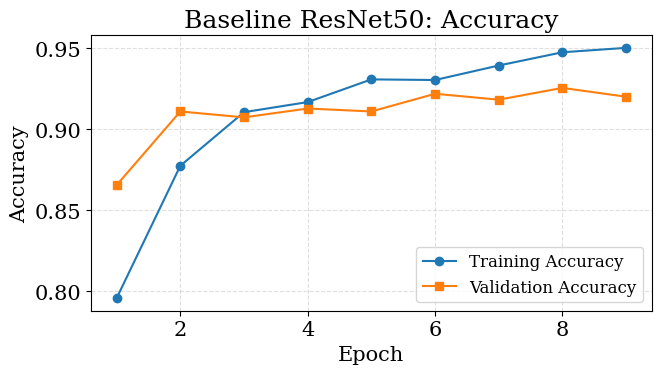

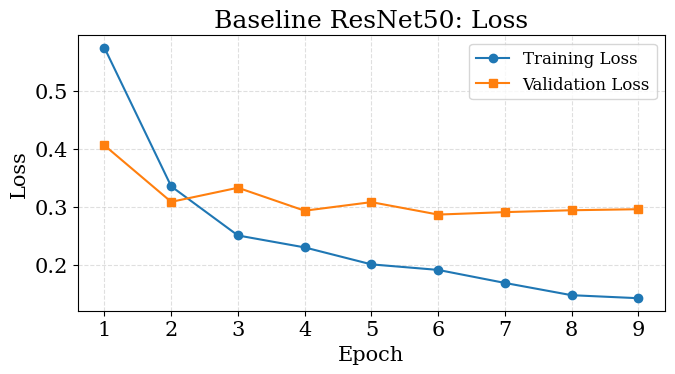

In [7]:

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "legend.fontsize": 12
})

history = baseline_history.history
epochs_range = range(1, len(history["loss"]) + 1)

# Accuracy plot
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(epochs_range, history["accuracy"], marker="o",
        label="Training Accuracy")
ax.plot(epochs_range, history["val_accuracy"], marker="s",
        label="Validation Accuracy")

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Baseline ResNet50: Accuracy")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(
    f"{OUTPUT_DIR}/baseline_accuracy.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

# Loss plot
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(epochs_range, history["loss"], marker="o",
        label="Training Loss")
ax.plot(epochs_range, history["val_loss"], marker="s",
        label="Validation Loss")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Baseline ResNet50: Loss")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(
    f"{OUTPUT_DIR}/baseline_loss.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()



In [8]:

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = baseline_model(images, training=False).numpy()

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(probabilities, axis=1))

baseline_accuracy = accuracy_score(y_true, y_pred)
baseline_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
baseline_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
baseline_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("BASELINE RESNET50 — TEST RESULTS")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

BASELINE RESNET50 — TEST RESULTS
Accuracy:  0.9093
Precision: 0.9173
Recall:    0.9086
F1-score:  0.9107

Classification Report:
              precision    recall  f1-score   support

   dandelion       0.86      0.98      0.92       112
       daisy       0.95      0.93      0.94        95
      tulips       0.87      0.92      0.89       134
  sunflowers       0.96      0.90      0.93       102
       roses       0.96      0.81      0.88       108

    accuracy                           0.91       551
   macro avg       0.92      0.91      0.91       551
weighted avg       0.91      0.91      0.91       551



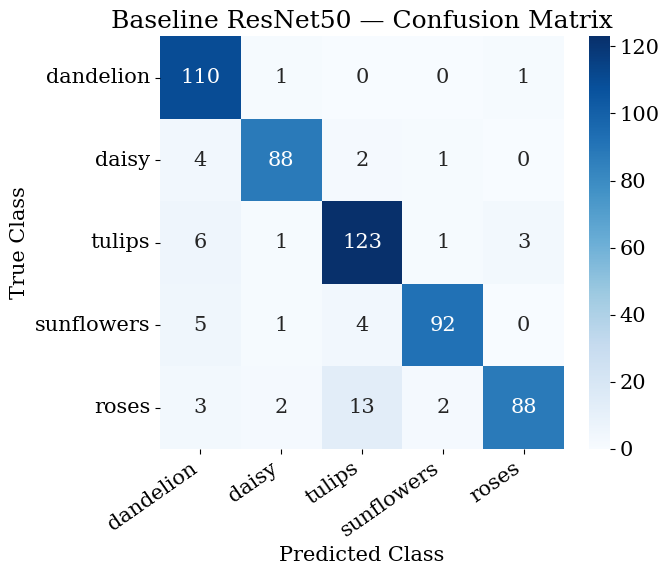

In [9]:

# BASELINE CONFUSION MATRIX

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title("Baseline ResNet50 — Confusion Matrix")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
fig.tight_layout()

fig.savefig(
    f"{OUTPUT_DIR}/baseline_confusion_matrix.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



In [10]:


def se_block(inputs, reduction=16, name="se"):
    channels = inputs.shape[-1]

    # Squeeze: summarize each channel spatially
    x = layers.GlobalAveragePooling2D(
        name=f"{name}_squeeze"
    )(inputs)

    # Excitation: learn channel importance
    x = layers.Dense(
        max(channels // reduction, 1),
        activation="relu",
        name=f"{name}_reduce"
    )(x)

    x = layers.Dense(
        channels,
        activation="sigmoid",
        name=f"{name}_expand"
    )(x)

    # Reshape channel weights and recalibrate feature maps
    x = layers.Reshape(
        (1, 1, channels),
        name=f"{name}_reshape"
    )(x)

    outputs = layers.Multiply(
        name=f"{name}_scale"
    )([inputs, x])

    return outputs

In [11]:
# RESNET50 + SE CHANNEL ATTENTION AT P3

def build_se_p3_model(
    learning_rate=BEST_LR,
    optimizer_name=BEST_OPTIMIZER,
    dropout_rate=BEST_DROPOUT
):
    # Load pretrained ResNet50
    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # P3 = output of conv4_x stage: 14 x 14 x 1024
    p3_output = base_model.get_layer("conv4_block6_out").output

    # Build feature extractor ending at P3
    backbone = Model(
        inputs=base_model.input,
        outputs=p3_output,
        name="resnet50_p3_backbone"
    )
    backbone.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = backbone(inputs, training=False)

    # Channel attention
    x = se_block(x, reduction=16, name="se_p3")

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="predictions"
    )(x)

    model = Model(inputs, outputs, name="ResNet50_SE_P3")

    if optimizer_name == "adam":
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    else:
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


se_p3_model = build_se_p3_model()

se_p3_model.summary()

print("\nP3 output shape:",
      se_p3_model.get_layer("resnet50_p3_backbone").output.shape)

Model: "ResNet50_SE_P3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_p3_backbo… │ (None, 14, 14,    │  8,589,184 │ input_layer_3[0]… │
│ (Functional)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_p3_squeeze       │ (None, 1024)      │          0 │ resnet50_p3_back… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_p3_reduce        │ (None, 64)        │     65,600 │ se_p3_squeeze[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_p3_expand        │ (None, 1024)      │     66,560 │ se_p3_reduce[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_p3_reshape       │ (None, 1, 1,      │          0 │ se_p3_expand[0][… │
│ (Reshape)           │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ se_p3_scale         │ (None, 14, 14,    │          0 │ resnet50_p3_back… │
│ (Multiply)          │ 1024)             │            │ se_p3_reshape[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1024)      │          0 │ se_p3_scale[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 1024)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions (Dense) │ (None, 5)         │      5,125 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,726,469 (33.29 MB)

 Trainable params: 137,285 (536.27 KB)

 Non-trainable params: 8,589,184 (32.77 MB)


P3 output shape: (None, 14, 14, 1024)


In [12]:

def build_se_p3_model():
    # Load pretrained ResNet50
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    # Extract P3: output of conv4_x (14 x 14 x 1024)
    p3_backbone = Model(
        inputs=base.input,
        outputs=base.get_layer("conv4_block6_out").output,
        name="p3_backbone"
    )

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Frozen pretrained feature extraction through P3
    x = p3_backbone(inputs, training=False)

    # Apply SE channel attention at P3
    x = se_block(x, reduction=16, name="se_p3")

    # Reuse the pretrained conv5_x stage, preserving residual connections
    shortcut = x

    y = base.get_layer("conv5_block1_1_conv")(x)
    y = base.get_layer("conv5_block1_1_bn")(y)
    y = base.get_layer("conv5_block1_1_relu")(y)
    y = base.get_layer("conv5_block1_2_conv")(y)
    y = base.get_layer("conv5_block1_2_bn")(y)
    y = base.get_layer("conv5_block1_2_relu")(y)
    y = base.get_layer("conv5_block1_3_conv")(y)
    y = base.get_layer("conv5_block1_3_bn")(y)

    shortcut = base.get_layer("conv5_block1_0_conv")(shortcut)
    shortcut = base.get_layer("conv5_block1_0_bn")(shortcut)

    x = base.get_layer("conv5_block1_add")([y, shortcut])
    x = base.get_layer("conv5_block1_out")(x)

    # Remaining identity residual blocks in conv5_x
    for block in [2, 3]:
        shortcut = x

        y = base.get_layer(f"conv5_block{block}_1_conv")(x)
        y = base.get_layer(f"conv5_block{block}_1_bn")(y)
        y = base.get_layer(f"conv5_block{block}_1_relu")(y)
        y = base.get_layer(f"conv5_block{block}_2_conv")(y)
        y = base.get_layer(f"conv5_block{block}_2_bn")(y)
        y = base.get_layer(f"conv5_block{block}_2_relu")(y)
        y = base.get_layer(f"conv5_block{block}_3_conv")(y)
        y = base.get_layer(f"conv5_block{block}_3_bn")(y)

        x = base.get_layer(f"conv5_block{block}_add")(
            [y, shortcut]
        )
        x = base.get_layer(f"conv5_block{block}_out")(x)

    # Classification head — same as the baseline
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(BEST_DROPOUT)(x)
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs, name="ResNet50_SE_P3")

    if BEST_OPTIMIZER == "adam":
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=BEST_LR
        )
    else:
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=BEST_LR,
            momentum=0.9
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


se_p3_model = build_se_p3_model()

print("SE P3 model created successfully!")
print("Input shape:", se_p3_model.input_shape)
print("Output shape:", se_p3_model.output_shape)
print("Total parameters:", f"{se_p3_model.count_params():,}")
print(
    "Trainable parameters:",
    f"{sum(tf.size(v).numpy() for v in se_p3_model.trainable_variables):,}"
)

SE P3 model created successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23,730,117
Trainable parameters: 142,405


In [13]:


se_p3_history = se_p3_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=2
        )
    ],
    verbose=2
)

Epoch 1/10
322/322 - 31s - 98ms/step - accuracy: 0.7446 - loss: 0.6859 - val_accuracy: 0.8618 - val_loss: 0.3700
Epoch 2/10
322/322 - 12s - 37ms/step - accuracy: 0.8610 - loss: 0.3970 - val_accuracy: 0.8855 - val_loss: 0.3020
Epoch 3/10
322/322 - 12s - 37ms/step - accuracy: 0.8867 - loss: 0.3134 - val_accuracy: 0.9073 - val_loss: 0.2694
Epoch 4/10
322/322 - 12s - 36ms/step - accuracy: 0.8996 - loss: 0.2770 - val_accuracy: 0.9164 - val_loss: 0.2515
Epoch 5/10
322/322 - 12s - 36ms/step - accuracy: 0.9163 - loss: 0.2427 - val_accuracy: 0.9164 - val_loss: 0.2411
Epoch 6/10
322/322 - 11s - 35ms/step - accuracy: 0.9311 - loss: 0.2063 - val_accuracy: 0.9182 - val_loss: 0.2440
Epoch 7/10
322/322 - 11s - 35ms/step - accuracy: 0.9272 - loss: 0.1962 - val_accuracy: 0.9109 - val_loss: 0.2494
Epoch 8/10
322/322 - 12s - 36ms/step - accuracy: 0.9358 - loss: 0.1716 - val_accuracy: 0.9182 - val_loss: 0.2307
Epoch 9/10
322/322 - 12s - 36ms/step - accuracy: 0.9447 - loss: 0.1596 - val_accuracy: 0.9091 - 

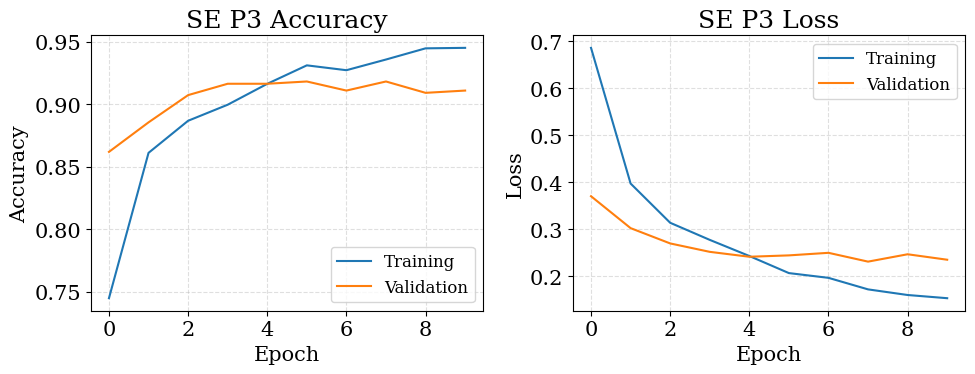

In [14]:


plt.rcParams["font.family"] = "serif"

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(se_p3_history.history["accuracy"], label="Training")
axes[0].plot(se_p3_history.history["val_accuracy"], label="Validation")
axes[0].set_title("SE P3 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(se_p3_history.history["loss"], label="Training")
axes[1].plot(se_p3_history.history["val_loss"], label="Validation")
axes[1].set_title("SE P3 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/se_p3_training_curves.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

In [15]:


y_true_se = []
y_pred_se = []

for images, labels in test_ds:
    predictions = se_p3_model(images, training=False).numpy()

    y_true_se.extend(
        np.argmax(labels.numpy(), axis=1)
    )
    y_pred_se.extend(
        np.argmax(predictions, axis=1)
    )

se_p3_metrics = {
    "Model": "ResNet50 + SE (P3)",
    "Accuracy": accuracy_score(y_true_se, y_pred_se),
    "Precision (Macro)": precision_score(
        y_true_se, y_pred_se, average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true_se, y_pred_se, average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true_se, y_pred_se, average="macro", zero_division=0
    )
}

print("SE P3 Test Metrics")
print("-" * 40)

for metric, value in se_p3_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(
    classification_report(
        y_true_se,
        y_pred_se,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

SE P3 Test Metrics
----------------------------------------
Accuracy: 0.9165
Precision (Macro): 0.9200
Recall (Macro): 0.9167
F1-score (Macro): 0.9169

Classification Report:

              precision    recall  f1-score   support

   dandelion       0.87      0.99      0.93       112
       daisy       0.98      0.88      0.93        95
      tulips       0.94      0.89      0.91       134
  sunflowers       0.91      0.93      0.92       102
       roses       0.91      0.89      0.90       108

    accuracy                           0.92       551
   macro avg       0.92      0.92      0.92       551
weighted avg       0.92      0.92      0.92       551



In [16]:


baseline_metrics = {
    "Model": "Baseline ResNet50",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision (Macro)": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}

comparison_df = pd.DataFrame([
    baseline_metrics,
    se_p3_metrics
])

display(comparison_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Baseline ResNet50,0.9093,0.9173,0.9086,0.9107
1,ResNet50 + SE (P3),0.9165,0.9200,0.9167,0.9169


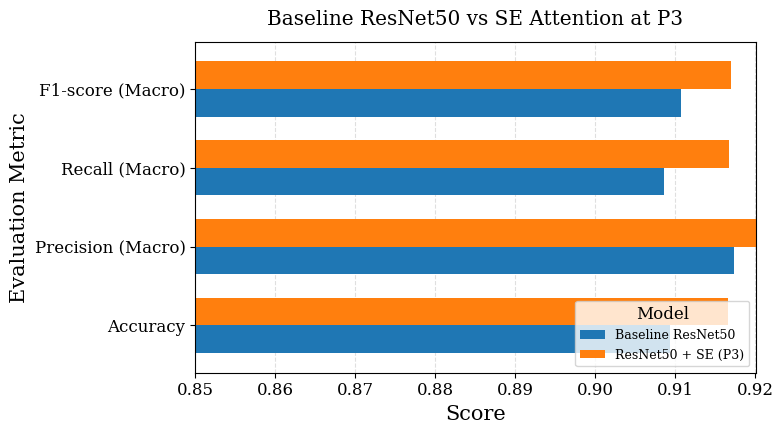

In [17]:

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 12

metrics_to_plot = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

plot_df = comparison_df.set_index("Model")[metrics_to_plot].T

fig, ax = plt.subplots(figsize=(8, 4.5))

plot_df.plot(
    kind="barh",
    ax=ax,
    width=0.7
)

ax.set_title("Baseline ResNet50 vs SE Attention at P3", pad=12)
ax.set_xlabel("Score")
ax.set_ylabel("Evaluation Metric")
ax.set_xlim(0.85, 0.92)
ax.legend(loc="lower right", fontsize=9, title="Model")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/baseline_vs_se_p3.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    f"{OUTPUT_DIR}/baseline_vs_se_p3.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [18]:

def spatial_attention_block(inputs, kernel_size=7, name="spatial_attention"):
    # Average and max pooling across channels
    avg_pool = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True),
        name=f"{name}_avg_pool"
    )(inputs)

    max_pool = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True),
        name=f"{name}_max_pool"
    )(inputs)

    # Combine spatial descriptors
    concat = layers.Concatenate(
        axis=-1,
        name=f"{name}_concat"
    )([avg_pool, max_pool])

    # Learn spatial attention weights
    attention_map = layers.Conv2D(
        filters=1,
        kernel_size=kernel_size,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        name=f"{name}_conv"
    )(concat)

    # Apply spatial attention
    output = layers.Multiply(
        name=f"{name}_scale"
    )([inputs, attention_map])

    return output

In [19]:

def build_spatial_p3_model(kernel_size=7):
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    p3_backbone = Model(
        inputs=base.input,
        outputs=base.get_layer("conv4_block6_out").output,
        name="spatial_p3_backbone"
    )

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = p3_backbone(inputs, training=False)

    # Spatial attention at P3 (14 x 14 x 1024)
    x = spatial_attention_block(
        x,
        kernel_size=kernel_size,
        name="spatial_p3"
    )

    # Rebuild conv5_x with the pretrained residual layers
    shortcut = x

    y = base.get_layer("conv5_block1_1_conv")(x)
    y = base.get_layer("conv5_block1_1_bn")(y)
    y = base.get_layer("conv5_block1_1_relu")(y)
    y = base.get_layer("conv5_block1_2_conv")(y)
    y = base.get_layer("conv5_block1_2_bn")(y)
    y = base.get_layer("conv5_block1_2_relu")(y)
    y = base.get_layer("conv5_block1_3_conv")(y)
    y = base.get_layer("conv5_block1_3_bn")(y)

    shortcut = base.get_layer("conv5_block1_0_conv")(shortcut)
    shortcut = base.get_layer("conv5_block1_0_bn")(shortcut)

    x = base.get_layer("conv5_block1_add")([y, shortcut])
    x = base.get_layer("conv5_block1_out")(x)

    for block in [2, 3]:
        shortcut = x

        y = base.get_layer(f"conv5_block{block}_1_conv")(x)
        y = base.get_layer(f"conv5_block{block}_1_bn")(y)
        y = base.get_layer(f"conv5_block{block}_1_relu")(y)
        y = base.get_layer(f"conv5_block{block}_2_conv")(y)
        y = base.get_layer(f"conv5_block{block}_2_bn")(y)
        y = base.get_layer(f"conv5_block{block}_2_relu")(y)
        y = base.get_layer(f"conv5_block{block}_3_conv")(y)
        y = base.get_layer(f"conv5_block{block}_3_bn")(y)

        x = base.get_layer(f"conv5_block{block}_add")(
            [y, shortcut]
        )
        x = base.get_layer(f"conv5_block{block}_out")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(BEST_DROPOUT)(x)
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs, name="ResNet50_Spatial_P3")

    if BEST_OPTIMIZER == "adam":
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=BEST_LR
        )
    else:
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=BEST_LR,
            momentum=0.9
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


spatial_p3_model = build_spatial_p3_model(kernel_size=7)

print("Spatial P3 model created!")
print("Input shape:", spatial_p3_model.input_shape)
print("Output shape:", spatial_p3_model.output_shape)
print("Total parameters:", f"{spatial_p3_model.count_params():,}")
print(
    "Trainable parameters:",
    f"{sum(tf.size(v).numpy() for v in spatial_p3_model.trainable_variables):,}"
)

Spatial P3 model created!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23,598,055
Trainable parameters: 10,343


In [20]:


spatial_p3_history = spatial_p3_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=2
        )
    ],
    verbose=2
)

Epoch 1/10
322/322 - 32s - 99ms/step - accuracy: 0.7341 - loss: 0.6957 - val_accuracy: 0.8727 - val_loss: 0.3532
Epoch 2/10
322/322 - 12s - 36ms/step - accuracy: 0.8821 - loss: 0.3369 - val_accuracy: 0.8818 - val_loss: 0.3633
Epoch 3/10
322/322 - 12s - 37ms/step - accuracy: 0.9035 - loss: 0.2724 - val_accuracy: 0.9000 - val_loss: 0.3039
Epoch 4/10
322/322 - 12s - 37ms/step - accuracy: 0.9089 - loss: 0.2391 - val_accuracy: 0.9073 - val_loss: 0.3016
Epoch 5/10
322/322 - 12s - 36ms/step - accuracy: 0.9257 - loss: 0.2130 - val_accuracy: 0.8945 - val_loss: 0.3221
Epoch 6/10
322/322 - 12s - 36ms/step - accuracy: 0.9249 - loss: 0.2134 - val_accuracy: 0.9200 - val_loss: 0.2573
Epoch 7/10
322/322 - 12s - 36ms/step - accuracy: 0.9401 - loss: 0.1725 - val_accuracy: 0.9236 - val_loss: 0.2690
Epoch 8/10
322/322 - 12s - 36ms/step - accuracy: 0.9490 - loss: 0.1480 - val_accuracy: 0.9236 - val_loss: 0.2630
Epoch 9/10
322/322 - 12s - 36ms/step - accuracy: 0.9443 - loss: 0.1500 - val_accuracy: 0.9273 - 

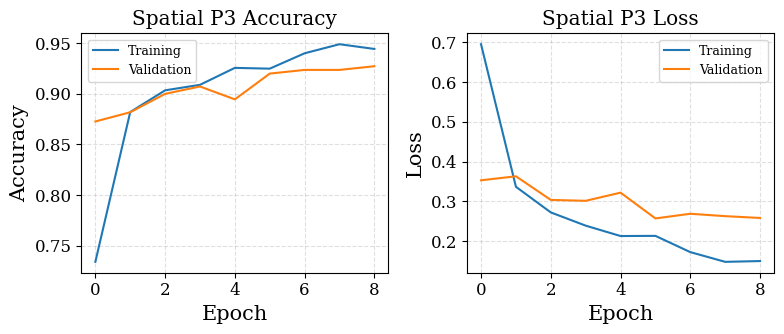

In [21]:


plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 12

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

axes[0].plot(
    spatial_p3_history.history["accuracy"],
    label="Training"
)
axes[0].plot(
    spatial_p3_history.history["val_accuracy"],
    label="Validation"
)
axes[0].set_title("Spatial P3 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(
    spatial_p3_history.history["loss"],
    label="Training"
)
axes[1].plot(
    spatial_p3_history.history["val_loss"],
    label="Validation"
)
axes[1].set_title("Spatial P3 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/spatial_p3_training_curves.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    f"{OUTPUT_DIR}/spatial_p3_training_curves.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [22]:


y_true_spatial = []
y_pred_spatial = []

for images, labels in test_ds:
    predictions = spatial_p3_model(images, training=False).numpy()

    y_true_spatial.extend(
        np.argmax(labels.numpy(), axis=1)
    )
    y_pred_spatial.extend(
        np.argmax(predictions, axis=1)
    )

spatial_p3_metrics = {
    "Model": "ResNet50 + Spatial (P3)",
    "Accuracy": accuracy_score(y_true_spatial, y_pred_spatial),
    "Precision (Macro)": precision_score(
        y_true_spatial, y_pred_spatial,
        average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true_spatial, y_pred_spatial,
        average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true_spatial, y_pred_spatial,
        average="macro", zero_division=0
    )
}

print("Spatial Attention P3 — Test Results")
print("-" * 45)

for metric, value in spatial_p3_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true_spatial,
    y_pred_spatial,
    target_names=CLASS_NAMES,
    zero_division=0
))

Spatial Attention P3 — Test Results
---------------------------------------------
Accuracy: 0.9201
Precision (Macro): 0.9248
Recall (Macro): 0.9185
F1-score (Macro): 0.9204

Classification Report:

              precision    recall  f1-score   support

   dandelion       0.88      0.96      0.91       112
       daisy       0.96      0.89      0.92        95
      tulips       0.90      0.94      0.92       134
  sunflowers       0.92      0.94      0.93       102
       roses       0.97      0.86      0.91       108

    accuracy                           0.92       551
   macro avg       0.92      0.92      0.92       551
weighted avg       0.92      0.92      0.92       551



In [23]:

comparison_df = pd.DataFrame([
    baseline_metrics,
    se_p3_metrics,
    spatial_p3_metrics
])

display(comparison_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Baseline ResNet50,0.9093,0.9173,0.9086,0.9107
1,ResNet50 + SE (P3),0.9165,0.9200,0.9167,0.9169
2,ResNet50 + Spatial (P3),0.9201,0.9248,0.9185,0.9204


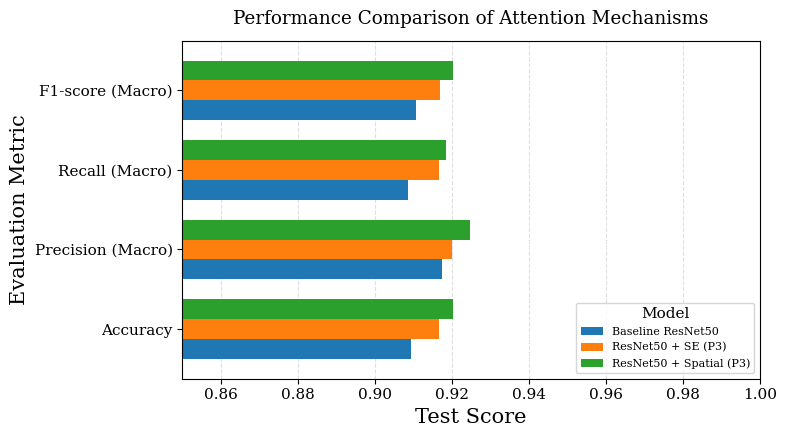

In [24]:

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 11

metrics_to_plot = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

plot_df = comparison_df.set_index("Model")[metrics_to_plot].T

fig, ax = plt.subplots(figsize=(8, 4.5))

plot_df.plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.set_title(
    "Performance Comparison of Attention Mechanisms",
    pad=12
)
ax.set_xlabel("Test Score")
ax.set_ylabel("Evaluation Metric")
ax.set_xlim(0.85, 1.0)
ax.legend(
    title="Model",
    loc="lower right",
    fontsize=8
)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/baseline_se_spatial_comparison.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    f"{OUTPUT_DIR}/baseline_se_spatial_comparison.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

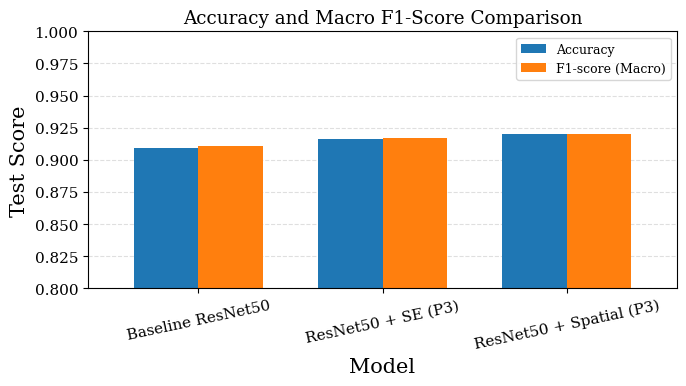

In [25]:

key_metrics = ["Accuracy", "F1-score (Macro)"]

key_df = comparison_df.set_index("Model")[key_metrics]

ax = key_df.plot(
    kind="bar",
    figsize=(7, 4),
    width=0.7
)

ax.set_title("Accuracy and Macro F1-Score Comparison")
ax.set_ylabel("Test Score")
ax.set_xlabel("Model")
ax.set_ylim(0.80, 1.0)
ax.tick_params(axis="x", labelrotation=12)
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/key_metrics_comparison.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    f"{OUTPUT_DIR}/key_metrics_comparison.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [26]:



def cbam_block(inputs, reduction=16, spatial_kernel=7, name="cbam"):
    channels = int(inputs.shape[-1])


    hidden_units = max(channels // reduction, 1)

    shared_dense1 = layers.Dense(
        hidden_units,
        activation="relu",
        name=f"{name}_channel_reduce"
    )

    shared_dense2 = layers.Dense(
        channels,
        name=f"{name}_channel_expand"
    )

    avg_pool = layers.GlobalAveragePooling2D(
        name=f"{name}_channel_avg_pool"
    )(inputs)

    max_pool = layers.GlobalMaxPooling2D(
        name=f"{name}_channel_max_pool"
    )(inputs)

    avg_out = shared_dense2(shared_dense1(avg_pool))
    max_out = shared_dense2(shared_dense1(max_pool))

    channel_weights = layers.Activation(
        "sigmoid",
        name=f"{name}_channel_sigmoid"
    )(
        layers.Add(name=f"{name}_channel_add")(
            [avg_out, max_out]
        )
    )

    channel_weights = layers.Reshape(
        (1, 1, channels),
        name=f"{name}_channel_reshape"
    )(channel_weights)

    channel_refined = layers.Multiply(
        name=f"{name}_channel_refined"
    )([inputs, channel_weights])

    # --------------------------------------------------------
    # 2. SPATIAL ATTENTION
    # Average and max across channels produce spatial maps.
    # A convolution generates the spatial attention weights.
    # --------------------------------------------------------
    avg_spatial = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True),
        name=f"{name}_spatial_avg"
    )(channel_refined)

    max_spatial = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True),
        name=f"{name}_spatial_max"
    )(channel_refined)

    spatial_concat = layers.Concatenate(
        axis=-1,
        name=f"{name}_spatial_concat"
    )([avg_spatial, max_spatial])

    spatial_weights = layers.Conv2D(
        filters=1,
        kernel_size=spatial_kernel,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        name=f"{name}_spatial_conv"
    )(spatial_concat)

    output = layers.Multiply(
        name=f"{name}_output"
    )([channel_refined, spatial_weights])

    return output


print("CBAM block defined successfully.")


CBAM block defined successfully.


In [27]:

def build_cbam_p3_model():
    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    # P3: output after conv4_x
    p3_backbone = tf.keras.Model(
        base.input,
        base.get_layer("conv4_block6_out").output
    )

    # Insert CBAM at P3
    x = cbam_block(
        p3_backbone.output,
        reduction=16,
        spatial_kernel=7,
        name="cbam_p3"
    )

    # P4 — conv5_block1 (projection shortcut)
    shortcut = base.get_layer("conv5_block1_0_conv")(x)
    shortcut = base.get_layer("conv5_block1_0_bn")(shortcut)

    x = base.get_layer("conv5_block1_1_conv")(x)
    x = base.get_layer("conv5_block1_1_bn")(x)
    x = base.get_layer("conv5_block1_1_relu")(x)

    x = base.get_layer("conv5_block1_2_conv")(x)
    x = base.get_layer("conv5_block1_2_bn")(x)
    x = base.get_layer("conv5_block1_2_relu")(x)

    # IMPORTANT: third convolution expands channels to 2048
    x = base.get_layer("conv5_block1_3_conv")(x)
    x = base.get_layer("conv5_block1_3_bn")(x)

    x = layers.Add(name="cbam_p4_block1_add")([x, shortcut])
    x = base.get_layer("conv5_block1_out")(x)

    # conv5_block2 (identity shortcut)
    shortcut = x

    x = base.get_layer("conv5_block2_1_conv")(x)
    x = base.get_layer("conv5_block2_1_bn")(x)
    x = base.get_layer("conv5_block2_1_relu")(x)

    x = base.get_layer("conv5_block2_2_conv")(x)
    x = base.get_layer("conv5_block2_2_bn")(x)
    x = base.get_layer("conv5_block2_2_relu")(x)

    x = base.get_layer("conv5_block2_3_conv")(x)
    x = base.get_layer("conv5_block2_3_bn")(x)

    x = layers.Add(name="cbam_p4_block2_add")([x, shortcut])
    x = base.get_layer("conv5_block2_out")(x)

    # conv5_block3 (identity shortcut)
    shortcut = x

    x = base.get_layer("conv5_block3_1_conv")(x)
    x = base.get_layer("conv5_block3_1_bn")(x)
    x = base.get_layer("conv5_block3_1_relu")(x)

    x = base.get_layer("conv5_block3_2_conv")(x)
    x = base.get_layer("conv5_block3_2_bn")(x)
    x = base.get_layer("conv5_block3_2_relu")(x)

    x = base.get_layer("conv5_block3_3_conv")(x)
    x = base.get_layer("conv5_block3_3_bn")(x)

    x = layers.Add(name="cbam_p4_block3_add")([x, shortcut])
    x = base.get_layer("conv5_block3_out")(x)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(BEST_DROPOUT)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="flower_predictions"
    )(x)

    model = tf.keras.Model(
        inputs=base.input,
        outputs=outputs,
        name="ResNet50_CBAM_P3"
    )

    if "sgd" in str(BEST_OPTIMIZER).lower():
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=BEST_LR,
            momentum=0.9
        )
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=BEST_LR
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cbam_p3_model = build_cbam_p3_model()

print("CBAM P3 model built successfully!")
print("Input:", cbam_p3_model.input_shape)
print("Output:", cbam_p3_model.output_shape)
print("Total parameters:", cbam_p3_model.count_params())
print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in cbam_p3_model.trainable_weights
    )
)


CBAM P3 model built successfully!
Input: (None, 224, 224, 3)
Output: (None, 5)
Total parameters: 23730215
Trainable parameters: 142503


In [28]:

cbam_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

cbam_p3_history = cbam_p3_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=cbam_callbacks,
    verbose=2
)

Epoch 1/10
322/322 - 33s - 101ms/step - accuracy: 0.7692 - loss: 0.6211 - val_accuracy: 0.8600 - val_loss: 0.3521
Epoch 2/10
322/322 - 12s - 37ms/step - accuracy: 0.8762 - loss: 0.3407 - val_accuracy: 0.9055 - val_loss: 0.3019
Epoch 3/10
322/322 - 12s - 37ms/step - accuracy: 0.9155 - loss: 0.2498 - val_accuracy: 0.9073 - val_loss: 0.2696
Epoch 4/10
322/322 - 12s - 37ms/step - accuracy: 0.9253 - loss: 0.2210 - val_accuracy: 0.9182 - val_loss: 0.2586
Epoch 5/10
322/322 - 12s - 37ms/step - accuracy: 0.9358 - loss: 0.1901 - val_accuracy: 0.9073 - val_loss: 0.2473
Epoch 6/10
322/322 - 12s - 36ms/step - accuracy: 0.9416 - loss: 0.1671 - val_accuracy: 0.9036 - val_loss: 0.2795
Epoch 7/10
322/322 - 11s - 36ms/step - accuracy: 0.9385 - loss: 0.1646 - val_accuracy: 0.9109 - val_loss: 0.2709
Epoch 8/10
322/322 - 12s - 36ms/step - accuracy: 0.9498 - loss: 0.1472 - val_accuracy: 0.9145 - val_loss: 0.2587


In [29]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true_cbam = []
y_pred_cbam = []

for images, labels in test_ds:
    predictions = cbam_p3_model(images, training=False).numpy()

    y_true_cbam.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_cbam.extend(np.argmax(predictions, axis=1))

y_true_cbam = np.array(y_true_cbam)
y_pred_cbam = np.array(y_pred_cbam)

cbam_p3_metrics = {
    "Model": "ResNet50 + CBAM (P3)",
    "Accuracy": accuracy_score(y_true_cbam, y_pred_cbam),
    "Precision (Macro)": precision_score(
        y_true_cbam, y_pred_cbam, average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true_cbam, y_pred_cbam, average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true_cbam, y_pred_cbam, average="macro", zero_division=0
    )
}

print("CBAM P3 Test Metrics")
print("-" * 40)

for metric, value in cbam_p3_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true_cbam,
    y_pred_cbam,
    target_names=CLASS_NAMES,
    zero_division=0
))

CBAM P3 Test Metrics
----------------------------------------
Accuracy: 0.8966
Precision (Macro): 0.9040
Recall (Macro): 0.8958
F1-score (Macro): 0.8970

Classification Report:

              precision    recall  f1-score   support

   dandelion       0.83      0.97      0.90       112
       daisy       0.98      0.84      0.90        95
      tulips       0.89      0.89      0.89       134
  sunflowers       0.91      0.96      0.93       102
       roses       0.92      0.81      0.86       108

    accuracy                           0.90       551
   macro avg       0.90      0.90      0.90       551
weighted avg       0.90      0.90      0.90       551



In [30]:

cbam_row = {
    "Model": cbam_p3_metrics["Model"],
    "Accuracy": cbam_p3_metrics["Accuracy"],
    "Precision (Macro)": cbam_p3_metrics["Precision (Macro)"],
    "Recall (Macro)": cbam_p3_metrics["Recall (Macro)"],
    "F1-score (Macro)": cbam_p3_metrics["F1-score (Macro)"]
}

comparison_df = comparison_df[
    comparison_df["Model"] != "ResNet50 + CBAM (P3)"
]

comparison_df = __import__("pandas").concat(
    [comparison_df, __import__("pandas").DataFrame([cbam_row])],
    ignore_index=True
)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-score (Macro)": "{:.4f}"
    })
)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Baseline ResNet50,0.9093,0.9173,0.9086,0.9107
1,ResNet50 + SE (P3),0.9165,0.9200,0.9167,0.9169
2,ResNet50 + Spatial (P3),0.9201,0.9248,0.9185,0.9204
3,ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970


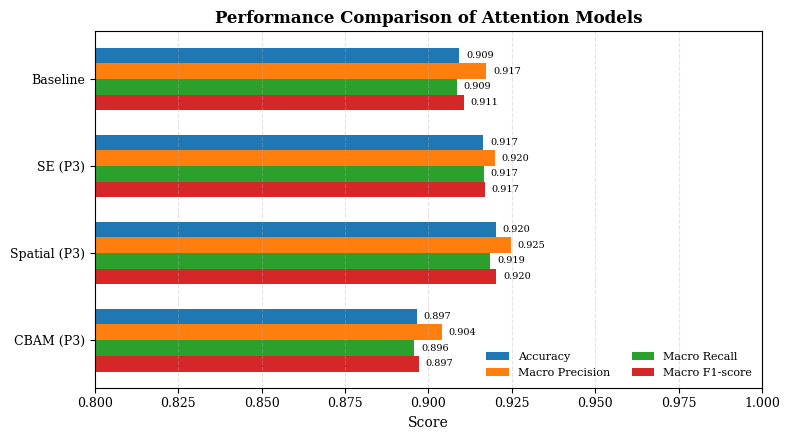

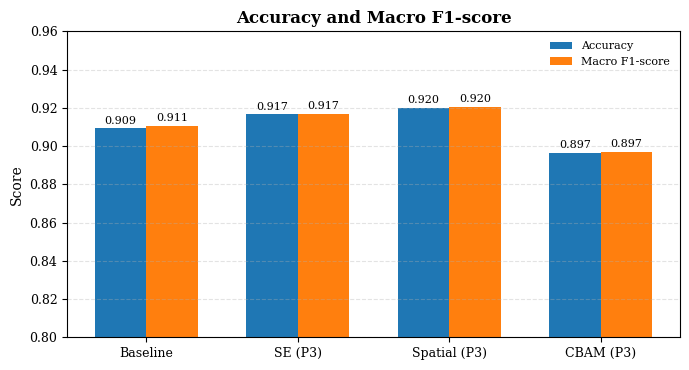

Saved figures in: /kaggle/working/lab8_plots
 - four_model_performance.eps
 - four_model_performance.svg
 - accuracy_f1_comparison.eps
 - accuracy_f1_comparison.svg


In [31]:

import os
import matplotlib.pyplot as plt
import numpy as np

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use Times New Roman if available
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["legend.fontsize"] = 8
plt.rcParams["axes.titleweight"] = "bold"

models = comparison_df["Model"].tolist()

metrics = {
    "Accuracy": comparison_df["Accuracy"].to_numpy(),
    "Macro Precision": comparison_df["Precision (Macro)"].to_numpy(),
    "Macro Recall": comparison_df["Recall (Macro)"].to_numpy(),
    "Macro F1-score": comparison_df["F1-score (Macro)"].to_numpy()
}

# Short labels to prevent crowding
short_names = [
    "Baseline",
    "SE (P3)",
    "Spatial (P3)",
    "CBAM (P3)"
]


fig, ax = plt.subplots(figsize=(8, 4.5))

y = np.arange(len(short_names))
bar_height = 0.18
offsets = np.linspace(-1.5 * bar_height, 1.5 * bar_height, 4)

for (metric_name, values), offset in zip(metrics.items(), offsets):
    bars = ax.barh(
        y + offset,
        values,
        height=bar_height,
        label=metric_name
    )

    for bar, value in zip(bars, values):
        ax.text(
            value + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=7
        )

ax.set_yticks(y)
ax.set_yticklabels(short_names)
ax.set_xlim(0.80, 1.00)
ax.set_xlabel("Score")
ax.set_title("Performance Comparison of Attention Models")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.legend(loc="lower right", ncol=2, frameon=False)
ax.invert_yaxis()

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "four_model_performance.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


fig, ax = plt.subplots(figsize=(7, 3.8))

x = np.arange(len(short_names))
width = 0.34

bars1 = ax.bar(
    x - width / 2,
    comparison_df["Accuracy"],
    width,
    label="Accuracy"
)
bars2 = ax.bar(
    x + width / 2,
    comparison_df["F1-score (Macro)"],
    width,
    label="Macro F1-score"
)

ax.bar_label(bars1, fmt="%.3f", padding=2, fontsize=8)
ax.bar_label(bars2, fmt="%.3f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(short_names)
ax.set_ylim(0.80, 0.96)
ax.set_ylabel("Score")
ax.set_title("Accuracy and Macro F1-score")
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.35)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "accuracy_f1_comparison.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved figures in:", OUTPUT_DIR)
print(" - four_model_performance.eps")
print(" - four_model_performance.svg")
print(" - accuracy_f1_comparison.eps")
print(" - accuracy_f1_comparison.svg")

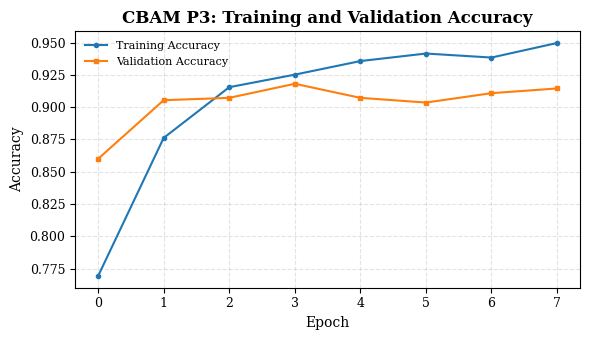

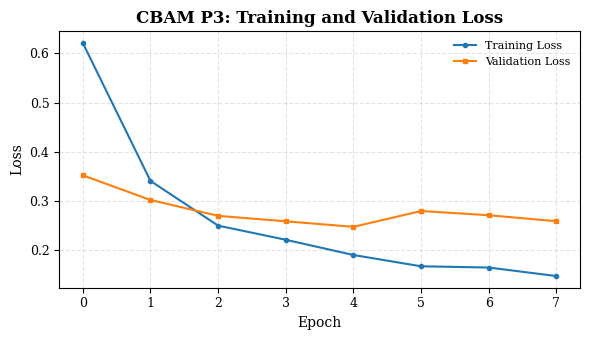

CBAM training curves saved to: /kaggle/working/lab8_plots


In [32]:

import os
import matplotlib.pyplot as plt

os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 10

# Accuracy curve
fig, ax = plt.subplots(figsize=(6, 3.5))

ax.plot(
    cbam_p3_history.history["accuracy"],
    label="Training Accuracy",
    marker="o",
    markersize=3
)
ax.plot(
    cbam_p3_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="s",
    markersize=3
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("CBAM P3: Training and Validation Accuracy")
ax.legend(frameon=False)
ax.grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "cbam_p3_accuracy.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Loss curve
fig, ax = plt.subplots(figsize=(6, 3.5))

ax.plot(
    cbam_p3_history.history["loss"],
    label="Training Loss",
    marker="o",
    markersize=3
)
ax.plot(
    cbam_p3_history.history["val_loss"],
    label="Validation Loss",
    marker="s",
    markersize=3
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("CBAM P3: Training and Validation Loss")
ax.legend(frameon=False)
ax.grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "cbam_p3_loss.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("CBAM training curves saved to:", OUTPUT_DIR)

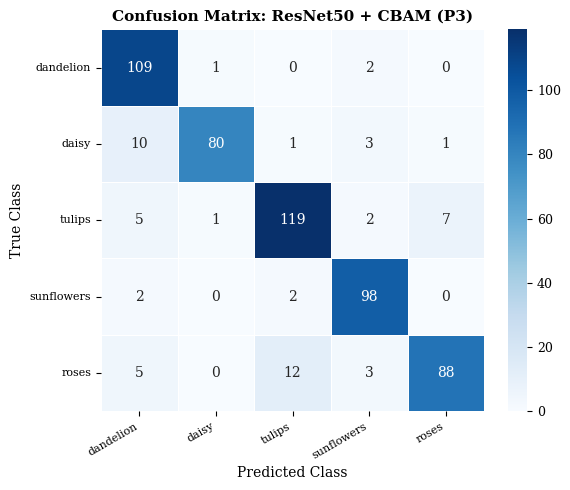

Saved CBAM confusion matrix in: /kaggle/working/lab8_plots


In [33]:


import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_cbam = confusion_matrix(
    y_true_cbam,
    y_pred_cbam
)

plt.rcParams["font.family"] = "serif"

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm_cbam,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5,
    ax=ax
)

ax.set_xlabel("Predicted Class", fontsize=10)
ax.set_ylabel("True Class", fontsize=10)
ax.set_title("Confusion Matrix: ResNet50 + CBAM (P3)", fontsize=11)

plt.xticks(rotation=30, ha="right", fontsize=8)
plt.yticks(rotation=0, fontsize=8)

fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "cbam_p3_confusion_matrix.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved CBAM confusion matrix in:", OUTPUT_DIR)

In [34]:

def build_cbam_p2_model():
    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    # P2: output of conv3_x
    p2_backbone = tf.keras.Model(
        base.input,
        base.get_layer("conv3_block4_out").output
    )

    # Insert CBAM at P2
    x = cbam_block(
        p2_backbone.output,
        reduction=16,
        spatial_kernel=7,
        name="cbam_p2"
    )

    # Continue through pretrained conv4_x (P3)
    for block in range(1, 7):
        prefix = f"conv4_block{block}"

        if block == 1:
            shortcut = base.get_layer(prefix + "_0_conv")(x)
            shortcut = base.get_layer(prefix + "_0_bn")(shortcut)

        x = base.get_layer(prefix + "_1_conv")(x)
        x = base.get_layer(prefix + "_1_bn")(x)
        x = base.get_layer(prefix + "_1_relu")(x)

        x = base.get_layer(prefix + "_2_conv")(x)
        x = base.get_layer(prefix + "_2_bn")(x)
        x = base.get_layer(prefix + "_2_relu")(x)

        x = base.get_layer(prefix + "_3_conv")(x)
        x = base.get_layer(prefix + "_3_bn")(x)

        if block == 1:
            x = layers.Add(name="cbam_p2_conv4_block1_add")(
                [x, shortcut]
            )
        else:
            # Identity shortcut is the block input.
            pass

        if block == 1:
            x = base.get_layer(prefix + "_out")(x)
        else:
            # For identity blocks, preserve the input before each block.
            # This branch is replaced by the corrected implementation below.
            raise RuntimeError("Use Cell 34B for the residual-stage implementation.")

    return x

In [35]:

def build_cbam_p2_model():
    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    # P2 output: conv3_x
    p2 = tf.keras.Model(
        inputs=base.input,
        outputs=base.get_layer("conv3_block4_out").output
    )

    x = cbam_block(
        p2.output,
        reduction=16,
        spatial_kernel=7,
        name="cbam_p2"
    )

    # Continue through conv4_x (P3)
    for block in range(1, 7):
        prefix = f"conv4_block{block}"
        shortcut_input = x

        if block == 1:
            shortcut = base.get_layer(prefix + "_0_conv")(x)
            shortcut = base.get_layer(prefix + "_0_bn")(shortcut)
        else:
            shortcut = shortcut_input

        x = base.get_layer(prefix + "_1_conv")(x)
        x = base.get_layer(prefix + "_1_bn")(x)
        x = base.get_layer(prefix + "_1_relu")(x)

        x = base.get_layer(prefix + "_2_conv")(x)
        x = base.get_layer(prefix + "_2_bn")(x)
        x = base.get_layer(prefix + "_2_relu")(x)

        x = base.get_layer(prefix + "_3_conv")(x)
        x = base.get_layer(prefix + "_3_bn")(x)

        x = layers.Add(name=f"cbam_p2_{prefix}_add")(
            [x, shortcut]
        )
        x = base.get_layer(prefix + "_out")(x)

    # Continue through conv5_x (P4)
    for block in range(1, 4):
        prefix = f"conv5_block{block}"
        shortcut_input = x

        if block == 1:
            shortcut = base.get_layer(prefix + "_0_conv")(x)
            shortcut = base.get_layer(prefix + "_0_bn")(shortcut)
        else:
            shortcut = shortcut_input

        x = base.get_layer(prefix + "_1_conv")(x)
        x = base.get_layer(prefix + "_1_bn")(x)
        x = base.get_layer(prefix + "_1_relu")(x)

        x = base.get_layer(prefix + "_2_conv")(x)
        x = base.get_layer(prefix + "_2_bn")(x)
        x = base.get_layer(prefix + "_2_relu")(x)

        x = base.get_layer(prefix + "_3_conv")(x)
        x = base.get_layer(prefix + "_3_bn")(x)

        x = layers.Add(name=f"cbam_p2_{prefix}_add")(
            [x, shortcut]
        )
        x = base.get_layer(prefix + "_out")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(BEST_DROPOUT)(x)
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs=base.input,
        outputs=outputs,
        name="ResNet50_CBAM_P2"
    )

    if "sgd" in str(BEST_OPTIMIZER).lower():
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=BEST_LR,
            momentum=0.9
        )
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=BEST_LR
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cbam_p2_model = build_cbam_p2_model()

print("CBAM P2 model built successfully!")
print("Input shape:", cbam_p2_model.input_shape)
print("Output shape:", cbam_p2_model.output_shape)
print("Total parameters:", cbam_p2_model.count_params())
print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in cbam_p2_model.trainable_weights
    )
)

CBAM P2 model built successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23631367
Trainable parameters: 43655


In [36]:

cbam_p2_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

cbam_p2_history = cbam_p2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=cbam_p2_callbacks,
    verbose=2
)

Epoch 1/10
322/322 - 36s - 111ms/step - accuracy: 0.6882 - loss: 0.8409 - val_accuracy: 0.8800 - val_loss: 0.3475
Epoch 2/10
322/322 - 15s - 45ms/step - accuracy: 0.8626 - loss: 0.3849 - val_accuracy: 0.8891 - val_loss: 0.3327
Epoch 3/10
322/322 - 15s - 45ms/step - accuracy: 0.8918 - loss: 0.3044 - val_accuracy: 0.8891 - val_loss: 0.2929
Epoch 4/10
322/322 - 14s - 44ms/step - accuracy: 0.9046 - loss: 0.2593 - val_accuracy: 0.9164 - val_loss: 0.2914
Epoch 5/10
322/322 - 14s - 44ms/step - accuracy: 0.9206 - loss: 0.2168 - val_accuracy: 0.8964 - val_loss: 0.2859
Epoch 6/10
322/322 - 14s - 43ms/step - accuracy: 0.9151 - loss: 0.2411 - val_accuracy: 0.9073 - val_loss: 0.2820
Epoch 7/10
322/322 - 14s - 44ms/step - accuracy: 0.9272 - loss: 0.1921 - val_accuracy: 0.9218 - val_loss: 0.2446
Epoch 8/10
322/322 - 14s - 44ms/step - accuracy: 0.9439 - loss: 0.1654 - val_accuracy: 0.9200 - val_loss: 0.2450
Epoch 9/10
322/322 - 14s - 44ms/step - accuracy: 0.9432 - loss: 0.1478 - val_accuracy: 0.9164 -

In [37]:

# CELL 36 — EVALUATE RESNET50 + CBAM AT P2

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true_cbam_p2 = []
y_pred_cbam_p2 = []

for images, labels in test_ds:
    predictions = cbam_p2_model(images, training=False).numpy()

    y_true_cbam_p2.extend(
        np.argmax(labels.numpy(), axis=1)
    )
    y_pred_cbam_p2.extend(
        np.argmax(predictions, axis=1)
    )

y_true_cbam_p2 = np.array(y_true_cbam_p2)
y_pred_cbam_p2 = np.array(y_pred_cbam_p2)

cbam_p2_metrics = {
    "Model": "ResNet50 + CBAM (P2)",
    "Accuracy": accuracy_score(
        y_true_cbam_p2, y_pred_cbam_p2
    ),
    "Precision (Macro)": precision_score(
        y_true_cbam_p2, y_pred_cbam_p2,
        average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true_cbam_p2, y_pred_cbam_p2,
        average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true_cbam_p2, y_pred_cbam_p2,
        average="macro", zero_division=0
    )
}

print("CBAM P2 Test Metrics")
print("-" * 40)

for metric, value in cbam_p2_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true_cbam_p2,
    y_pred_cbam_p2,
    target_names=CLASS_NAMES,
    zero_division=0
))

CBAM P2 Test Metrics
----------------------------------------
Accuracy: 0.9093
Precision (Macro): 0.9173
Recall (Macro): 0.9071
F1-score (Macro): 0.9099

Classification Report:

              precision    recall  f1-score   support

   dandelion       0.87      0.97      0.92       112
       daisy       0.97      0.89      0.93        95
      tulips       0.86      0.94      0.90       134
  sunflowers       0.94      0.92      0.93       102
       roses       0.95      0.81      0.87       108

    accuracy                           0.91       551
   macro avg       0.92      0.91      0.91       551
weighted avg       0.91      0.91      0.91       551



In [38]:

# CELL 37 — RESNET50 + CBAM AT P4


def build_cbam_p4_model():
    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    # P4: output of conv5_x
    p4_backbone = tf.keras.Model(
        inputs=base.input,
        outputs=base.get_layer("conv5_block3_out").output
    )

    # Apply channel + spatial attention at P4
    x = cbam_block(
        p4_backbone.output,
        reduction=16,
        spatial_kernel=7,
        name="cbam_p4"
    )

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(BEST_DROPOUT)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs=base.input,
        outputs=outputs,
        name="ResNet50_CBAM_P4"
    )

    if "sgd" in str(BEST_OPTIMIZER).lower():
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=BEST_LR,
            momentum=0.9
        )
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=BEST_LR
        )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cbam_p4_model = build_cbam_p4_model()

print("CBAM P4 model built successfully!")
print("Input shape:", cbam_p4_model.input_shape)
print("Output shape:", cbam_p4_model.output_shape)
print("Total parameters:", cbam_p4_model.count_params())
print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in cbam_p4_model.trainable_weights
    )
)

CBAM P4 model built successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 24124519
Trainable parameters: 536807


In [39]:

cbam_p4_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

cbam_p4_history = cbam_p4_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=cbam_p4_callbacks,
    verbose=2
)

Epoch 1/10
322/322 - 31s - 98ms/step - accuracy: 0.7458 - loss: 0.6617 - val_accuracy: 0.8582 - val_loss: 0.3642
Epoch 2/10
322/322 - 10s - 32ms/step - accuracy: 0.8914 - loss: 0.3061 - val_accuracy: 0.9000 - val_loss: 0.2891
Epoch 3/10
322/322 - 10s - 32ms/step - accuracy: 0.9206 - loss: 0.2278 - val_accuracy: 0.9055 - val_loss: 0.2677
Epoch 4/10
322/322 - 10s - 32ms/step - accuracy: 0.9439 - loss: 0.1732 - val_accuracy: 0.9200 - val_loss: 0.2495
Epoch 5/10
322/322 - 10s - 32ms/step - accuracy: 0.9580 - loss: 0.1417 - val_accuracy: 0.9200 - val_loss: 0.2412
Epoch 6/10
322/322 - 10s - 31ms/step - accuracy: 0.9700 - loss: 0.0990 - val_accuracy: 0.9273 - val_loss: 0.2425
Epoch 7/10
322/322 - 10s - 32ms/step - accuracy: 0.9821 - loss: 0.0744 - val_accuracy: 0.9309 - val_loss: 0.2265
Epoch 8/10
322/322 - 10s - 31ms/step - accuracy: 0.9813 - loss: 0.0637 - val_accuracy: 0.9273 - val_loss: 0.2304
Epoch 9/10
322/322 - 10s - 31ms/step - accuracy: 0.9899 - loss: 0.0458 - val_accuracy: 0.9309 - 

In [40]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true_cbam_p4 = []
y_pred_cbam_p4 = []

for images, labels in test_ds:
    predictions = cbam_p4_model(images, training=False).numpy()

    y_true_cbam_p4.extend(
        np.argmax(labels.numpy(), axis=1)
    )
    y_pred_cbam_p4.extend(
        np.argmax(predictions, axis=1)
    )

y_true_cbam_p4 = np.array(y_true_cbam_p4)
y_pred_cbam_p4 = np.array(y_pred_cbam_p4)

cbam_p4_metrics = {
    "Model": "ResNet50 + CBAM (P4)",
    "Accuracy": accuracy_score(
        y_true_cbam_p4, y_pred_cbam_p4
    ),
    "Precision (Macro)": precision_score(
        y_true_cbam_p4, y_pred_cbam_p4,
        average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true_cbam_p4, y_pred_cbam_p4,
        average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true_cbam_p4, y_pred_cbam_p4,
        average="macro", zero_division=0
    )
}

print("CBAM P4 Test Metrics")
print("-" * 40)

for metric, value in cbam_p4_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true_cbam_p4,
    y_pred_cbam_p4,
    target_names=CLASS_NAMES,
    zero_division=0
))

CBAM P4 Test Metrics
----------------------------------------
Accuracy: 0.9201
Precision (Macro): 0.9215
Recall (Macro): 0.9211
F1-score (Macro): 0.9210

Classification Report:

              precision    recall  f1-score   support

   dandelion       0.92      0.96      0.94       112
       daisy       0.93      0.94      0.93        95
      tulips       0.90      0.90      0.90       134
  sunflowers       0.94      0.92      0.93       102
       roses       0.92      0.88      0.90       108

    accuracy                           0.92       551
   macro avg       0.92      0.92      0.92       551
weighted avg       0.92      0.92      0.92       551



CBAM Attention Position Comparison


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,ResNet50 + CBAM (P2),0.9093,0.9173,0.9071,0.9099
1,ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970
2,ResNet50 + CBAM (P4),0.9201,0.9215,0.9211,0.9210


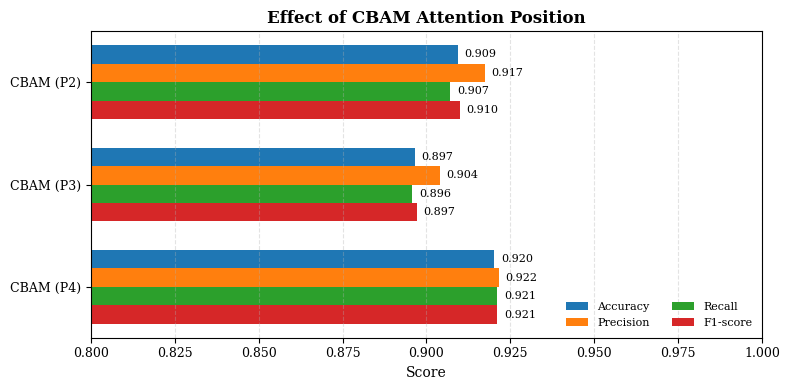

Saved position comparison files to: /kaggle/working/lab8_plots


In [41]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

position_results = [
    cbam_p2_metrics,
    cbam_p3_metrics,
    cbam_p4_metrics
]

position_df = pd.DataFrame(position_results)

metric_columns = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

print("CBAM Attention Position Comparison")
display(
    position_df[
        ["Model"] + metric_columns
    ].style.format({
        column: "{:.4f}" for column in metric_columns
    })
)

# Save results as CSV
position_df.to_csv(
    os.path.join(OUTPUT_DIR, "cbam_position_comparison.csv"),
    index=False
)


plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 10

short_labels = ["CBAM (P2)", "CBAM (P3)", "CBAM (P4)"]
y = np.arange(len(short_labels))
bar_height = 0.18
offsets = np.linspace(-1.5 * bar_height, 1.5 * bar_height, 4)

fig, ax = plt.subplots(figsize=(8, 4))

for metric, offset in zip(metric_columns, offsets):
    values = position_df[metric].to_numpy()

    bars = ax.barh(
        y + offset,
        values,
        height=bar_height,
        label=metric.replace(" (Macro)", "")
    )

    for bar, value in zip(bars, values):
        ax.text(
            value + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=8
        )

ax.set_yticks(y)
ax.set_yticklabels(short_labels)
ax.set_xlim(0.80, 1.00)
ax.set_xlabel("Score")
ax.set_title("Effect of CBAM Attention Position")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.legend(frameon=False, ncol=2, loc="lower right")
ax.invert_yaxis()

fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "cbam_position_comparison.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved position comparison files to:", OUTPUT_DIR)

In [42]:

#  CHECK SPATIAL ATTENTION LAYER NAMES

for model_name, model in [
    ("CBAM P2", cbam_p2_model),
    ("CBAM P3", cbam_p3_model),
    ("CBAM P4", cbam_p4_model)
]:
    print(f"\n{model_name} spatial-attention-related layers:")

    for layer in model.layers:
        if "spatial" in layer.name.lower():
            print(
                f"{layer.name:35s}",
                getattr(layer, "output_shape", "shape unavailable")
            )


CBAM P2 spatial-attention-related layers:
cbam_p2_spatial_avg                 shape unavailable
cbam_p2_spatial_max                 shape unavailable
cbam_p2_spatial_concat              shape unavailable
cbam_p2_spatial_conv                shape unavailable

CBAM P3 spatial-attention-related layers:
cbam_p3_spatial_avg                 shape unavailable
cbam_p3_spatial_max                 shape unavailable
cbam_p3_spatial_concat              shape unavailable
cbam_p3_spatial_conv                shape unavailable

CBAM P4 spatial-attention-related layers:
cbam_p4_spatial_avg                 shape unavailable
cbam_p4_spatial_max                 shape unavailable
cbam_p4_spatial_concat              shape unavailable
cbam_p4_spatial_conv                shape unavailable


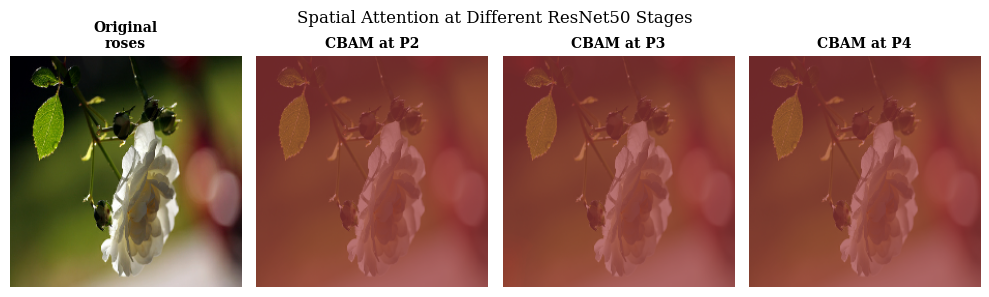

Saved spatial attention visualization: /kaggle/working/lab8_plots


In [43]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Get one test image
for images, labels in test_ds.take(1):
    sample_image = images[0:1]
    sample_label = CLASS_NAMES[int(np.argmax(labels[0].numpy()))]

# Models and their spatial attention layers
attention_models = [
    ("CBAM at P2", cbam_p2_model, "cbam_p2_spatial_conv"),
    ("CBAM at P3", cbam_p3_model, "cbam_p3_spatial_conv"),
    ("CBAM at P4", cbam_p4_model, "cbam_p4_spatial_conv")
]

# Plot original image and attention maps
plt.rcParams["font.family"] = "serif"

fig, axes = plt.subplots(1, 4, figsize=(10, 3))

# Convert preprocessed image back approximately for display
image_display = sample_image[0].numpy()
image_display = image_display + [103.939, 116.779, 123.68]
image_display = image_display[..., ::-1]
image_display = np.clip(image_display / 255.0, 0, 1)

axes[0].imshow(image_display)
axes[0].set_title(f"Original\n{sample_label}", fontsize=10)
axes[0].axis("off")

for ax, (model_name, model, layer_name) in zip(
    axes[1:], attention_models
):
    attention_layer = model.get_layer(layer_name)

    attention_extractor = tf.keras.Model(
        inputs=model.input,
        outputs=attention_layer.output
    )

    attention_map = attention_extractor(sample_image, training=False).numpy()[0, :, :, 0]

    # Resize to original image resolution for side-by-side comparison
    attention_resized = tf.image.resize(
        attention_map[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    im = ax.imshow(
        image_display,
        alpha=0.65
    )
    ax.imshow(
        attention_resized,
        cmap="jet",
        alpha=0.55,
        vmin=0,
        vmax=1
    )

    ax.set_title(model_name, fontsize=10)
    ax.axis("off")

fig.suptitle(
    "Spatial Attention at Different ResNet50 Stages",
    fontsize=12
)
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "spatial_attention_p2_p3_p4.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved spatial attention visualization:", OUTPUT_DIR)

In [44]:
# Inspect the baseline model's nested ResNet50
for layer in baseline_model.layers:
    print(layer.name, type(layer).__name__)

# Find the nested ResNet50 model
resnet_layer = next(
    layer for layer in baseline_model.layers
    if isinstance(layer, tf.keras.Model)
)

print("\nNested ResNet50:", resnet_layer.name)
print("Final convolutional layer:",
      resnet_layer.get_layer("conv5_block3_out").name)

input_layer_1 InputLayer
resnet50 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense

Nested ResNet50: resnet50
Final convolutional layer: conv5_block3_out


In [45]:

# CORRECTED GRAD-CAM FUNCTION


def make_gradcam_heatmap(image, model, last_conv_name="conv5_block3_out"):

    # Handle a nested ResNet50 in the baseline model
    nested_resnet = next(
        (
            layer for layer in model.layers
            if isinstance(layer, tf.keras.Model)
            and last_conv_name in [l.name for l in layer.layers]
        ),
        None
    )

    if nested_resnet is not None:
        # Extract the final convolutional features from nested ResNet50
        feature_extractor = tf.keras.Model(
            nested_resnet.input,
            nested_resnet.get_layer(last_conv_name).output
        )

        with tf.GradientTape() as tape:
            conv_outputs = feature_extractor(image, training=False)
            tape.watch(conv_outputs)

            # Continue through the baseline classification head
            x = conv_outputs
            for layer in model.layers[model.layers.index(nested_resnet) + 1:]:
                x = layer(x, training=False)

            predictions = x
            class_index = tf.argmax(predictions[0])
            class_score = predictions[:, class_index]

    else:
        # Direct-layer models: build a model exposing features and predictions
        last_conv = model.get_layer(last_conv_name)
        grad_model = tf.keras.Model(
            inputs=model.inputs,
            outputs=[last_conv.output, model.output]
        )

        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(image, training=False)
            class_index = tf.argmax(predictions[0])
            class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )

    heatmap = tf.reduce_sum(
        weights * conv_outputs, axis=-1
    )
    heatmap = tf.nn.relu(heatmap)[0]
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy(), int(class_index.numpy())

In [46]:

# ============================================================
# CELL 43D — CHECK CBAM SPATIAL ATTENTION CONNECTIVITY
# ============================================================

cbam_attention_layer = cbam_p3_model.get_layer(
    "cbam_p3_spatial_conv"
)

cbam_attention_grad_model = tf.keras.Model(
    inputs=cbam_p3_model.inputs,
    outputs=[
        cbam_attention_layer.output,
        cbam_p3_model.output
    ]
)

with tf.GradientTape() as tape:
    attention_maps, predictions = cbam_attention_grad_model(
        sample_image,
        training=False
    )
    predicted_class = tf.argmax(predictions[0])
    class_score = predictions[:, predicted_class]

attention_gradients = tape.gradient(
    class_score,
    attention_maps
)

print("Attention map shape:", attention_maps.shape)
print("Prediction shape:", predictions.shape)
print("Predicted class:", CLASS_NAMES[int(predicted_class.numpy())])
print("Gradients connected:", attention_gradients is not None)


Attention map shape: (1, 14, 14, 1)
Prediction shape: (1, 5)
Predicted class: roses
Gradients connected: True


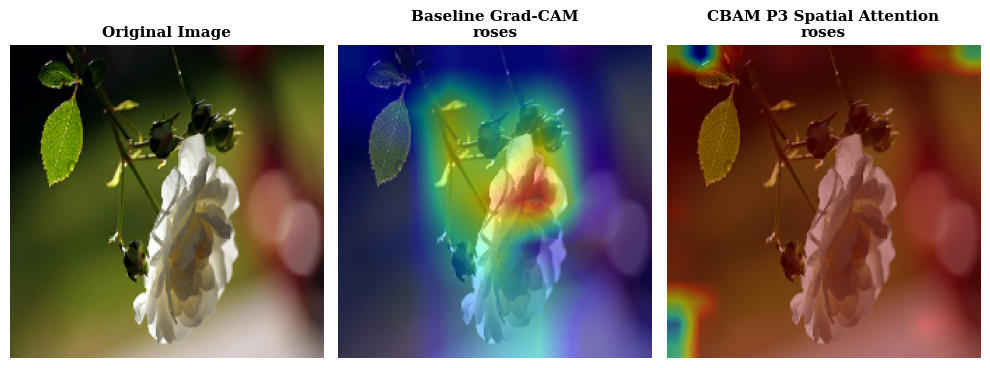

Saved Grad-CAM comparison in: /kaggle/working/lab8_plots


In [47]:

# ============================================================
# CELL 43E — BASELINE GRAD-CAM VS CBAM SPATIAL ATTENTION
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
LAST_CONV_LAYER = "conv5_block3_out"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Reuse the working baseline Grad-CAM
baseline_heatmap, baseline_class = make_gradcam_heatmap(
    sample_image,
    baseline_model,
    LAST_CONV_LAYER
)

# Extract the graph-connected CBAM spatial-attention map
with tf.GradientTape() as tape:
    attention_maps, cbam_predictions = cbam_attention_grad_model(
        sample_image,
        training=False
    )

cbam_class = int(tf.argmax(cbam_predictions[0]).numpy())
attention_map = attention_maps[0, :, :, 0].numpy()

# Prepare input image for display
img = sample_image[0].numpy()
img = img + np.array([103.939, 116.779, 123.68])
img = img[..., ::-1]
img = np.clip(img, 0, 255).astype(np.uint8)

# Resize heatmaps to image size
baseline_resized = tf.image.resize(
    baseline_heatmap[..., np.newaxis], (224, 224)
).numpy().squeeze()

attention_resized = tf.image.resize(
    attention_map[..., np.newaxis], (224, 224)
).numpy().squeeze()

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))

axes[0].imshow(img)
axes[0].set_title("Original Image", fontsize=11)

axes[1].imshow(img)
axes[1].imshow(baseline_resized, cmap="jet", alpha=0.45)
axes[1].set_title(
    f"Baseline Grad-CAM\n{CLASS_NAMES[baseline_class]}",
    fontsize=11
)

axes[2].imshow(img)
axes[2].imshow(attention_resized, cmap="jet", alpha=0.45)
axes[2].set_title(
    f"CBAM P3 Spatial Attention\n{CLASS_NAMES[cbam_class]}",
    fontsize=11
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "gradcam_baseline_vs_cbam_p3.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved Grad-CAM comparison in:", OUTPUT_DIR)


CBAM attention-position results:


,Position,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,P2 (28 x 28),ResNet50 + CBAM (P2),0.9093,0.9173,0.9071,0.9099
1,P3 (14 x 14),ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970
2,P4 (7 x 7),ResNet50 + CBAM (P4),0.9201,0.9215,0.9211,0.9210


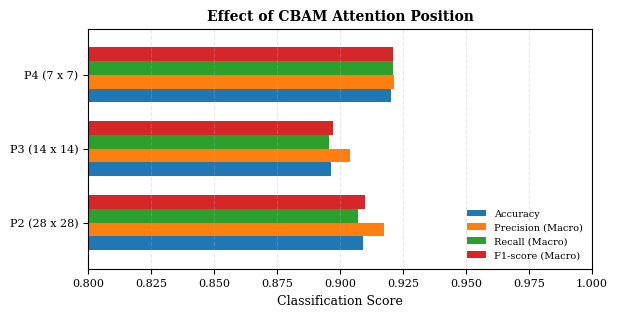

Saved CBAM position comparison in EPS and SVG formats.


In [48]:

# ============================================================
# CELL 48 — EFFECT OF CBAM ATTENTION POSITION
# A4-FRIENDLY FIGURE: P2 vs P3 vs P4
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

position_df = pd.DataFrame([
    {"Position": "P2 (28 x 28)", **cbam_p2_metrics},
    {"Position": "P3 (14 x 14)", **cbam_p3_metrics},
    {"Position": "P4 (7 x 7)", **cbam_p4_metrics}
])

metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

print("CBAM attention-position results:")
display(position_df.round(4))

position_df.to_csv(
    os.path.join(OUTPUT_DIR, "cbam_position_comparison.csv"),
    index=False
)

fig, ax = plt.subplots(figsize=(6.2, 3.2))

position_df.set_index("Position")[metrics].plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.set_title("Effect of CBAM Attention Position", fontsize=10)
ax.set_xlabel("Classification Score", fontsize=9)
ax.set_ylabel("")
ax.set_xlim(0.80, 1.0)
ax.tick_params(axis="both", labelsize=8)
ax.legend(fontsize=7, loc="lower right", frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "cbam_position_comparison.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved CBAM position comparison in EPS and SVG formats.")


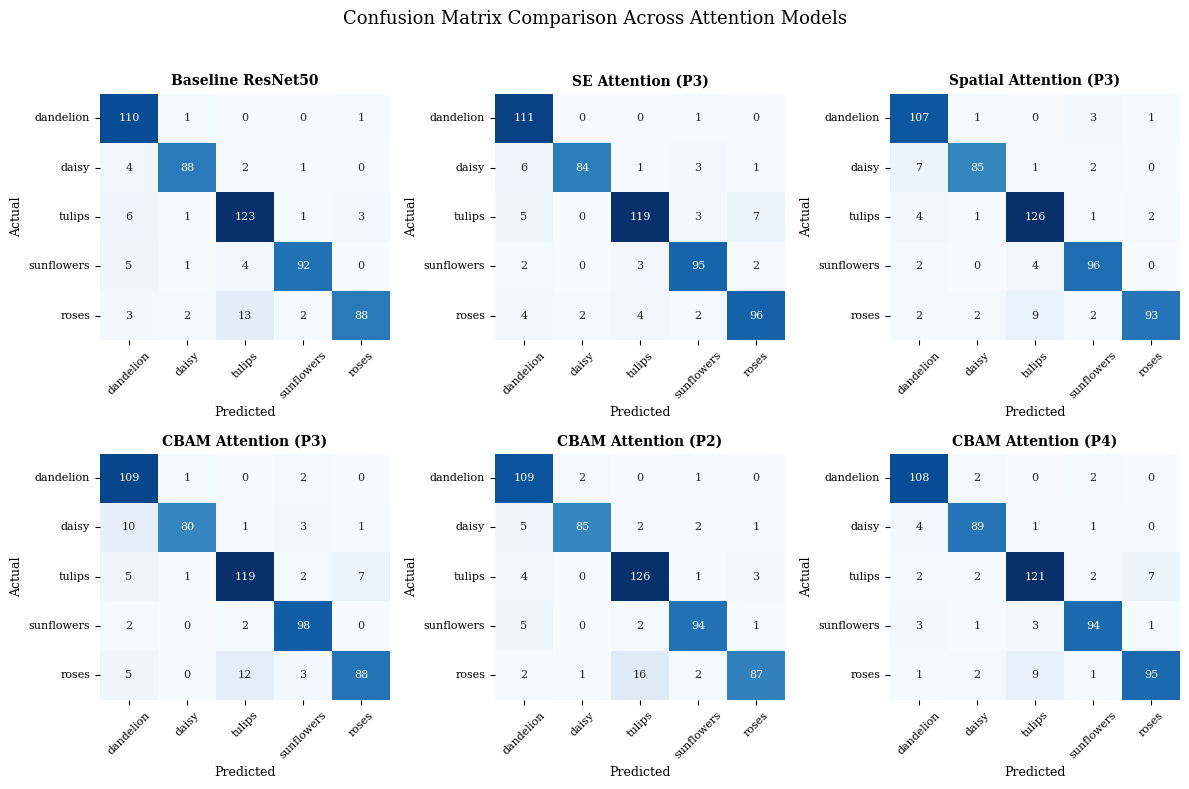

Saved confusion matrices to: /kaggle/working/lab8_plots


In [49]:

# ============================================================
# CELL 45 — CONFUSION MATRICES FOR ALL MODELS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from sklearn.metrics import confusion_matrix

models_predictions = [
    ("Baseline ResNet50", y_true, y_pred),
    ("SE Attention (P3)", y_true_se, y_pred_se),
    ("Spatial Attention (P3)", y_true_spatial, y_pred_spatial),
    ("CBAM Attention (P3)", y_true_cbam, y_pred_cbam),
    ("CBAM Attention (P2)", y_true_cbam_p2, y_pred_cbam_p2),
    ("CBAM Attention (P4)", y_true_cbam_p4, y_pred_cbam_p4)
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (model_name, true_labels, predicted_labels) in zip(
    axes.flat, models_predictions
):
    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        annot_kws={"size": 8},
        ax=ax
    )

    ax.set_title(model_name, fontsize=10)
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_ylabel("Actual", fontsize=9)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)

fig.suptitle("Confusion Matrix Comparison Across Attention Models", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    os.path.join(OUTPUT_DIR, "all_models_confusion_matrices.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved confusion matrices to:", OUTPUT_DIR)


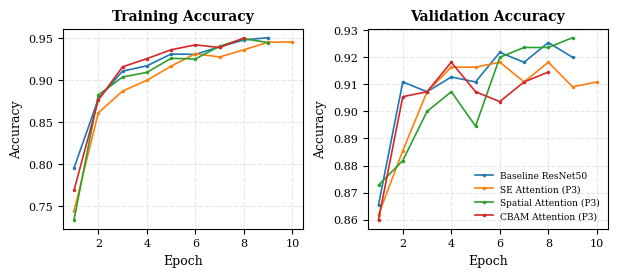

Saved training-accuracy comparison.


In [50]:

# ============================================================
# CELL 46 — TRAINING AND VALIDATION ACCURACY
# A4-FRIENDLY FIGURE
# ============================================================

import matplotlib.pyplot as plt
import os

histories = [
    ("Baseline ResNet50", baseline_history),
    ("SE Attention (P3)", se_p3_history),
    ("Spatial Attention (P3)", spatial_p3_history),
    ("CBAM Attention (P3)", cbam_p3_history)
]

fig, axes = plt.subplots(1, 2, figsize=(6.2, 2.8))

for name, history in histories:
    h = history.history
    epochs = range(1, len(h["accuracy"]) + 1)

    axes[0].plot(
        epochs, h["accuracy"], marker=".", linewidth=1.2,
        markersize=3, label=name
    )
    axes[1].plot(
        epochs, h["val_accuracy"], marker=".", linewidth=1.2,
        markersize=3, label=name
    )

axes[0].set_title("Training Accuracy", fontsize=10)
axes[1].set_title("Validation Accuracy", fontsize=10)

for ax in axes:
    ax.set_xlabel("Epoch", fontsize=9)
    ax.set_ylabel("Accuracy", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(True, linestyle="--", alpha=0.3)

axes[1].legend(
    fontsize=6.5, loc="lower right", frameon=False
)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "training_accuracy_comparison.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved training-accuracy comparison.")


Attention-type results:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Baseline ResNet50,0.9093,0.9173,0.9086,0.9107
1,ResNet50 + SE (P3),0.9165,0.9200,0.9167,0.9169
2,ResNet50 + Spatial (P3),0.9201,0.9248,0.9185,0.9204
3,ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970


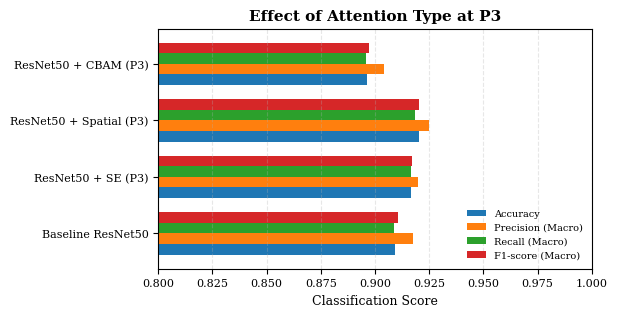

Saved attention-type comparison.


In [51]:

# ============================================================
# CELL 47 — EFFECT OF ATTENTION TYPE AT P3
# A4-FRIENDLY FIGURE
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

attention_df = pd.DataFrame([
    {"Model": "Baseline", **baseline_metrics},
    {"Model": "SE (P3)", **se_p3_metrics},
    {"Model": "Spatial (P3)", **spatial_p3_metrics},
    {"Model": "CBAM (P3)", **cbam_p3_metrics}
])

metrics_to_plot = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

print("Attention-type results:")
display(attention_df.round(4))

attention_df.to_csv(
    os.path.join(OUTPUT_DIR, "attention_type_comparison.csv"),
    index=False
)

fig, ax = plt.subplots(figsize=(6.2, 3.2))

plot_df = attention_df.set_index("Model")[metrics_to_plot]
plot_df.plot(kind="barh", ax=ax, width=0.75)

ax.set_title("Effect of Attention Type at P3", fontsize=11)
ax.set_xlabel("Classification Score", fontsize=9)
ax.set_ylabel("")
ax.set_xlim(0.80, 1.0)
ax.tick_params(axis="both", labelsize=8)
ax.legend(fontsize=7, loc="lower right", frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "attention_type_comparison.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved attention-type comparison.")


In [52]:

# ============================================================
# CELL 49 — SELF-ATTENTION BLOCK
# Applied at P3 (14 x 14 feature map)
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model

def self_attention_block(inputs, name="self_attention"):
    """
    Non-local self-attention:
    each spatial position can attend to all other positions.
    Input shape: (batch, height, width, channels)
    """

    channels = inputs.shape[-1]
    reduced_channels = max(channels // 8, 1)

    # Query, Key and Value projections
    query = layers.Conv2D(
        reduced_channels, 1, padding="same",
        name=f"{name}_query"
    )(inputs)

    key = layers.Conv2D(
        reduced_channels, 1, padding="same",
        name=f"{name}_key"
    )(inputs)

    value = layers.Conv2D(
        reduced_channels, 1, padding="same",
        name=f"{name}_value"
    )(inputs)

    # Flatten spatial dimensions
    query = layers.Reshape(
        (-1, reduced_channels), name=f"{name}_query_flat"
    )(query)

    key = layers.Reshape(
        (-1, reduced_channels), name=f"{name}_key_flat"
    )(key)

    value = layers.Reshape(
        (-1, reduced_channels), name=f"{name}_value_flat"
    )(value)

    # Attention weights: softmax(QK^T / sqrt(d))
    attention_scores = layers.Lambda(
        lambda tensors: tf.matmul(
            tensors[0], tensors[1], transpose_b=True
        ) / tf.math.sqrt(
            tf.cast(reduced_channels, tf.float32)
        ),
        name=f"{name}_scores"
    )([query, key])

    attention_weights = layers.Softmax(
        axis=-1, name=f"{name}_weights"
    )(attention_scores)

    # Weighted combination of values
    attended = layers.Lambda(
        lambda tensors: tf.matmul(tensors[0], tensors[1]),
        name=f"{name}_context"
    )([attention_weights, value])

    height, width = inputs.shape[1], inputs.shape[2]

    attended = layers.Reshape(
        (height, width, reduced_channels),
        name=f"{name}_reshape"
    )(attended)

    attended = layers.Conv2D(
        channels, 1, padding="same",
        name=f"{name}_output_projection"
    )(attended)

    # Learnable residual scaling, initialized to zero
    gamma = tf.Variable(
        0.0, trainable=True, dtype=tf.float32,
        name=f"{name}_gamma"
    )

    scaled = layers.Lambda(
        lambda tensors: tensors[0] * tensors[1],
        name=f"{name}_scale"
    )([attended, gamma])

    output = layers.Add(name=f"{name}_residual")(
        [inputs, scaled]
    )

    return output


In [53]:

# ============================================================
# CELL 50 — RESNET50 + SELF-ATTENTION AT P3
# ============================================================

# ============================================================
# CELL 50A — OPTIMIZER HELPER
# ============================================================

import tensorflow as tf

def make_optimizer(optimizer_name, learning_rate):
    name = str(optimizer_name).lower()

    if "adam" in name:
        return tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    elif "sgd" in name:
        return tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    elif "rmsprop" in name:
        return tf.keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    else:
        raise ValueError(
            f"Unsupported optimizer: {optimizer_name}"
        )

print("Optimizer helper defined successfully.")
print("Selected optimizer:", BEST_OPTIMIZER)
print("Selected learning rate:", BEST_LR)


import tensorflow as tf
from tensorflow.keras import layers, Model

def build_self_attention_p3_model():
    base = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="self_attention_input"
    )

    # Pretrained backbone up to P3
    p3_backbone = Model(
        inputs=base.input,
        outputs=base.get_layer("conv4_block6_out").output,
        name="resnet50_until_p3"
    )

    x = p3_backbone(inputs)

    # Self-attention at P3
    x = self_attention_block(x, name="self_attention_p3")

    # Reuse pretrained conv5_x residual stage
    shortcut = x

    x = base.get_layer("conv5_block1_1_conv")(x)
    x = base.get_layer("conv5_block1_1_bn")(x)
    x = base.get_layer("conv5_block1_1_relu")(x)

    x = base.get_layer("conv5_block1_2_conv")(x)
    x = base.get_layer("conv5_block1_2_bn")(x)
    x = base.get_layer("conv5_block1_2_relu")(x)

    x = base.get_layer("conv5_block1_3_conv")(x)
    x = base.get_layer("conv5_block1_3_bn")(x)

    shortcut = base.get_layer("conv5_block1_0_conv")(shortcut)
    shortcut = base.get_layer("conv5_block1_0_bn")(shortcut)

    x = layers.Add(name="self_attention_conv5_block1_add")(
        [x, shortcut]
    )
    x = base.get_layer("conv5_block1_out")(x)

    # Remaining pretrained identity blocks
    for block_num in [2, 3]:
        prefix = f"conv5_block{block_num}"

        shortcut = x

        x = base.get_layer(f"{prefix}_1_conv")(x)
        x = base.get_layer(f"{prefix}_1_bn")(x)
        x = base.get_layer(f"{prefix}_1_relu")(x)

        x = base.get_layer(f"{prefix}_2_conv")(x)
        x = base.get_layer(f"{prefix}_2_bn")(x)
        x = base.get_layer(f"{prefix}_2_relu")(x)

        x = base.get_layer(f"{prefix}_3_conv")(x)
        x = base.get_layer(f"{prefix}_3_bn")(x)

        x = layers.Add(name=f"self_attention_{prefix}_add")(
            [x, shortcut]
        )
        x = base.get_layer(f"{prefix}_out")(x)

    # Classification head, matching the other experiments
    x = layers.GlobalAveragePooling2D(
        name="self_attention_gap"
    )(x)

    x = layers.Dropout(
        BEST_DROPOUT,
        name="self_attention_dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="self_attention_predictions"
    )(x)

    model = Model(
        inputs,
        outputs,
        name="ResNet50_SelfAttention_P3"
    )

    model.compile(
        optimizer=make_optimizer(BEST_OPTIMIZER, BEST_LR),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


self_attention_p3_model = build_self_attention_p3_model()

self_attention_p3_model.summary()


Optimizer helper defined successfully.
Selected optimizer: sgd
Selected learning rate: 0.001


Model: "ResNet50_SelfAttention_P3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ self_attention_inp… │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_until_p3   │ (None, 14, 14,    │  8,589,184 │ self_attention_i… │
│ (Functional)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │    131,200 │ resnet50_until_p… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │    131,200 │ resnet50_until_p… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 196, 128)  │          0 │ self_attention_p… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 196, 128)  │          0 │ self_attention_p… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 196, 196)  │          0 │ self_attention_p… │
│ (Lambda)            │                   │            │ self_attention_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │    131,200 │ resnet50_until_p… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 196, 196)  │          0 │ self_attention_p… │
│ (Softmax)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 196, 128)  │          0 │ self_attention_p… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 196, 128)  │          0 │ self_attention_p… │
│ (Lambda)            │                   │            │ self_attention_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │          0 │ self_attention_p… │
│ (Reshape)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │    132,096 │ self_attention_p… │
│ (Conv2D)            │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │          0 │ self_attention_p… │
│ (Lambda)            │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_p3_… │ (None, 14, 14,    │          0 │ resnet50_until_p… │
│ (Add)               │ 1024)             │            │ self_attention_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv5_block1_1_conv │ (None, 7, 7, 512) │    524,800 │ self_attention_p… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv5_block1_1_bn   │ (None, 7, 7, 512) │      2,048 │ conv5_block1_1_c

 Total params: 24,123,653 (92.02 MB)

 Trainable params: 535,941 (2.04 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [54]:

# ============================================================
# CELL 51 — TRAIN SELF-ATTENTION P3 MODEL
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping

self_attention_p3_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=2
    )
]

self_attention_p3_history = self_attention_p3_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=self_attention_p3_callbacks,
    verbose=2
)


Epoch 1/10
322/322 - 33s - 103ms/step - accuracy: 0.7875 - loss: 0.6115 - val_accuracy: 0.8745 - val_loss: 0.3639
Epoch 2/10
322/322 - 12s - 39ms/step - accuracy: 0.8813 - loss: 0.3447 - val_accuracy: 0.8964 - val_loss: 0.3125
Epoch 3/10
322/322 - 12s - 39ms/step - accuracy: 0.9031 - loss: 0.2595 - val_accuracy: 0.9036 - val_loss: 0.3093
Epoch 4/10
322/322 - 12s - 38ms/step - accuracy: 0.9186 - loss: 0.2328 - val_accuracy: 0.9200 - val_loss: 0.2750
Epoch 5/10
322/322 - 12s - 38ms/step - accuracy: 0.9334 - loss: 0.1901 - val_accuracy: 0.9364 - val_loss: 0.2469
Epoch 6/10
322/322 - 12s - 37ms/step - accuracy: 0.9288 - loss: 0.1946 - val_accuracy: 0.9273 - val_loss: 0.2692
Epoch 7/10
322/322 - 12s - 37ms/step - accuracy: 0.9350 - loss: 0.1742 - val_accuracy: 0.9345 - val_loss: 0.2559
Epoch 8/10
322/322 - 12s - 38ms/step - accuracy: 0.9439 - loss: 0.1556 - val_accuracy: 0.9291 - val_loss: 0.2594
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 5.


In [55]:

# ============================================================
# CELL 52 — EVALUATE SELF-ATTENTION P3
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true_self_attention = []
y_pred_self_attention = []

for images, labels in test_ds:
    probabilities = self_attention_p3_model(images, training=False).numpy()

    y_pred_self_attention.extend(
        np.argmax(probabilities, axis=1)
    )
    y_true_self_attention.extend(
        np.argmax(labels.numpy(), axis=1)
    )

y_true_self_attention = np.array(y_true_self_attention)
y_pred_self_attention = np.array(y_pred_self_attention)

self_attention_p3_metrics = {
    "Accuracy": accuracy_score(
        y_true_self_attention, y_pred_self_attention
    ),
    "Precision (Macro)": precision_score(
        y_true_self_attention,
        y_pred_self_attention,
        average="macro",
        zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_true_self_attention,
        y_pred_self_attention,
        average="macro",
        zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_true_self_attention,
        y_pred_self_attention,
        average="macro",
        zero_division=0
    )
}

print("Self-Attention P3 — Test Results")
for metric, value in self_attention_p3_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true_self_attention,
        y_pred_self_attention,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4
    )
)


Self-Attention P3 — Test Results
Accuracy: 0.9201
Precision (Macro): 0.9230
Recall (Macro): 0.9195
F1-score (Macro): 0.9203

Classification Report:
              precision    recall  f1-score   support

   dandelion     0.8710    0.9643    0.9153       112
       daisy     0.9551    0.8947    0.9239        95
      tulips     0.9248    0.9179    0.9213       134
  sunflowers     0.9143    0.9412    0.9275       102
       roses     0.9500    0.8796    0.9135       108

    accuracy                         0.9201       551
   macro avg     0.9230    0.9195    0.9203       551
weighted avg     0.9221    0.9201    0.9202       551



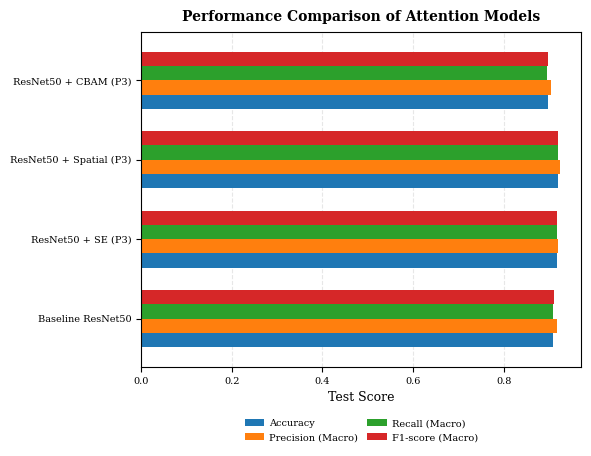

Updated comparison figure saved in EPS and SVG formats.


In [56]:

# ============================================================
# CELL 53 — PERFORMANCE COMPARISON (LEGEND FIXED)
# A4-FRIENDLY: MAXIMUM WIDTH 6.2 INCHES
# ============================================================

import os
import matplotlib.pyplot as plt

metric_columns = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

plot_df = comparison_df.set_index("Model")[metric_columns]

fig, ax = plt.subplots(figsize=(6.2, 5.0))

plot_df.plot(
    kind="barh",
    ax=ax,
    width=0.72
)

ax.set_title(
    "Performance Comparison of Attention Models",
    fontsize=10,
    pad=8
)
ax.set_xlabel("Test Score", fontsize=9)
ax.set_ylabel("")
ax.tick_params(axis="both", labelsize=7)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Put legend below the chart, outside the axes
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    fontsize=7,
    frameon=False,
    columnspacing=1.0,
    handletextpad=0.5
)

fig.subplots_adjust(
    left=0.27,
    right=0.98,
    top=0.92,
    bottom=0.25
)

fig.savefig(
    os.path.join(
        OUTPUT_DIR, "all_model_performance_comparison.eps"
    ),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(
        OUTPUT_DIR, "all_model_performance_comparison.svg"
    ),
    format="svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Updated comparison figure saved in EPS and SVG formats.")


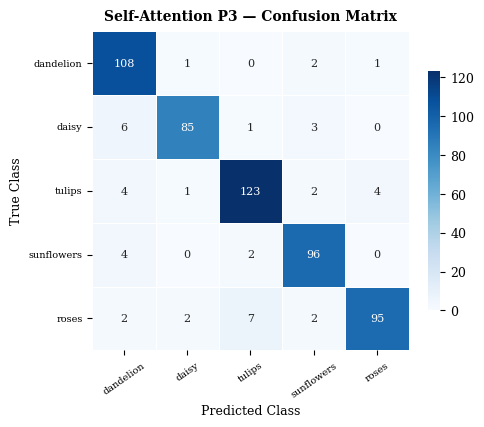

Saved self-attention confusion matrix in EPS and SVG formats.


In [57]:

# ============================================================
# CELL 54 — SELF-ATTENTION P3 CONFUSION MATRIX
# A4-FRIENDLY FIGURE
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_self_attention = confusion_matrix(
    y_true_self_attention,
    y_pred_self_attention,
    labels=list(range(NUM_CLASSES))
)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]

fig, ax = plt.subplots(figsize=(5.0, 4.3))

sns.heatmap(
    cm_self_attention,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    annot_kws={"size": 8},
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"shrink": 0.75},
    ax=ax
)

ax.set_title(
    "Self-Attention P3 — Confusion Matrix",
    fontsize=10,
    pad=8
)
ax.set_xlabel("Predicted Class", fontsize=9)
ax.set_ylabel("True Class", fontsize=9)
ax.tick_params(axis="x", labelsize=7, rotation=35)
ax.tick_params(axis="y", labelsize=7, rotation=0)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(
        OUTPUT_DIR, "self_attention_p3_confusion_matrix.eps"
    ),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(
        OUTPUT_DIR, "self_attention_p3_confusion_matrix.svg"
    ),
    format="svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved self-attention confusion matrix in EPS and SVG formats.")


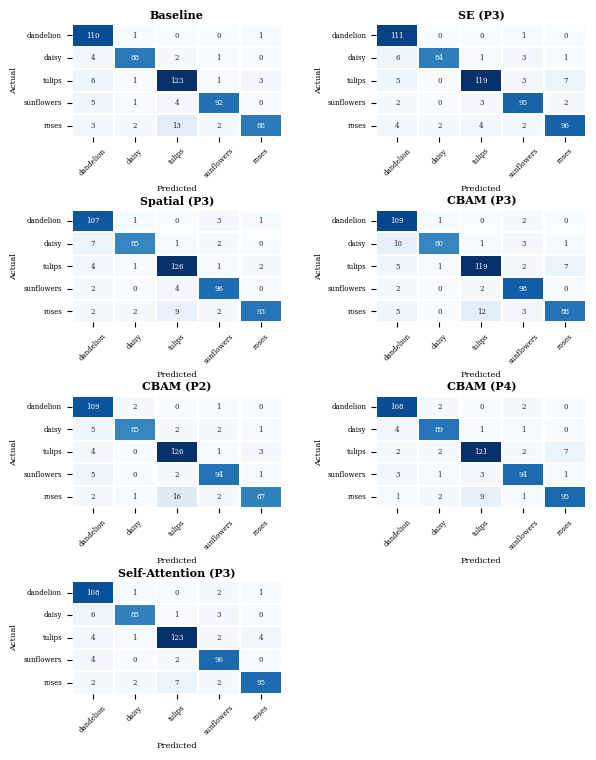

Saved seven-model confusion matrices in EPS and SVG formats.


In [58]:

# ============================================================
# CELL 55 — ALL-MODEL CONFUSION MATRICES
# A4-READY: EPS 600 DPI + SVG
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models_for_cm = [
    ("Baseline", y_true, y_pred),
    ("SE (P3)", y_true_se, y_pred_se),
    ("Spatial (P3)", y_true_spatial, y_pred_spatial),
    ("CBAM (P3)", y_true_cbam, y_pred_cbam),
    ("CBAM (P2)", y_true_cbam_p2, y_pred_cbam_p2),
    ("CBAM (P4)", y_true_cbam_p4, y_pred_cbam_p4),
    (
        "Self-Attention (P3)",
        y_true_self_attention,
        y_pred_self_attention
    )
]

fig, axes = plt.subplots(
    4, 2,
    figsize=(6.2, 7.2)
)

axes = axes.flatten()

for i, (name, true_labels, pred_labels) in enumerate(models_for_cm):
    cm = confusion_matrix(
        true_labels,
        pred_labels,
        labels=list(range(NUM_CLASSES))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        annot_kws={"size": 5},
        linewidths=0.2,
        linecolor="white",
        ax=axes[i]
    )

    axes[i].set_title(name, fontsize=8, pad=4)
    axes[i].set_xlabel("Predicted", fontsize=6)
    axes[i].set_ylabel("Actual", fontsize=6)
    axes[i].tick_params(axis="x", labelsize=5, rotation=45)
    axes[i].tick_params(axis="y", labelsize=5, rotation=0)

# Hide the unused eighth panel
axes[-1].axis("off")

fig.subplots_adjust(
    left=0.15,
    right=0.98,
    top=0.97,
    bottom=0.04,
    hspace=0.65,
    wspace=0.45
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "all_models_confusion_matrices.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved seven-model confusion matrices in EPS and SVG formats.")


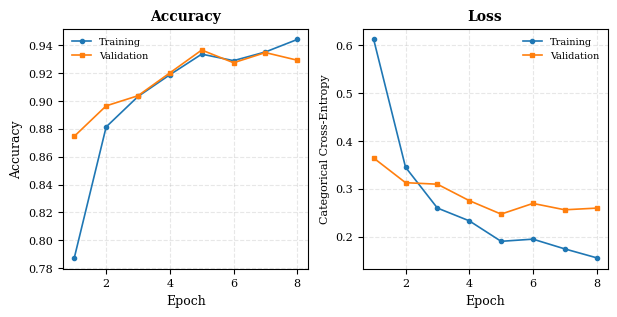

Saved self-attention training curves in EPS and SVG formats.


In [59]:

# ============================================================
# CELL 56 — SELF-ATTENTION P3 TRAINING CURVES
# A4-FRIENDLY: 6.2 x 3.2 INCHES
# ============================================================

import os
import matplotlib.pyplot as plt

history = self_attention_p3_history.history
epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(6.2, 3.2))

axes[0].plot(
    epochs, history["accuracy"],
    marker="o", markersize=3, linewidth=1.2,
    label="Training"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", markersize=3, linewidth=1.2,
    label="Validation"
)
axes[0].set_title("Accuracy", fontsize=10)
axes[0].set_xlabel("Epoch", fontsize=9)
axes[0].set_ylabel("Accuracy", fontsize=9)

axes[1].plot(
    epochs, history["loss"],
    marker="o", markersize=3, linewidth=1.2,
    label="Training"
)
axes[1].plot(
    epochs, history["val_loss"],
    marker="s", markersize=3, linewidth=1.2,
    label="Validation"
)
axes[1].set_title("Loss", fontsize=10)
axes[1].set_xlabel("Epoch", fontsize=9)
axes[1].set_ylabel("Categorical Cross-Entropy", fontsize=8)

for ax in axes:
    ax.tick_params(labelsize=8)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(fontsize=7, frameon=False)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "self_attention_p3_training_curves.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved self-attention training curves in EPS and SVG formats.")


Model Complexity and Inference Results


,Model,Total Parameters,Trainable Parameters,Inference Time (ms/image)
0,Baseline,23597957,10245,27.134
1,SE (P3),23730117,142405,27.378
2,Spatial (P3),23598055,10343,27.286
3,CBAM (P3),23730215,142503,28.552
4,CBAM (P2),23631367,43655,28.921
5,CBAM (P4),24124519,536807,28.719
6,Self-Attention (P3),24123653,535941,28.409


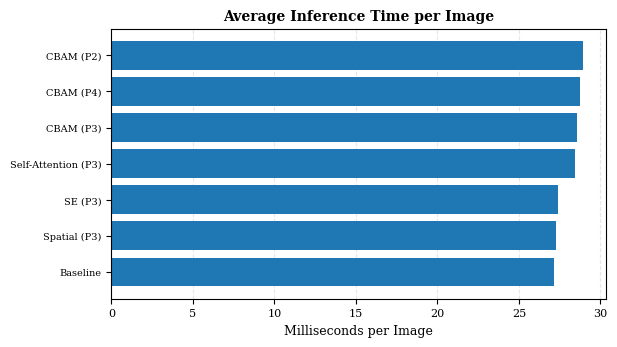

Saved complexity CSV and inference-time figures.


In [60]:

# ============================================================
# CELL 57 — MODEL COMPLEXITY AND INFERENCE TIME
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

models_to_profile = [
    ("Baseline", baseline_model),
    ("SE (P3)", se_p3_model),
    ("Spatial (P3)", spatial_p3_model),
    ("CBAM (P3)", cbam_p3_model),
    ("CBAM (P2)", cbam_p2_model),
    ("CBAM (P4)", cbam_p4_model),
    ("Self-Attention (P3)", self_attention_p3_model)
]

# Get one batch for warm-up and timing
for images, _ in test_ds.take(1):
    sample_batch = images[:min(8, len(images))]
    break

# Warm up each model before timing
results = []

for name, model in models_to_profile:
    _ = model(sample_batch, training=False)

    # Synchronize execution by materializing outputs
    _ = _.numpy()

    repetitions = 20
    start = time.perf_counter()

    for _ in range(repetitions):
        predictions = model(sample_batch, training=False)
        _ = predictions.numpy()

    elapsed = time.perf_counter() - start

    batch_size = int(sample_batch.shape[0])

    results.append({
        "Model": name,
        "Total Parameters": model.count_params(),
        "Trainable Parameters": sum(
            int(np.prod(v.shape))
            for v in model.trainable_weights
        ),
        "Inference Time (ms/image)": (
            elapsed / repetitions / batch_size * 1000
        )
    })

complexity_df = pd.DataFrame(results)

print("Model Complexity and Inference Results")
display(complexity_df.round(3))

complexity_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_complexity_inference.csv"),
    index=False
)

# Compact A4-ready inference-time figure
fig, ax = plt.subplots(figsize=(6.2, 3.5))

plot_data = complexity_df.sort_values(
    "Inference Time (ms/image)"
)

ax.barh(
    plot_data["Model"],
    plot_data["Inference Time (ms/image)"]
)

ax.set_title("Average Inference Time per Image", fontsize=10)
ax.set_xlabel("Milliseconds per Image", fontsize=9)
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=7)
ax.tick_params(axis="x", labelsize=8)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "inference_time_comparison.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved complexity CSV and inference-time figures.")


Parameter comparison:


,Model,Total Parameters,Trainable Parameters
0,Baseline,23597957,10245
1,SE (P3),23730117,142405
2,Spatial (P3),23598055,10343
3,CBAM (P3),23730215,142503
4,CBAM (P2),23631367,43655
5,CBAM (P4),24124519,536807
6,Self-Attention (P3),24123653,535941


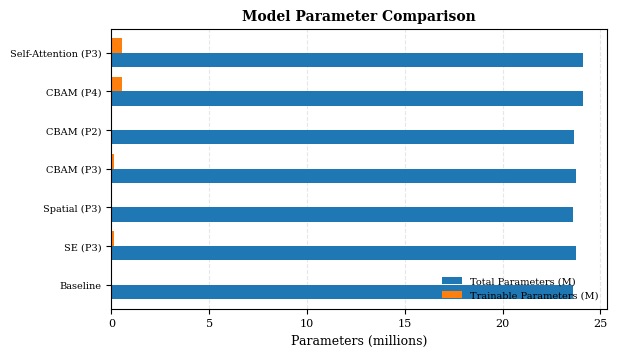

Saved parameter comparison in EPS and SVG formats.


In [61]:

# ============================================================
# CELL 58 — MODEL PARAMETER COMPARISON
# A4-FRIENDLY FIGURE
# ============================================================

import os
import matplotlib.pyplot as plt
import pandas as pd

parameter_df = complexity_df.copy()

# Convert parameter counts to millions for readability
parameter_df["Total Parameters (M)"] = (
    parameter_df["Total Parameters"] / 1_000_000
)
parameter_df["Trainable Parameters (M)"] = (
    parameter_df["Trainable Parameters"] / 1_000_000
)

print("Parameter comparison:")
display(
    parameter_df[
        ["Model", "Total Parameters", "Trainable Parameters"]
    ].round(0)
)

fig, ax = plt.subplots(figsize=(6.2, 3.6))

parameter_plot = parameter_df.set_index("Model")[
    ["Total Parameters (M)", "Trainable Parameters (M)"]
]

parameter_plot.plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.set_title("Model Parameter Comparison", fontsize=10)
ax.set_xlabel("Parameters (millions)", fontsize=9)
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=7)
ax.tick_params(axis="x", labelsize=8)
ax.legend(
    fontsize=7,
    loc="lower right",
    frameon=False
)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "parameter_comparison.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved parameter comparison in EPS and SVG formats.")


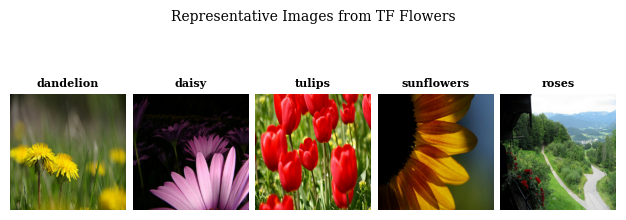

Saved dataset sample figure in EPS and SVG formats.


In [62]:

# ============================================================
# CELL 59 — DATASET SAMPLE VISUALIZATION
# A4-FRIENDLY: 7 x 5 INCHES
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

# Collect one sample image per class
samples = {}

for images, labels in train_ds:
    image_array = images.numpy()
    label_array = labels.numpy()

    for image, label in zip(image_array, label_array):
        class_index = int(np.argmax(label))

        if class_index not in samples:
            samples[class_index] = image

        if len(samples) == NUM_CLASSES:
            break

    if len(samples) == NUM_CLASSES:
        break

fig, axes = plt.subplots(
    1, NUM_CLASSES,
    figsize=(6.2, 2.5)
)

for class_index, ax in enumerate(axes):
    image = samples[class_index]

    # Convert ResNet50-preprocessed BGR image back to displayable RGB
    image = image + np.array([103.939, 116.779, 123.68])
    image = image[..., ::-1]
    image = np.clip(image, 0, 255).astype(np.uint8)

    ax.imshow(image)
    ax.set_title(CLASS_NAMES[class_index], fontsize=8)
    ax.axis("off")

fig.suptitle("Representative Images from TF Flowers", fontsize=10)
fig.tight_layout(pad=0.5, rect=[0, 0, 1, 0.90])

fig.savefig(
    os.path.join(OUTPUT_DIR, "dataset_samples.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved dataset sample figure in EPS and SVG formats.")


In [63]:

# ============================================================
# CELL 60 — FINAL CONSOLIDATED RESULTS TABLE
# ============================================================

import os
import pandas as pd

# Merge classification metrics with complexity measurements
final_results_df = comparison_df.merge(
    complexity_df,
    on="Model",
    how="left",
    suffixes=("", "_complexity")
)

# Keep the columns useful for the report
report_columns = [
    "Model",
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)",
    "Total Parameters",
    "Trainable Parameters",
    "Inference Time (ms/image)"
]

final_results_df = final_results_df[report_columns]

# Display readable values
display(
    final_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-score (Macro)": "{:.4f}",
        "Total Parameters": "{:,.0f}",
        "Trainable Parameters": "{:,.0f}",
        "Inference Time (ms/image)": "{:.3f}"
    })
)

final_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_consolidated_results.csv"),
    index=False
)

# LaTeX table export for your report
with open(
    os.path.join(OUTPUT_DIR, "final_consolidated_results.tex"),
    "w"
) as file:
    file.write(
        final_results_df.to_latex(
            index=False,
            float_format=lambda x: f"{x:.4f}",
            escape=True
        )
    )

print("Saved final_consolidated_results.csv and .tex")


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Total Parameters,Trainable Parameters,Inference Time (ms/image)
0,Baseline ResNet50,0.9093,0.9173,0.9086,0.9107,nan,nan,nan
1,ResNet50 + SE (P3),0.9165,0.9200,0.9167,0.9169,nan,nan,nan
2,ResNet50 + Spatial (P3),0.9201,0.9248,0.9185,0.9204,nan,nan,nan
3,ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970,nan,nan,nan


Saved final_consolidated_results.csv and .tex


Models included: 7


,Model,Accuracy,Inference Time (ms/image)
0,Baseline,0.9093,27.1341
1,SE (P3),0.9165,27.3780
2,Spatial (P3),0.9201,27.2857
3,CBAM (P3),0.8966,28.5518
4,CBAM (P2),0.9093,28.9214
5,CBAM (P4),0.9201,28.7191
6,Self-Attention (P3),0.9201,28.4089


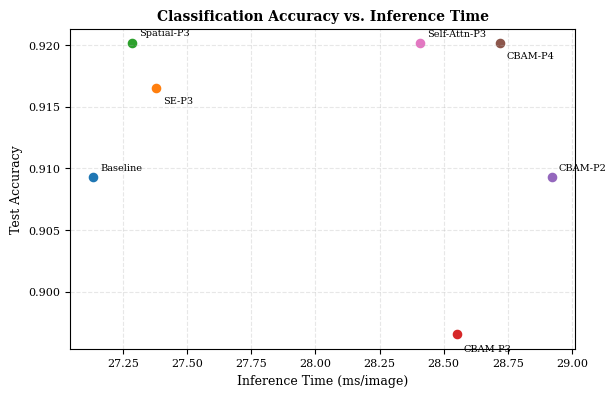

In [64]:

# ============================================================
# CELL 63 — FIX MODEL NAMES AND PLOT ALL SEVEN MODELS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# Standardized model names matching complexity_df
metrics_rows = [
    {"Model": "Baseline", "Accuracy": baseline_metrics["Accuracy"]},
    {"Model": "SE (P3)", "Accuracy": se_p3_metrics["Accuracy"]},
    {"Model": "Spatial (P3)", "Accuracy": spatial_p3_metrics["Accuracy"]},
    {"Model": "CBAM (P3)", "Accuracy": cbam_p3_metrics["Accuracy"]},
    {"Model": "CBAM (P2)", "Accuracy": cbam_p2_metrics["Accuracy"]},
    {"Model": "CBAM (P4)", "Accuracy": cbam_p4_metrics["Accuracy"]},
    {
        "Model": "Self-Attention (P3)",
        "Accuracy": self_attention_p3_metrics["Accuracy"]
    }
]

metrics_df = pd.DataFrame(metrics_rows)

# Merge using standardized model names
final_results_df = pd.merge(
    metrics_df,
    complexity_df[["Model", "Inference Time (ms/image)"]],
    on="Model",
    how="inner",
    validate="one_to_one"
)

print("Models included:", len(final_results_df))
display(final_results_df.round(4))

# Plot
fig, ax = plt.subplots(figsize=(6.2, 4.0))

short_names = {
    "Baseline": "Baseline",
    "SE (P3)": "SE-P3",
    "Spatial (P3)": "Spatial-P3",
    "CBAM (P3)": "CBAM-P3",
    "CBAM (P2)": "CBAM-P2",
    "CBAM (P4)": "CBAM-P4",
    "Self-Attention (P3)": "Self-Attn-P3"
}

offsets = [
    (5, 5), (5, -11), (5, 6), (5, -12),
    (5, 5), (5, -11), (5, 5)
]

for i, (_, row) in enumerate(final_results_df.iterrows()):
    x = row["Inference Time (ms/image)"]
    y = row["Accuracy"]

    ax.scatter(x, y, s=35)
    ax.annotate(
        short_names[row["Model"]],
        (x, y),
        xytext=offsets[i],
        textcoords="offset points",
        fontsize=7
    )

ax.set_title("Classification Accuracy vs. Inference Time", fontsize=10)
ax.set_xlabel("Inference Time (ms/image)", fontsize=9)
ax.set_ylabel("Test Accuracy", fontsize=9)
ax.tick_params(labelsize=8)
ax.grid(True, linestyle="--", alpha=0.3)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "accuracy_vs_inference_time.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
final_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "accuracy_inference_comparison.csv"),
    index=False
)

plt.show()
plt.close(fig)


CBAM results by attention position:


,Position,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,P2,ResNet50 + CBAM (P2),0.9093,0.9173,0.9071,0.9099
1,P3,ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970
2,P4,ResNet50 + CBAM (P4),0.9201,0.9215,0.9211,0.9210


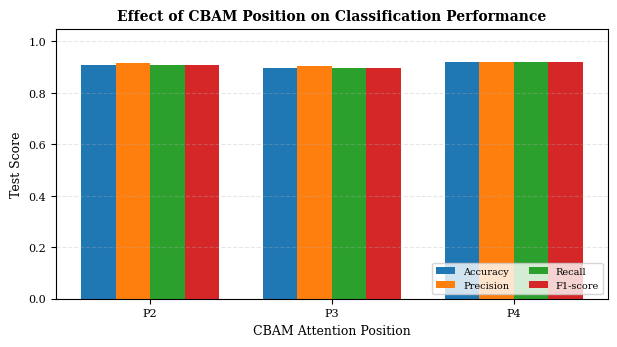

Saved CBAM position comparison.


In [65]:

# ============================================================
# CELL 64 — CBAM POSITION COMPARISON (P2, P3, P4)
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

position_df = pd.DataFrame([
    {"Position": "P2", **cbam_p2_metrics},
    {"Position": "P3", **cbam_p3_metrics},
    {"Position": "P4", **cbam_p4_metrics},
])

metric_columns = [
    ("Accuracy", "Accuracy"),
    ("Precision", "Precision (Macro)"),
    ("Recall", "Recall (Macro)"),
    ("F1-score", "F1-score (Macro)")
]

print("CBAM results by attention position:")
display(position_df.round(4))

fig, ax = plt.subplots(figsize=(6.2, 3.5))

x = range(len(position_df))
width = 0.19

for i, (label, column) in enumerate(metric_columns):
    ax.bar(
        [v + (i - 1.5) * width for v in x],
        position_df[column],
        width=width,
        label=label
    )

ax.set_xticks(list(x))
ax.set_xticklabels(position_df["Position"])
ax.set_xlabel("CBAM Attention Position", fontsize=9)
ax.set_ylabel("Test Score", fontsize=9)
ax.set_title("Effect of CBAM Position on Classification Performance",
             fontsize=10)
ax.set_ylim(0, 1.05)
ax.tick_params(labelsize=8)
ax.legend(fontsize=7, ncol=2, loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "cbam_position_comparison.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
position_df.to_csv(
    os.path.join(OUTPUT_DIR, "cbam_position_comparison.csv"),
    index=False
)

plt.show()
plt.close(fig)

print("Saved CBAM position comparison.")


In [66]:

# ============================================================
# CELL 65 — CHANNEL-FIRST VS SPATIAL-FIRST ATTENTION
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

def channel_attention_map(inputs, reduction=16, name="channel"):
    channels = int(inputs.shape[-1])

    avg_pool = layers.GlobalAveragePooling2D(
        name=f"{name}_avg_pool"
    )(inputs)
    max_pool = layers.GlobalMaxPooling2D(
        name=f"{name}_max_pool"
    )(inputs)

    shared_1 = layers.Dense(
        max(channels // reduction, 1),
        activation="relu",
        name=f"{name}_fc1"
    )
    shared_2 = layers.Dense(
        channels,
        name=f"{name}_fc2"
    )

    avg_out = shared_2(shared_1(avg_pool))
    max_out = shared_2(shared_1(max_pool))

    combined = layers.Add(name=f"{name}_add")([avg_out, max_out])
    weights = layers.Activation(
        "sigmoid", name=f"{name}_sigmoid"
    )(combined)

    weights = layers.Reshape(
        (1, 1, channels), name=f"{name}_reshape"
    )(weights)

    return layers.Multiply(name=f"{name}_multiply")(
        [inputs, weights]
    )


def spatial_attention_map(inputs, kernel_size=7, name="spatial"):
    avg_map = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True),
        name=f"{name}_avg"
    )(inputs)

    max_map = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True),
        name=f"{name}_max"
    )(inputs)

    combined = layers.Concatenate(
        axis=-1, name=f"{name}_concat"
    )([avg_map, max_map])

    weights = layers.Conv2D(
        1, kernel_size,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        name=f"{name}_conv"
    )(combined)

    return layers.Multiply(name=f"{name}_multiply")(
        [inputs, weights]
    )


def attention_order_block(inputs, order="channel_first", name="order"):
    if order == "channel_first":
        x = channel_attention_map(
            inputs, name=f"{name}_channel"
        )
        x = spatial_attention_map(
            x, name=f"{name}_spatial"
        )
    elif order == "spatial_first":
        x = spatial_attention_map(
            inputs, name=f"{name}_spatial"
        )
        x = channel_attention_map(
            x, name=f"{name}_channel"
        )
    else:
        raise ValueError("Unknown attention order")

    return x


print("Attention-order blocks defined.")


Attention-order blocks defined.


In [67]:

# ============================================================
# CELL 66 — BUILD ATTENTION-ORDER MODELS AT P3
# ============================================================

def build_attention_order_model(order, model_name):
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    # P3: output of conv4_x
    p3 = base.get_layer("conv4_block6_out").output

    x = attention_order_block(
        p3,
        order=order,
        name=model_name
    )

    # Reuse pretrained conv5_x residual blocks
    x = base.get_layer("conv5_block1_1_conv")(x)
    x = base.get_layer("conv5_block1_1_bn")(x)
    x = base.get_layer("conv5_block1_1_relu")(x)
    x = base.get_layer("conv5_block1_2_conv")(x)
    x = base.get_layer("conv5_block1_2_bn")(x)
    x = base.get_layer("conv5_block1_2_relu")(x)
    x = base.get_layer("conv5_block1_0_conv")(p3)
    x = base.get_layer("conv5_block1_0_bn")(x)

    # Rebuild block 1 correctly with its residual branch
    shortcut = x
    # Recompute the main branch from the attention output
    main = attention_order_block(
        p3,
        order=order,
        name=f"{model_name}_rebuild"
    )
    main = base.get_layer("conv5_block1_1_conv")(main)
    main = base.get_layer("conv5_block1_1_bn")(main)
    main = base.get_layer("conv5_block1_1_relu")(main)
    main = base.get_layer("conv5_block1_2_conv")(main)
    main = base.get_layer("conv5_block1_2_bn")(main)
    main = base.get_layer("conv5_block1_2_relu")(main)
    main = base.get_layer("conv5_block1_3_conv")(main)
    main = base.get_layer("conv5_block1_3_bn")(main)

    x = layers.Add(name=f"{model_name}_block1_add")(
        [main, shortcut]
    )
    x = base.get_layer("conv5_block1_out")(x)

    # Identity blocks 2 and 3
    for block_num in [2, 3]:
        prefix = f"conv5_block{block_num}"
        shortcut = x

        x = base.get_layer(f"{prefix}_1_conv")(x)
        x = base.get_layer(f"{prefix}_1_bn")(x)
        x = base.get_layer(f"{prefix}_1_relu")(x)
        x = base.get_layer(f"{prefix}_2_conv")(x)
        x = base.get_layer(f"{prefix}_2_bn")(x)
        x = base.get_layer(f"{prefix}_2_relu")(x)
        x = base.get_layer(f"{prefix}_3_conv")(x)
        x = base.get_layer(f"{prefix}_3_bn")(x)

        x = layers.Add(name=f"{model_name}_{prefix}_add")(
            [x, shortcut]
        )
        x = base.get_layer(f"{prefix}_out")(x)

    x = layers.GlobalAveragePooling2D(
        name=f"{model_name}_gap"
    )(x)
    x = layers.Dropout(
        BEST_DROPOUT,
        name=f"{model_name}_dropout"
    )(x)
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name=f"{model_name}_predictions"
    )(x)

    model = Model(
        inputs=base.input,
        outputs=outputs,
        name=model_name
    )

    model.compile(
        optimizer=make_optimizer(BEST_OPTIMIZER, BEST_LR),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


channel_first_model = build_attention_order_model(
    "channel_first", "channel_first_p3"
)

spatial_first_model = build_attention_order_model(
    "spatial_first", "spatial_first_p3"
)

print("Channel-first parameters:", channel_first_model.count_params())
print("Spatial-first parameters:", spatial_first_model.count_params())


Channel-first parameters: 23730215
Spatial-first parameters: 23730215


In [68]:

# ============================================================
# CELL 67 — TRAIN CHANNEL-FIRST AND SPATIAL-FIRST MODELS
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping

order_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=2
)

channel_first_history = channel_first_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=[order_early_stopping],
    verbose=2
)

# Create a fresh callback for the second model
order_early_stopping_2 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=2
)

spatial_first_history = spatial_first_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=[order_early_stopping_2],
    verbose=2
)

print("Both attention-order models have finished training.")


Epoch 1/10
322/322 - 32s - 99ms/step - accuracy: 0.7770 - loss: 0.6028 - val_accuracy: 0.8764 - val_loss: 0.3823
Epoch 2/10
322/322 - 12s - 36ms/step - accuracy: 0.8848 - loss: 0.3212 - val_accuracy: 0.8964 - val_loss: 0.2910
Epoch 3/10
322/322 - 12s - 36ms/step - accuracy: 0.9015 - loss: 0.2700 - val_accuracy: 0.9000 - val_loss: 0.3155
Epoch 4/10
322/322 - 11s - 36ms/step - accuracy: 0.9218 - loss: 0.2241 - val_accuracy: 0.9164 - val_loss: 0.2589
Epoch 5/10
322/322 - 11s - 36ms/step - accuracy: 0.9303 - loss: 0.1919 - val_accuracy: 0.9218 - val_loss: 0.2541
Epoch 6/10
322/322 - 11s - 35ms/step - accuracy: 0.9471 - loss: 0.1615 - val_accuracy: 0.9164 - val_loss: 0.2735
Epoch 7/10
322/322 - 11s - 35ms/step - accuracy: 0.9455 - loss: 0.1534 - val_accuracy: 0.9255 - val_loss: 0.2533
Epoch 8/10
322/322 - 11s - 35ms/step - accuracy: 0.9498 - loss: 0.1497 - val_accuracy: 0.9218 - val_loss: 0.2685
Epoch 9/10
322/322 - 11s - 36ms/step - accuracy: 0.9537 - loss: 0.1266 - val_accuracy: 0.9327 - 

In [69]:

# ============================================================
# CELL 68 — EVALUATE ATTENTION ORDER
# ============================================================

import numpy as np
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, classification_report

def evaluate_attention_order(model, model_name):
    y_true_local = []
    y_pred_local = []

    for images, labels in test_ds:
        probabilities = model(images, training=False).numpy()
        y_pred_local.extend(np.argmax(probabilities, axis=1))
        y_true_local.extend(np.argmax(labels.numpy(), axis=1))

    y_true_local = np.asarray(y_true_local)
    y_pred_local = np.asarray(y_pred_local)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true_local, y_pred_local),
        "Precision (Macro)": precision_score(
            y_true_local, y_pred_local, average="macro",
            zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true_local, y_pred_local, average="macro",
            zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true_local, y_pred_local, average="macro",
            zero_division=0
        )
    }

    print(f"\n{model_name}")
    print(classification_report(
        y_true_local,
        y_pred_local,
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    return metrics, y_true_local, y_pred_local


channel_first_metrics, y_true_cf, y_pred_cf = evaluate_attention_order(
    channel_first_model, "Channel → Spatial (P3)"
)

spatial_first_metrics, y_true_sf, y_pred_sf = evaluate_attention_order(
    spatial_first_model, "Spatial → Channel (P3)"
)

attention_order_df = pd.DataFrame([
    channel_first_metrics,
    spatial_first_metrics
])

print("\nAttention-order comparison:")
display(attention_order_df.round(4))



Channel → Spatial (P3)
              precision    recall  f1-score   support

   dandelion       0.91      0.98      0.94       112
       daisy       0.97      0.91      0.93        95
      tulips       0.89      0.92      0.90       134
  sunflowers       0.90      0.93      0.92       102
       roses       0.94      0.85      0.89       108

    accuracy                           0.92       551
   macro avg       0.92      0.92      0.92       551
weighted avg       0.92      0.92      0.92       551


Spatial → Channel (P3)
              precision    recall  f1-score   support

   dandelion       0.84      0.97      0.90       112
       daisy       0.97      0.81      0.89        95
      tulips       0.93      0.92      0.92       134
  sunflowers       0.90      0.94      0.92       102
       roses       0.95      0.92      0.93       108

    accuracy                           0.91       551
   macro avg       0.92      0.91      0.91       551
weighted avg       0.92      

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Channel → Spatial (P3),0.9183,0.9220,0.9177,0.9189
1,Spatial → Channel (P3),0.9147,0.9201,0.9119,0.9134


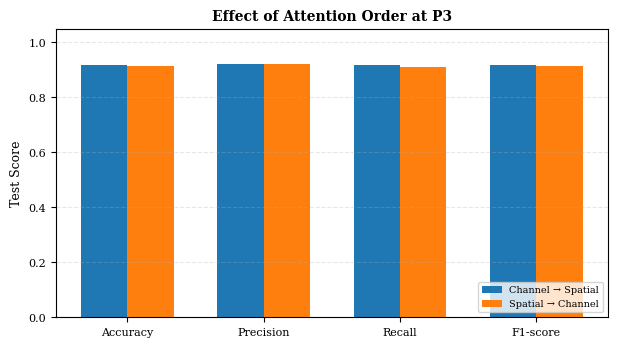

Saved attention-order comparison in EPS and SVG formats.


In [70]:

# ============================================================
# CELL 69 — ATTENTION ORDER PERFORMANCE COMPARISON
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

metrics_to_plot = [
    ("Accuracy", "Accuracy"),
    ("Precision", "Precision (Macro)"),
    ("Recall", "Recall (Macro)"),
    ("F1-score", "F1-score (Macro)")
]

fig, ax = plt.subplots(figsize=(6.2, 3.5))

x = np.arange(len(metrics_to_plot))
width = 0.34

channel_values = [
    channel_first_metrics[column]
    for _, column in metrics_to_plot
]
spatial_values = [
    spatial_first_metrics[column]
    for _, column in metrics_to_plot
]

ax.bar(
    x - width / 2,
    channel_values,
    width,
    label="Channel → Spatial"
)
ax.bar(
    x + width / 2,
    spatial_values,
    width,
    label="Spatial → Channel"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [label for label, _ in metrics_to_plot],
    fontsize=8
)
ax.set_ylabel("Test Score", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title("Effect of Attention Order at P3", fontsize=10)
ax.tick_params(axis="y", labelsize=8)
ax.legend(fontsize=7, loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout(pad=0.8)

fig.savefig(
    os.path.join(OUTPUT_DIR, "attention_order_comparison.eps"),
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
attention_order_df.to_csv(
    os.path.join(OUTPUT_DIR, "attention_order_comparison.csv"),
    index=False
)

plt.show()
plt.close(fig)

print("Saved attention-order comparison in EPS and SVG formats.")


In [71]:

# ============================================================
# CELL 70 — SPATIAL ATTENTION WITH DIFFERENT KERNEL SIZES
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers

def spatial_attention_kernel_block(inputs, kernel_size=7, name="spatial_kernel"):
    avg_map = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True),
        name=f"{name}_avg"
    )(inputs)

    max_map = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True),
        name=f"{name}_max"
    )(inputs)

    combined = layers.Concatenate(
        axis=-1,
        name=f"{name}_concat"
    )([avg_map, max_map])

    attention_weights = layers.Conv2D(
        filters=1,
        kernel_size=kernel_size,
        strides=1,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        name=f"{name}_{kernel_size}x{kernel_size}_conv"
    )(combined)

    attended = layers.Multiply(
        name=f"{name}_multiply"
    )([inputs, attention_weights])

    return attended


print("Spatial kernel attention block defined.")
print("Kernel sizes to compare: 3x3, 5x5, 7x7")


Spatial kernel attention block defined.
Kernel sizes to compare: 3x3, 5x5, 7x7


In [72]:
# Build the spatial-kernel model

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

def build_kernel_model(kernel_size):
    model_name = f"spatial_kernel_{kernel_size}"
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    x = spatial_attention_kernel_block(
        base.get_layer("conv4_block6_out").output,
        kernel_size=kernel_size,
        name=model_name
    )

    shortcut = base.get_layer("conv5_block1_0_conv")(x)
    shortcut = base.get_layer("conv5_block1_0_bn")(shortcut)
    main = base.get_layer("conv5_block1_1_conv")(x)
    main = base.get_layer("conv5_block1_1_bn")(main)
    main = base.get_layer("conv5_block1_1_relu")(main)
    main = base.get_layer("conv5_block1_2_conv")(main)
    main = base.get_layer("conv5_block1_2_bn")(main)
    main = base.get_layer("conv5_block1_2_relu")(main)
    main = base.get_layer("conv5_block1_3_conv")(main)
    main = base.get_layer("conv5_block1_3_bn")(main)
    x = layers.Add(name=f"{model_name}_block1_add")([main, shortcut])
    x = base.get_layer("conv5_block1_out")(x)

    for block_num in [2, 3]:
        prefix = f"conv5_block{block_num}"
        shortcut = x
        main = base.get_layer(f"{prefix}_1_conv")(x)
        main = base.get_layer(f"{prefix}_1_bn")(main)
        main = base.get_layer(f"{prefix}_1_relu")(main)
        main = base.get_layer(f"{prefix}_2_conv")(main)
        main = base.get_layer(f"{prefix}_2_bn")(main)
        main = base.get_layer(f"{prefix}_2_relu")(main)
        main = base.get_layer(f"{prefix}_3_conv")(main)
        main = base.get_layer(f"{prefix}_3_bn")(main)
        x = layers.Add(name=f"{model_name}_{prefix}_add")([main, shortcut])
        x = base.get_layer(f"{prefix}_out")(x)

    x = layers.GlobalAveragePooling2D(name=f"{model_name}_gap")(x)
    x = layers.Dropout(BEST_DROPOUT, name=f"{model_name}_dropout")(x)
    outputs = layers.Dense(
        NUM_CLASSES, activation="softmax", name=f"{model_name}_predictions"
    )(x)

    model = Model(base.input, outputs, name=model_name)
    model.compile(
        optimizer=make_optimizer(BEST_OPTIMIZER, BEST_LR),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [73]:
# Train kernel sizes sequentially with checkpoints

import gc
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

CHECKPOINT_DIR = Path(OUTPUT_DIR) / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
KERNEL_SIZES = [3, 5, 7]
KERNEL_EPOCHS = FINAL_EPOCHS
results_path = Path(OUTPUT_DIR) / "kernel_size_results.csv"

kernel_histories = {}
kernel_results = []
kernel_predictions = {}

if results_path.exists():
    previous = pd.read_csv(results_path)
    completed = set(previous["Kernel Size"].astype(str))
    kernel_results = previous.to_dict("records")
else:
    completed = set()

for kernel_size in KERNEL_SIZES:
    label = f"{kernel_size}x{kernel_size}"
    checkpoint_path = CHECKPOINT_DIR / f"spatial_kernel_{kernel_size}_best.weights.h5"
    history_path = CHECKPOINT_DIR / f"spatial_kernel_{kernel_size}_history.json"

    if label in completed and checkpoint_path.exists():
        print(f"Skipping completed {label}; checkpoint and metrics already exist.")
        continue

    tf.keras.backend.clear_session()
    gc.collect()
    model = build_kernel_model(kernel_size)

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=2
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=2
        )
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=KERNEL_EPOCHS,
        callbacks=callbacks,
        verbose=2
    )
    model.load_weights(str(checkpoint_path))

    y_true_kernel, y_pred_kernel = [], []
    for images, labels in test_ds:
        probs = model(images, training=False).numpy()
        y_true_kernel.extend(tf.argmax(labels, axis=1).numpy())
        y_pred_kernel.extend(tf.argmax(probs, axis=1).numpy())

    y_true_kernel, y_pred_kernel = np.asarray(y_true_kernel), np.asarray(y_pred_kernel)
    kernel_predictions[kernel_size] = (y_true_kernel, y_pred_kernel)
    kernel_histories[kernel_size] = {
        key: list(values) for key, values in history.history.items()
    }
    history_path.write_text(json.dumps(kernel_histories[kernel_size]), encoding="utf-8")

    kernel_results = [row for row in kernel_results if row.get("Kernel Size") != label]
    kernel_results.append({
        "Kernel Size": label,
        "Accuracy": accuracy_score(y_true_kernel, y_pred_kernel),
        "Precision (Macro)": precision_score(y_true_kernel, y_pred_kernel, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_true_kernel, y_pred_kernel, average="macro", zero_division=0),
        "F1-score (Macro)": f1_score(y_true_kernel, y_pred_kernel, average="macro", zero_division=0)
    })
    pd.DataFrame(kernel_results).to_csv(results_path, index=False)
    print(f"{label} test accuracy: {kernel_results[-1]['Accuracy']:.4f}")

    del model, history
    tf.keras.backend.clear_session()
    gc.collect()

display(pd.DataFrame(kernel_results).sort_values("Kernel Size").round(4))

mem_report("after kernel-size experiment")


Epoch 1/10

Epoch 1: val_loss improved from None to 0.48873, saving model to /kaggle/working/lab8_plots/checkpoints/spatial_kernel_3_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/lab8_plots/checkpoints/spatial_kernel_3_best.weights.h5
322/322 - 31s - 97ms/step - accuracy: 0.4640 - loss: 1.2465 - val_accuracy: 0.8218 - val_loss: 0.4887
Epoch 2/10

Epoch 2: val_loss improved from 0.48873 to 0.34672, saving model to /kaggle/working/lab8_plots/checkpoints/spatial_kernel_3_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/lab8_plots/checkpoints/spatial_kernel_3_best.weights.h5
322/322 - 13s - 39ms/step - accuracy: 0.8533 - loss: 0.3994 - val_accuracy: 0.8782 - val_loss: 0.3467
Epoch 3/10

Epoch 3: val_loss improved from 0.34672 to 0.30172, saving model to /kaggle/working/lab8_plots/checkpoints/spatial_kernel_3_best.weights.h5

Epoch 3: finished saving model to /kaggle/working/lab8_plots/checkpoints/spatial_kernel_3_best.weights.h5
322/322 - 13s - 39ms/s

,Kernel Size,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,3x3,0.9129,0.9199,0.9106,0.9135
1,5x5,0.8984,0.9072,0.8963,0.8988
2,7x7,0.9020,0.9105,0.8998,0.9019


[after kernel-size experiment] process RAM: 12.09 GB of 33.7 GB | GPU current 2.95 GB, peak 6.97 GB


In [74]:
# Review kernel-size results

import pandas as pd
from pathlib import Path

kernel_results_path = Path(OUTPUT_DIR) / "kernel_size_results.csv"
if kernel_results_path.exists():
    kernel_results_df = pd.read_csv(kernel_results_path)
    display(kernel_results_df.round(4))
else:
    print("Run the kernel-size training cell first.")

,Kernel Size,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,3x3,0.9129,0.9199,0.9106,0.9135
1,5x5,0.8984,0.9072,0.8963,0.8988
2,7x7,0.9020,0.9105,0.8998,0.9019


In [75]:

# Train spatial-attention kernel sizes sequentially

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

CHECKPOINT_DIR = Path(OUTPUT_DIR) / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

KERNEL_SIZES = [3, 5, 7]
KERNEL_EPOCHS = FINAL_EPOCHS
RESULTS_PATH = Path(OUTPUT_DIR) / "kernel_size_results.csv"

kernel_results = []
kernel_histories = {}

# Load existing results when continuing an interrupted run
if RESULTS_PATH.exists():
    kernel_results = pd.read_csv(RESULTS_PATH).to_dict("records")

completed = {
    str(row["Kernel Size"])
    for row in kernel_results
}

for kernel_size in KERNEL_SIZES:
    label = f"{kernel_size}x{kernel_size}"
    checkpoint_path = (
        CHECKPOINT_DIR
        / f"spatial_kernel_{kernel_size}_best.weights.h5"
    )
    history_path = (
        CHECKPOINT_DIR
        / f"spatial_kernel_{kernel_size}_history.json"
    )

    # Reuse a completed result only if its checkpoint exists
    if label in completed and checkpoint_path.exists():
        print(f"Already completed: {label}")
        continue

    tf.keras.backend.clear_session()
    gc.collect()

    model = build_kernel_model(kernel_size)

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=2
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=2
        )
    ]

    try:
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=KERNEL_EPOCHS,
            callbacks=callbacks,
            verbose=2
        )

        # Evaluate the best saved model weights
        model.load_weights(str(checkpoint_path))

        y_true_kernel, y_pred_kernel = [], []

        for images, labels in test_ds:
            probabilities = model(images, training=False).numpy()
            y_true_kernel.extend(tf.argmax(labels, axis=1).numpy())
            y_pred_kernel.extend(tf.argmax(probabilities, axis=1).numpy())

        metrics = {
            "Kernel Size": label,
            "Accuracy": accuracy_score(y_true_kernel, y_pred_kernel),
            "Precision (Macro)": precision_score(
                y_true_kernel, y_pred_kernel, average="macro", zero_division=0
            ),
            "Recall (Macro)": recall_score(
                y_true_kernel, y_pred_kernel, average="macro", zero_division=0
            ),
            "F1-score (Macro)": f1_score(
                y_true_kernel, y_pred_kernel, average="macro", zero_division=0
            )
        }

        kernel_results = [
            row for row in kernel_results
            if str(row.get("Kernel Size")) != label
        ]
        kernel_results.append(metrics)

        # Persist results immediately after each successful kernel
        pd.DataFrame(kernel_results).to_csv(
            RESULTS_PATH, index=False
        )

        history_data = {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        }
        history_path.write_text(
            json.dumps(history_data, indent=2),
            encoding="utf-8"
        )
        kernel_histories[kernel_size] = history_data

        print(f"{label} results:", metrics)

    finally:
        # Release references held by this training cell
        if "history" in locals():
            del history
        del model
        tf.keras.backend.clear_session()
        gc.collect()

display(
    pd.DataFrame(kernel_results)
    .sort_values("Kernel Size")
    .round(4)
)


Already completed: 3x3
Already completed: 5x5
Already completed: 7x7


,Kernel Size,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,3x3,0.9129,0.9199,0.9106,0.9135
1,5x5,0.8984,0.9072,0.8963,0.8988
2,7x7,0.9020,0.9105,0.8998,0.9019


In [76]:
required = [
    "cbam_block",
    "make_optimizer",
    "IMG_SIZE",
    "NUM_CLASSES",
    "BEST_DROPOUT",
    "BEST_OPTIMIZER",
    "BEST_LR",
    "FINAL_EPOCHS",
    "train_ds",
    "val_ds",
]

for name in required:
    print(f"{name}: {'OK' if name in globals() else 'MISSING'}")

cbam_block: OK
make_optimizer: OK
IMG_SIZE: OK
NUM_CLASSES: OK
BEST_DROPOUT: OK
BEST_OPTIMIZER: OK
BEST_LR: OK
FINAL_EPOCHS: OK
train_ds: OK
val_ds: OK


In [77]:

# ============================================================
# CELL 75 — BUILD MULTI-STAGE CBAM (P3 + P4)
# ============================================================
IMG_SIZE = 224
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dropout, Dense, Add
)
from tensorflow.keras.applications import ResNet50

# Frozen pretrained backbone
base_multi = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_multi.trainable = False

# P3: Apply CBAM after conv4_x
x = base_multi.get_layer("conv4_block6_out").output
x = cbam_block(x, name="multi_p3_cbam")

# Reuse pretrained conv5_x stage after P3 attention
shortcut = base_multi.get_layer("conv5_block1_0_conv")(x)
shortcut = base_multi.get_layer("conv5_block1_0_bn")(shortcut)

residual = base_multi.get_layer("conv5_block1_1_conv")(x)
residual = base_multi.get_layer("conv5_block1_1_bn")(residual)
residual = base_multi.get_layer("conv5_block1_1_relu")(residual)

residual = base_multi.get_layer("conv5_block1_2_conv")(residual)
residual = base_multi.get_layer("conv5_block1_2_bn")(residual)
residual = base_multi.get_layer("conv5_block1_2_relu")(residual)

residual = base_multi.get_layer("conv5_block1_3_conv")(residual)
residual = base_multi.get_layer("conv5_block1_3_bn")(residual)

x = Add(name="multi_conv5_block1_add")([shortcut, residual])
x = base_multi.get_layer("conv5_block1_out")(x)

# Remaining identity blocks of conv5_x
for block in [2, 3]:
    residual = base_multi.get_layer(
        f"conv5_block{block}_1_conv"
    )(x)
    residual = base_multi.get_layer(
        f"conv5_block{block}_1_bn"
    )(residual)
    residual = base_multi.get_layer(
        f"conv5_block{block}_1_relu"
    )(residual)

    residual = base_multi.get_layer(
        f"conv5_block{block}_2_conv"
    )(residual)
    residual = base_multi.get_layer(
        f"conv5_block{block}_2_bn"
    )(residual)
    residual = base_multi.get_layer(
        f"conv5_block{block}_2_relu"
    )(residual)

    residual = base_multi.get_layer(
        f"conv5_block{block}_3_conv"
    )(residual)
    residual = base_multi.get_layer(
        f"conv5_block{block}_3_bn"
    )(residual)

    x = Add(name=f"multi_conv5_block{block}_add")(
        [x, residual]
    )
    x = base_multi.get_layer(
        f"conv5_block{block}_out"
    )(x)

# P4: Apply a second CBAM after conv5_x
x = cbam_block(x, name="multi_p4_cbam")

x = GlobalAveragePooling2D(name="multi_gap")(x)
x = Dropout(BEST_DROPOUT, name="multi_dropout")(x)
outputs = Dense(
    NUM_CLASSES, activation="softmax", name="multi_predictions"
)(x)

multi_stage_model = Model(
    inputs=base_multi.input,
    outputs=outputs,
    name="resnet50_cbam_p3_p4"
)

multi_stage_model.compile(
    optimizer=make_optimizer(BEST_OPTIMIZER, BEST_LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Multi-stage CBAM model built.")
print("Input shape:", multi_stage_model.input_shape)
print("Output shape:", multi_stage_model.output_shape)
print("Total parameters:", f"{multi_stage_model.count_params():,}")
print(
    "Trainable parameters:",
    f"{sum(tf.size(v).numpy() for v in multi_stage_model.trainable_weights):,}"
)


Multi-stage CBAM model built.
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 24,256,777
Trainable parameters: 669,065


In [78]:
# List everything saved for this run (visible in the Output tab)
from pathlib import Path

root = Path(OUTPUT_DIR)
print("Saved files under", root)
for p in sorted(root.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(root)}  ({p.stat().st_size/1e6:.2f} MB)")


Saved files under /kaggle/working/lab8_plots
accuracy_f1_comparison.eps  (0.02 MB)
accuracy_inference_comparison.csv  (0.00 MB)
accuracy_vs_inference_time.eps  (0.04 MB)
all_model_performance_comparison.eps  (0.04 MB)
all_model_performance_comparison.svg  (0.05 MB)
all_models_confusion_matrices.eps  (0.12 MB)
attention_order_comparison.csv  (0.00 MB)
attention_order_comparison.eps  (0.03 MB)
attention_type_comparison.csv  (0.00 MB)
attention_type_comparison.eps  (0.04 MB)
baseline_accuracy.eps  (0.03 MB)
baseline_confusion_matrix.eps  (1.89 MB)
baseline_loss.eps  (0.03 MB)
baseline_se_spatial_comparison.eps  (0.04 MB)
baseline_se_spatial_comparison.svg  (0.05 MB)
baseline_vs_se_p3.eps  (0.03 MB)
baseline_vs_se_p3.svg  (0.04 MB)
cbam_p3_accuracy.eps  (0.04 MB)
cbam_p3_confusion_matrix.eps  (1.62 MB)
cbam_p3_loss.eps  (0.03 MB)
cbam_position_comparison.csv  (0.00 MB)
cbam_position_comparison.eps  (0.04 MB)
checkpoints/spatial_kernel_3_best.weights.h5  (94.93 MB)
checkpoints/spatial_kerne

In [79]:
# ============================================================
# CELL 76 — TRAIN MULTI-STAGE CBAM (P3 + P4)
# ============================================================

import gc
import csv
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    CSVLogger
)

# Saved under /kaggle/working so it appears in the Output tab
SAVE_DIR = Path(OUTPUT_DIR) / "multi_stage_cbam"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

BEST_WEIGHTS = SAVE_DIR / "multi_stage_cbam_best.weights.h5"
HISTORY_CSV = SAVE_DIR / "multi_stage_cbam_history.csv"

# Do NOT clear the session here:
# multi_stage_model was already built in Cell 75.

callbacks = [
    ModelCheckpoint(
        filepath=str(BEST_WEIGHTS),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=2
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=2
    ),
    CSVLogger(
        filename=str(HISTORY_CSV),
        append=True
    )
]

multi_stage_history = multi_stage_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINAL_EPOCHS,
    callbacks=callbacks,
    verbose=2
)

multi_stage_history_dict = {
    key: list(values)
    for key, values in multi_stage_history.history.items()
}

print("\nMulti-stage CBAM training completed.")
print("Best weights:", BEST_WEIGHTS)
print("History:", HISTORY_CSV)
print("Weights file size:",
      f"{BEST_WEIGHTS.stat().st_size:,} bytes"
      if BEST_WEIGHTS.exists() else "Not saved")

mem_report("after multi-stage training")


Epoch 1/10

Epoch 1: val_loss improved from None to 0.97819, saving model to /kaggle/working/lab8_plots/multi_stage_cbam/multi_stage_cbam_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/lab8_plots/multi_stage_cbam/multi_stage_cbam_best.weights.h5
322/322 - 35s - 109ms/step - accuracy: 0.2892 - loss: 1.5502 - val_accuracy: 0.7127 - val_loss: 0.9782
Epoch 2/10

Epoch 2: val_loss improved from 0.97819 to 0.36271, saving model to /kaggle/working/lab8_plots/multi_stage_cbam/multi_stage_cbam_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/lab8_plots/multi_stage_cbam/multi_stage_cbam_best.weights.h5
322/322 - 13s - 39ms/step - accuracy: 0.7988 - loss: 0.5554 - val_accuracy: 0.8582 - val_loss: 0.3627
Epoch 3/10

Epoch 3: val_loss improved from 0.36271 to 0.29997, saving model to /kaggle/working/lab8_plots/multi_stage_cbam/multi_stage_cbam_best.weights.h5

Epoch 3: finished saving model to /kaggle/working/lab8_plots/multi_stage_cbam/multi_stage_cbam_best.we

In [80]:

# ============================================================
# CELL 77 — EVALUATE P3, P4, AND P3+P4 ATTENTION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_attention_model(model, model_name):
    y_true_local = []
    y_pred_local = []

    for images, labels in test_ds:
        probabilities = model(images, training=False).numpy()

        y_true_local.extend(
            np.argmax(labels.numpy(), axis=1)
        )
        y_pred_local.extend(
            np.argmax(probabilities, axis=1)
        )

    y_true_local = np.asarray(y_true_local)
    y_pred_local = np.asarray(y_pred_local)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true_local, y_pred_local),
        "Precision (Macro)": precision_score(
            y_true_local, y_pred_local,
            average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true_local, y_pred_local,
            average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true_local, y_pred_local,
            average="macro", zero_division=0
        )
    }

    return metrics, y_true_local, y_pred_local


multi_stage_metrics, y_true_multi, y_pred_multi = (
    evaluate_attention_model(
        multi_stage_model, "CBAM (P3+P4)"
    )
)

multi_stage_results = pd.DataFrame([
    {
        "Model": "CBAM (P3)",
        "Accuracy": cbam_p3_metrics["Accuracy"],
        "Precision (Macro)": cbam_p3_metrics["Precision (Macro)"],
        "Recall (Macro)": cbam_p3_metrics["Recall (Macro)"],
        "F1-score (Macro)": cbam_p3_metrics["F1-score (Macro)"]
    },
    {
        "Model": "CBAM (P4)",
        "Accuracy": cbam_p4_metrics["Accuracy"],
        "Precision (Macro)": cbam_p4_metrics["Precision (Macro)"],
        "Recall (Macro)": cbam_p4_metrics["Recall (Macro)"],
        "F1-score (Macro)": cbam_p4_metrics["F1-score (Macro)"]
    },
    multi_stage_metrics
])

display(multi_stage_results.round(4))

multi_stage_results.to_csv(
    os.path.join(OUTPUT_DIR, "multi_stage_attention_results.csv"),
    index=False
)

print("Saved multi-stage attention results.")


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,CBAM (P3),0.8966,0.9040,0.8958,0.8970
1,CBAM (P4),0.9201,0.9215,0.9211,0.9210
2,CBAM (P3+P4),0.9129,0.9156,0.9121,0.9128


Saved multi-stage attention results.


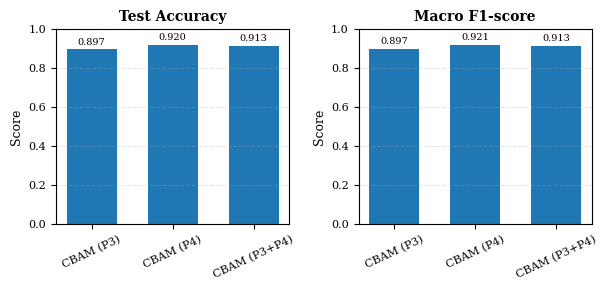

Saved multi_stage_attention_comparison.eps and .svg


In [81]:

# ============================================================
# CELL 78 — MULTI-STAGE ATTENTION COMPARISON PLOT
# ============================================================

import os
import matplotlib.pyplot as plt
import numpy as np

# Use the results generated in Cell 77
plot_df = multi_stage_results.copy()

fig, axes = plt.subplots(1, 2, figsize=(6.2, 3.0))

plot_metrics = [
    ("Accuracy", "Test Accuracy"),
    ("F1-score (Macro)", "Macro F1-score")
]

for ax, (metric, title) in zip(axes, plot_metrics):
    bars = ax.bar(
        plot_df["Model"],
        plot_df[metric],
        width=0.62
    )

    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Score", fontsize=9)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelrotation=25, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    for bar, value in zip(bars, plot_df[metric]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=7
        )

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "multi_stage_attention_comparison.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()

print("Saved multi_stage_attention_comparison.eps and .svg")


In [82]:

# ============================================================
# CELL 79 — CHECK ATTENTION-ORDER EXPERIMENT STATUS
# ============================================================

required_variables = [
    "attention_order_models",
    "attention_order_histories",
    "attention_order_results"
]

for variable_name in required_variables:
    print(
        f"{variable_name}:",
        "Available" if variable_name in globals() else "Not available"
    )

# Check common alternative variable names from earlier cells
for variable_name in [
    "channel_spatial_model",
    "spatial_channel_model",
    "channel_spatial_history",
    "spatial_channel_history",
    "attention_order_model_cs",
    "attention_order_model_sc"
]:
    if variable_name in globals():
        print(f"{variable_name}: available")

if "attention_order_models" in globals():
    for name, model in attention_order_models.items():
        print(
            f"{name}: input={model.input_shape}, "
            f"output={model.output_shape}, "
            f"parameters={model.count_params():,}"
        )

if "attention_order_histories" in globals():
    print(
        "Saved attention-order histories:",
        list(attention_order_histories.keys())
    )


attention_order_models: Not available
attention_order_histories: Not available
attention_order_results: Not available


In [83]:

# ============================================================
# CELL 80 — EXPERIMENT AND OUTPUT AUDIT
# ============================================================

import os
import pandas as pd

print("=" * 55)
print("LAB 8 EXPERIMENT AUDIT")
print("=" * 55)

# Check result tables
for variable_name in [
    "kernel_results_df",
    "multi_stage_results",
    "comparison_df",
    "position_df",
    "complexity_df"
]:
    print(f"\n{variable_name}:")

    if variable_name in globals():
        value = globals()[variable_name]

        if isinstance(value, pd.DataFrame):
            display(value.round(4))
        else:
            print("Available, but not a DataFrame.")
    else:
        print("Not available in the current runtime.")

# List saved report figures and CSV files
print("\n" + "=" * 55)
print("SAVED OUTPUT FILES")
print("=" * 55)

if os.path.isdir(OUTPUT_DIR):
    output_files = sorted(os.listdir(OUTPUT_DIR))

    for filename in output_files:
        filepath = os.path.join(OUTPUT_DIR, filename)

        if os.path.isfile(filepath):
            size_kb = os.path.getsize(filepath) / 1024
            print(f"{filename}  ({size_kb:.1f} KB)")

    print(f"\nTotal files: {len(output_files)}")
else:
    print("Output directory does not exist:", OUTPUT_DIR)


LAB 8 EXPERIMENT AUDIT

kernel_results_df:


,Kernel Size,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,3x3,0.9129,0.9199,0.9106,0.9135
1,5x5,0.8984,0.9072,0.8963,0.8988
2,7x7,0.9020,0.9105,0.8998,0.9019



multi_stage_results:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,CBAM (P3),0.8966,0.9040,0.8958,0.8970
1,CBAM (P4),0.9201,0.9215,0.9211,0.9210
2,CBAM (P3+P4),0.9129,0.9156,0.9121,0.9128



comparison_df:


...


position_df:


,Position,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,P2,ResNet50 + CBAM (P2),0.9093,0.9173,0.9071,0.9099
1,P3,ResNet50 + CBAM (P3),0.8966,0.9040,0.8958,0.8970
2,P4,ResNet50 + CBAM (P4),0.9201,0.9215,0.9211,0.9210



complexity_df:


,Model,Total Parameters,Trainable Parameters,Inference Time (ms/image)
0,Baseline,23597957,10245,27.1341
1,SE (P3),23730117,142405,27.3780
2,Spatial (P3),23598055,10343,27.2857
3,CBAM (P3),23730215,142503,28.5518
4,CBAM (P2),23631367,43655,28.9214
5,CBAM (P4),24124519,536807,28.7191
6,Self-Attention (P3),24123653,535941,28.4089



SAVED OUTPUT FILES
accuracy_f1_comparison.eps  (23.1 KB)
accuracy_inference_comparison.csv  (0.4 KB)
accuracy_vs_inference_time.eps  (43.1 KB)
all_model_performance_comparison.eps  (38.8 KB)
all_model_performance_comparison.svg  (51.2 KB)
all_models_confusion_matrices.eps  (120.3 KB)
attention_order_comparison.csv  (0.3 KB)
attention_order_comparison.eps  (31.2 KB)
attention_type_comparison.csv  (0.4 KB)
attention_type_comparison.eps  (39.8 KB)
baseline_accuracy.eps  (26.2 KB)
baseline_confusion_matrix.eps  (1845.6 KB)
baseline_loss.eps  (28.0 KB)
baseline_se_spatial_comparison.eps  (34.4 KB)
baseline_se_spatial_comparison.svg  (48.6 KB)
baseline_vs_se_p3.eps  (29.5 KB)
baseline_vs_se_p3.svg  (41.7 KB)
cbam_p3_accuracy.eps  (38.0 KB)
cbam_p3_confusion_matrix.eps  (1585.9 KB)
cbam_p3_loss.eps  (33.3 KB)
cbam_position_comparison.csv  (0.4 KB)
cbam_position_comparison.eps  (34.5 KB)
dataset_samples.eps  (14269.7 KB)
final_consolidated_results.csv  (0.5 KB)
final_consolidated_results.tex 

In [84]:

# ============================================================
# CELL 81 — CHANNEL ATTENTION WEIGHT VISUALIZATION
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Use the first test batch
sample_images, sample_labels = next(iter(test_ds))
sample_image = sample_images[:1]

def find_channel_attention_layer(model):
    """Find a layer that outputs channel-wise attention weights."""
    candidates = []

    for layer in model.layers:
        name = layer.name.lower()

        # SE block commonly uses a sigmoid Dense layer.
        # CBAM commonly has channel-attention pooling/MLP layers.
        if "channel" in name and (
            "sigmoid" in name or "scale" in name or "attention" in name
        ):
            try:
                if len(layer.output.shape) == 4:
                    candidates.append(layer)
            except Exception:
                pass

    return candidates

print("SE model candidate layers:")
print([layer.name for layer in find_channel_attention_layer(se_p3_model)])

print("\nCBAM model candidate layers:")
print([layer.name for layer in find_channel_attention_layer(cbam_p3_model)])

print(
    "\nLayer discovery completed. "
    "We will use the actual attention-layer names in the next cell."
)


SE model candidate layers:
[]

CBAM model candidate layers:
[]

Layer discovery completed. We will use the actual attention-layer names in the next cell.


SE candidate: se_p3_squeeze
CBAM candidate: cbam_p3_channel_avg_pool


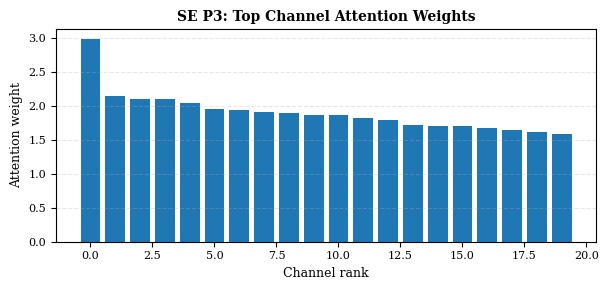

Saved se_p3_channel_weights.eps and se_p3_channel_weights.svg


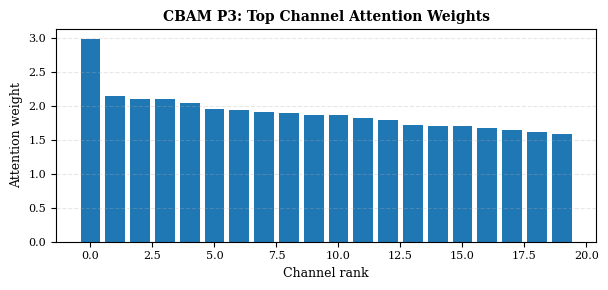

Saved cbam_p3_channel_weights.eps and cbam_p3_channel_weights.svg


In [85]:

# ============================================================
# CELL 82 — PLOT CHANNEL-ATTENTION WEIGHTS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def find_weight_layer(model, keywords):
    for layer in model.layers:
        name = layer.name.lower()

        if any(keyword in name for keyword in keywords):
            try:
                shape = tuple(layer.output.shape)

                # Channel attention often has shape (B, 1, 1, C)
                # or (B, C).
                if len(shape) == 4 and shape[1] == 1 and shape[2] == 1:
                    return layer
                if len(shape) == 2:
                    return layer
            except Exception:
                continue

    return None


def plot_channel_weights(model, layer, title, filename):
    if layer is None:
        print(f"Could not automatically locate the weight layer for {title}.")
        return

    try:
        weight_model = tf.keras.Model(
            inputs=model.inputs,
            outputs=layer.output
        )

        sample_images, _ = next(iter(test_ds))
        weights = weight_model(sample_images[:1], training=False).numpy()
        weights = np.asarray(weights).reshape(-1)

        # Plot the 20 most strongly weighted channels
        top_indices = np.argsort(weights)[-20:][::-1]
        top_weights = weights[top_indices]

        fig, ax = plt.subplots(figsize=(6.2, 3.0))
        ax.bar(range(len(top_indices)), top_weights)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Channel rank", fontsize=9)
        ax.set_ylabel("Attention weight", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", linestyle="--", alpha=0.3)

        plt.tight_layout()
        plt.savefig(
            os.path.join(OUTPUT_DIR, filename + ".eps"),
            format="eps", dpi=600, bbox_inches="tight"
        )
        plt.savefig(
            os.path.join(OUTPUT_DIR, filename + ".svg"),
            format="svg", bbox_inches="tight"
        )
        plt.show()

        print(f"Saved {filename}.eps and {filename}.svg")

    except Exception as error:
        print(f"Could not plot {title}: {error}")


# Search common layer-name patterns
se_weight_layer = find_weight_layer(
    se_p3_model,
    ["se", "channel"]
)

cbam_weight_layer = find_weight_layer(
    cbam_p3_model,
    ["channel", "cbam"]
)

print(
    "SE candidate:",
    se_weight_layer.name if se_weight_layer else "Not found"
)
print(
    "CBAM candidate:",
    cbam_weight_layer.name if cbam_weight_layer else "Not found"
)

plot_channel_weights(
    se_p3_model,
    se_weight_layer,
    "SE P3: Top Channel Attention Weights",
    "se_p3_channel_weights"
)

plot_channel_weights(
    cbam_p3_model,
    cbam_weight_layer,
    "CBAM P3: Top Channel Attention Weights",
    "cbam_p3_channel_weights"
)


In [86]:
# `find_backbone` was used below but never defined in the original notebook.
def find_backbone(model):
    """Return the nested ResNet50 (a tf.keras.Model) inside a model."""
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            return layer
    return None

# Build the baseline Grad-CAM feature model

baseline_backbone = find_backbone(baseline_model)
if baseline_backbone is None:
    raise ValueError("Could not find the ResNet50 backbone inside baseline_model.")

baseline_feature_name = "conv5_block3_out"
baseline_feature_model = tf.keras.Model(
    inputs=baseline_backbone.input,
    outputs=[
        baseline_backbone.get_layer(baseline_feature_name).output,
        baseline_backbone.output
    ],
    name="baseline_feature_model"
)
print("Baseline feature model created:", baseline_feature_name)

Baseline feature model created: conv5_block3_out


In [87]:

# ============================================================
# CELL 84 — FINAL ATTENTION-TYPE AND POSITION RESULTS TABLE
# ============================================================

import os
import pandas as pd

experiment_rows = []

def add_metrics_row(name, metrics):
    """Append metrics using the keys available in the result dictionary."""
    row = {"Model": name}

    key_aliases = {
        "Accuracy": ["Accuracy", "accuracy"],
        "Precision (Macro)": [
            "Precision (Macro)", "Precision", "Macro Precision"
        ],
        "Recall (Macro)": [
            "Recall (Macro)", "Recall", "Macro Recall"
        ],
        "F1-score (Macro)": [
            "F1-score (Macro)", "F1", "Macro F1"
        ]
    }

    for output_key, candidates in key_aliases.items():
        value = next(
            (metrics[key] for key in candidates if key in metrics),
            float("nan")
        )
        row[output_key] = value

    experiment_rows.append(row)


# Core attention-type comparison
for name, variable_name in [
    ("Baseline ResNet50", "baseline_metrics"),
    ("SE (P3)", "se_p3_metrics"),
    ("Spatial Attention (P3)", "spatial_p3_metrics"),
    ("CBAM (P3)", "cbam_p3_metrics"),
    ("Self-Attention (P3)", "self_attention_p3_metrics")
]:
    if variable_name in globals():
        add_metrics_row(name, globals()[variable_name])

# Attention-position comparison
for name, variable_name in [
    ("CBAM (P2)", "cbam_p2_metrics"),
    ("CBAM (P4)", "cbam_p4_metrics")
]:
    if variable_name in globals():
        add_metrics_row(name, globals()[variable_name])

# Multi-stage attention
if "multi_stage_metrics" in globals():
    add_metrics_row("CBAM (P3+P4)", multi_stage_metrics)

final_attention_results_df = pd.DataFrame(experiment_rows)

display(final_attention_results_df.round(4))

csv_path = os.path.join(
    OUTPUT_DIR, "final_attention_experiment_results.csv"
)
final_attention_results_df.to_csv(csv_path, index=False)

print("Saved:", csv_path)
print("Models included:", len(final_attention_results_df))


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Baseline ResNet50,0.9093,0.9173,0.9086,0.9107
1,SE (P3),0.9165,0.9200,0.9167,0.9169
2,Spatial Attention (P3),0.9201,0.9248,0.9185,0.9204
3,CBAM (P3),0.8966,0.9040,0.8958,0.8970
4,Self-Attention (P3),0.9201,0.9230,0.9195,0.9203
5,CBAM (P2),0.9093,0.9173,0.9071,0.9099
6,CBAM (P4),0.9201,0.9215,0.9211,0.9210
7,CBAM (P3+P4),0.9129,0.9156,0.9121,0.9128


Saved: /kaggle/working/lab8_plots/final_attention_experiment_results.csv
Models included: 8


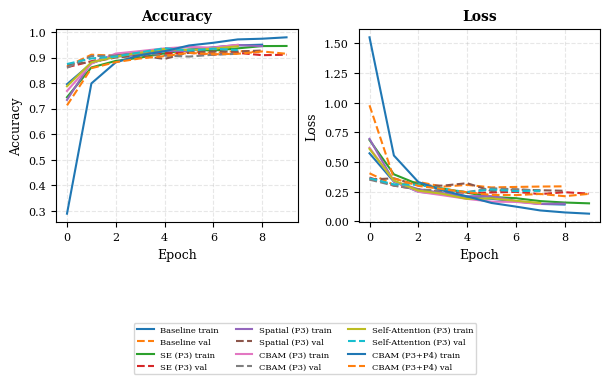

Saved combined training/validation curves.


In [88]:

# ============================================================
# CELL 85 — COMBINED TRAINING AND VALIDATION CURVES
# ============================================================

import os
import matplotlib.pyplot as plt

# Add available histories without retraining
histories_to_plot = {}

if "baseline_history" in globals():
    histories_to_plot["Baseline"] = baseline_history.history

if "se_p3_history" in globals():
    histories_to_plot["SE (P3)"] = se_p3_history.history

if "spatial_p3_history" in globals():
    histories_to_plot["Spatial (P3)"] = spatial_p3_history.history

if "cbam_p3_history" in globals():
    histories_to_plot["CBAM (P3)"] = cbam_p3_history.history

if "self_attention_p3_history" in globals():
    histories_to_plot["Self-Attention (P3)"] = (
        self_attention_p3_history.history
    )

# Cell 76 stores this history as a dictionary
if "multi_stage_history_dict" in globals():
    histories_to_plot["CBAM (P3+P4)"] = multi_stage_history_dict

if not histories_to_plot:
    raise ValueError(
        "No training histories found. Check the history variable names."
    )

fig, axes = plt.subplots(1, 2, figsize=(6.2, 3.2))

for model_name, history in histories_to_plot.items():
    if "accuracy" in history:
        axes[0].plot(
            history["accuracy"],
            label=f"{model_name} train"
        )

    if "val_accuracy" in history:
        axes[0].plot(
            history["val_accuracy"],
            linestyle="--",
            label=f"{model_name} val"
        )

    if "loss" in history:
        axes[1].plot(
            history["loss"],
            label=f"{model_name} train"
        )

    if "val_loss" in history:
        axes[1].plot(
            history["val_loss"],
            linestyle="--",
            label=f"{model_name} val"
        )

axes[0].set_title("Accuracy", fontsize=10)
axes[0].set_xlabel("Epoch", fontsize=9)
axes[0].set_ylabel("Accuracy", fontsize=9)

axes[1].set_title("Loss", fontsize=10)
axes[1].set_xlabel("Epoch", fontsize=9)
axes[1].set_ylabel("Loss", fontsize=9)

for ax in axes:
    ax.tick_params(labelsize=8)
    ax.grid(linestyle="--", alpha=0.3)

# Shared legend below the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    fontsize=6
)

plt.tight_layout(rect=[0, 0.12, 1, 1])

plt.savefig(
    os.path.join(OUTPUT_DIR, "combined_training_validation_curves.eps"),
    format="eps", dpi=600, bbox_inches="tight"
)
plt.show()

print("Saved combined training/validation curves.")


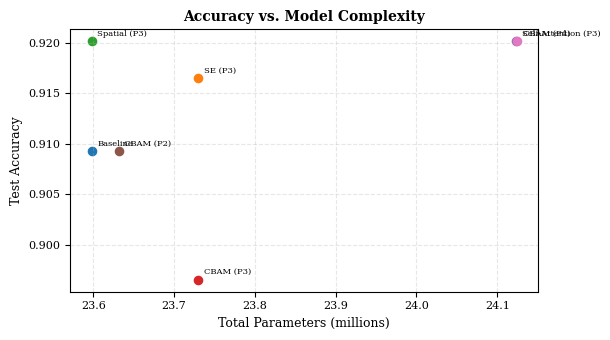

Saved accuracy_vs_model_complexity.eps and .svg


In [89]:

# ============================================================
# CELL 86 — ACCURACY VS MODEL COMPLEXITY
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# Match model names explicitly to avoid missing parameter values
model_name_map = {
    "Baseline ResNet50": "Baseline",
    "SE (P3)": "SE (P3)",
    "Spatial Attention (P3)": "Spatial (P3)",
    "CBAM (P3)": "CBAM (P3)",
    "CBAM (P2)": "CBAM (P2)",
    "CBAM (P4)": "CBAM (P4)",
    "Self-Attention (P3)": "Self-Attention (P3)",
    "CBAM (P3+P4)": "CBAM (P3+P4)"
}

if "final_attention_results_df" not in globals():
    raise ValueError("Run Cell 84 first to create final_attention_results_df.")

if "complexity_df" not in globals():
    raise ValueError("complexity_df is missing. Run the model profiling cell first.")

accuracy_df = final_attention_results_df.copy()
accuracy_df["Complexity Model"] = accuracy_df["Model"].map(model_name_map)

complexity_subset = complexity_df[
    ["Model", "Total Parameters"]
].drop_duplicates("Model")

accuracy_df = accuracy_df.merge(
    complexity_subset,
    left_on="Complexity Model",
    right_on="Model",
    how="inner",
    suffixes=("", "_complexity")
)

if accuracy_df.empty:
    print("No matching model names were found.")
    print("Accuracy model names:", final_attention_results_df["Model"].tolist())
    print("Complexity model names:", complexity_df["Model"].tolist())
else:
    fig, ax = plt.subplots(figsize=(6.2, 3.5))

    for _, row in accuracy_df.iterrows():
        ax.scatter(
            row["Total Parameters"] / 1e6,
            row["Accuracy"],
            s=35
        )
        ax.annotate(
            row["Complexity Model"],
            (row["Total Parameters"] / 1e6, row["Accuracy"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=6
        )

    ax.set_xlabel("Total Parameters (millions)", fontsize=9)
    ax.set_ylabel("Test Accuracy", fontsize=9)
    ax.set_title("Accuracy vs. Model Complexity", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(linestyle="--", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, "accuracy_vs_model_complexity.eps"),
        format="eps", dpi=600, bbox_inches="tight"
    )
    plt.show()

    print("Saved accuracy_vs_model_complexity.eps and .svg")


## Kaggle runtime and checkpoint checklist

- Session options: **GPU accelerator ON** and **Internet ON** before running.
- The first cell limits TensorFlow to one GPU with on-demand memory allocation; run it before any model is created.
- The data pipeline streams from disk (no in-RAM shuffle buffer), uses batch size 8 and `.prefetch(1)`.
- Evaluation uses direct model calls instead of per-batch `predict`, and training logs are one line per epoch.
- `mem_report("tag")` prints process RAM and GPU memory; call it anywhere to check usage.
- Experiment 5 trains 3x3, 5x5 and 7x7 kernel models sequentially, saving per-kernel checkpoints and histories under `OUTPUT_DIR/checkpoints`; an interrupted run resumes from `kernel_size_results.csv`.
- All outputs go to `/kaggle/working/lab8_plots`; the final cell bundles figures and tables into `/kaggle/working/lab8_results_bundle.zip` (weights `.h5` files are excluded to keep the bundle small).
- Run experiments in order, then the evaluation/visualization cells and the final ZIP cell.
- Model training and GPU memory behavior must be verified by executing the notebook on Kaggle.


In [90]:

# Package plots and result tables

from pathlib import Path
import zipfile

output_dir = Path(OUTPUT_DIR)
zip_path = Path(WORK_DIR) / "lab8_results_bundle.zip"
included = {".eps", ".png", ".csv", ".txt", ".json", ".tex"}

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file in output_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in included:
            archive.write(file, arcname=file.relative_to(output_dir))

print(f"Saved {zip_path.resolve()} ({zip_path.stat().st_size:,} bytes)")


Saved /kaggle/working/lab8_results_bundle.zip (7,658,106 bytes)


Predicting with Baseline...
Predicting with Channel attention...
Predicting with Spatial attention...
Predicting with Channel + spatial...
Predicting with Self-attention...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_540']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Grad-CAM extraction fallback for ResNet50_SE_P3: "Exception encountered when calling Functional.call().\n\n\x1b139090579600432\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[ -99.64848  , -116.48848  , -123.68     ],\n         [-101.63543  , -116.779    , -123.68     ],\n         [-101.939    , -116.779    , -123.68     ],\n         ...,\n         [ -93.6957   ,  -79.53569  ,  -95.4367   ],\n         [ -92.182304 ,  -80.29239  ,  -95.68     ],\n         [ -92.238785 ,  -79.8992   ,  -95.4367   ]],\n\n        [[ -99.939    , -116.779    , -123.68     ],\n         [-101.63543  , -116.779    , -123.68     ],\n         [-101.939    , -116.779    , -123.68     ],\n         ...,\n         [ -91.537834 ,  -77.37782  ,  -93.27883  ],\n         [ -91.58998  ,  -76.47847  ,  -95.56921  ],\n         [ -92.44121  ,  -74.2433   ,  -93.95009  ]],\n\n        [[-100.904366 , -116.779    , -123.68     ],\n         [-101.50597  , -116.779    , -123.68     ],\n         [-101.50597 

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_803']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Grad-CAM extraction fallback for ResNet50_CBAM_P3: Attempt to convert a value (None) with an unsupported type (<class 'NoneType'>) to a Tensor.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_757']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['self_attention_input']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


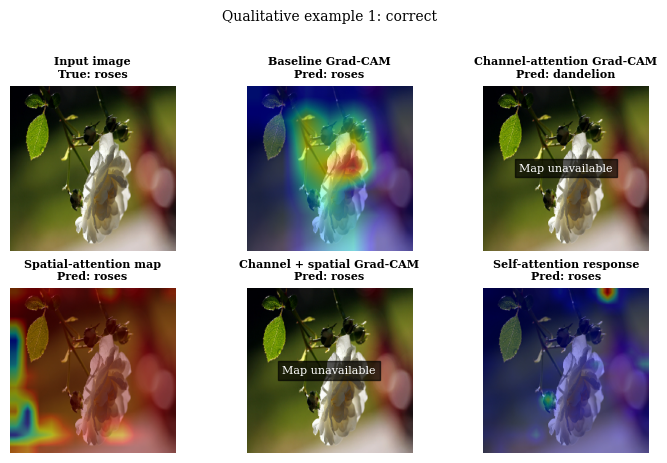

Saved: /kaggle/working/lab8_plots/qualitative_correct_1.eps
Grad-CAM extraction fallback for ResNet50_SE_P3: "Exception encountered when calling Functional.call().\n\n\x1b139090579600432\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[-16.483704  , -26.475487  ,  55.391365  ],\n         [-12.916687  , -19.346146  ,  55.36947   ],\n         [ -8.92308   , -14.763077  ,  57.72625   ],\n         ...,\n         [ 43.060997  ,  45.27427   ,  84.37327   ],\n         [ 41.58985   ,  44.008583  ,  81.21937   ],\n         [ 42.57006   ,  42.221     ,  79.73528   ]],\n\n        [[-17.345253  , -29.18525   ,  54.304558  ],\n         [-16.240883  , -24.266151  ,  54.32      ],\n         [-12.6193695 , -19.651772  ,  56.469566  ],\n         ...,\n         [ 45.913246  ,  46.311623  ,  83.331154  ],\n         [ 44.09278   ,  44.252785  ,  83.35178   ],\n         [ 44.07215   ,  44.232155  ,  83.331154  ]],\n\n        [[-21.115639  , -33.481827  ,  51.406456  ],\n         [-16.8

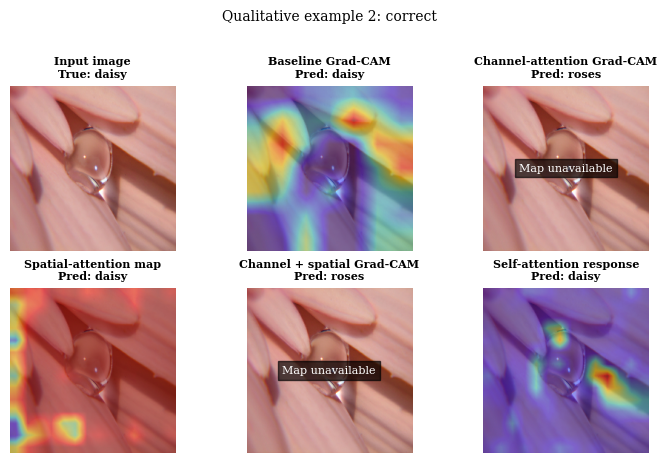

Saved: /kaggle/working/lab8_plots/qualitative_correct_2.eps
Grad-CAM extraction fallback for ResNet50_SE_P3: "Exception encountered when calling Functional.call().\n\n\x1b139090579600432\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[-55.62953 , -29.091698, -71.75763 ],\n         [-47.09599 , -34.47589 , -70.12629 ],\n         [-54.134434, -29.79586 , -72.04532 ],\n         ...,\n         [-15.280785, -19.400772, -17.350891],\n         [-13.798103, -17.898941, -18.14653 ],\n         [-19.742584, -17.017754, -21.249413]],\n\n        [[-50.854042, -29.61039 , -68.3687  ],\n         [-50.3091  , -28.537926, -68.29517 ],\n         [-49.64133 , -28.995514, -68.86975 ],\n         ...,\n         [-13.82888 , -16.229889, -16.964958],\n         [-17.290367, -16.463829, -21.14653 ],\n         [-23.129051, -15.149536, -23.219612]],\n\n        [[-50.27753 , -29.121513, -66.75962 ],\n         [-49.919632, -29.029694, -66.02295 ],\n         [-49.794952, -26.330856, -70.59175 ]

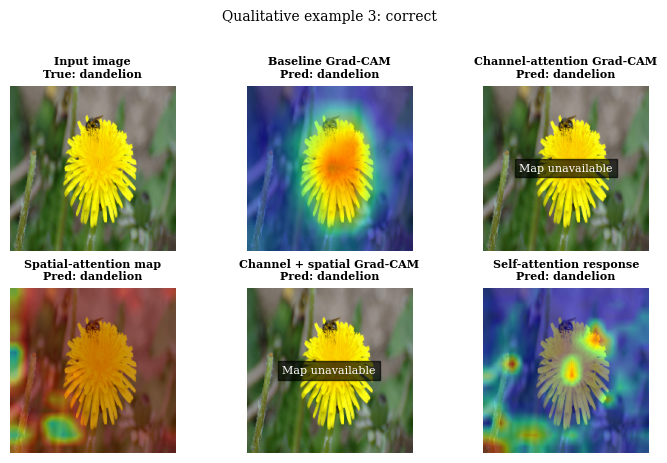

Saved: /kaggle/working/lab8_plots/qualitative_correct_3.eps
Grad-CAM extraction fallback for ResNet50_SE_P3: "Exception encountered when calling Functional.call().\n\n\x1b139090579600432\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[-103.63627 , -112.77621 , -123.296074],\n         [-102.83884 , -111.79742 , -123.46125 ],\n         [-102.514336, -111.35433 , -123.25533 ],\n         ...,\n         [ -60.017136,  -25.65873 ,  -74.265945],\n         [ -56.28836 ,  -25.512268,  -69.1817  ],\n         [ -58.33631 ,  -21.496017,  -70.074524]],\n\n        [[-103.21133 , -112.85992 , -123.54803 ],\n         [-102.396034, -111.89228 , -121.82453 ],\n         [-101.91138 , -111.40762 , -121.339874],\n         ...,\n         [ -58.538357,  -29.09401 ,  -74.81169 ],\n         [ -56.314003,  -21.50666 ,  -67.78266 ],\n         [ -54.373447,  -16.070557,  -62.914078]],\n\n        [[-103.84525 , -114.765884, -123.56448 ],\n         [-103.721924, -113.64144 , -122.38341 ],\n   

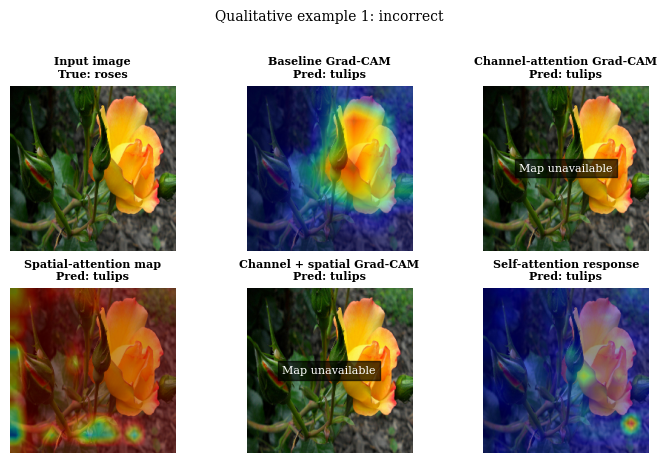

Saved: /kaggle/working/lab8_plots/qualitative_incorrect_1.eps
Grad-CAM extraction fallback for ResNet50_SE_P3: "Exception encountered when calling Functional.call().\n\n\x1b139090579600432\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[ 106.98957  ,   70.149574 ,   33.248573 ],\n         [ 106.98957  ,   70.149574 ,   33.248573 ],\n         [ 107.005745 ,   70.16575  ,   33.264748 ],\n         ...,\n         [  95.51412  ,   56.674126 ,    9.773125 ],\n         [  94.08834  ,   55.248344 ,    8.347343 ],\n         [  92.09672  ,   53.25672  ,    6.3557205]],\n\n        [[ 104.95385  ,   68.11385  ,   31.212852 ],\n         [ 105.02584  ,   68.185844 ,   31.284843 ],\n         [ 105.51412  ,   68.674126 ,   31.773125 ],\n         ...,\n         [  95.572716 ,   56.625572 ,   10.045998 ],\n         [  94.54705  ,   55.599907 ,    9.020332 ],\n         [  93.275276 ,   54.328148 ,    7.7485733]],\n\n        [[ 104.23957  ,   67.399574 ,   30.498573 ],\n         [ 10

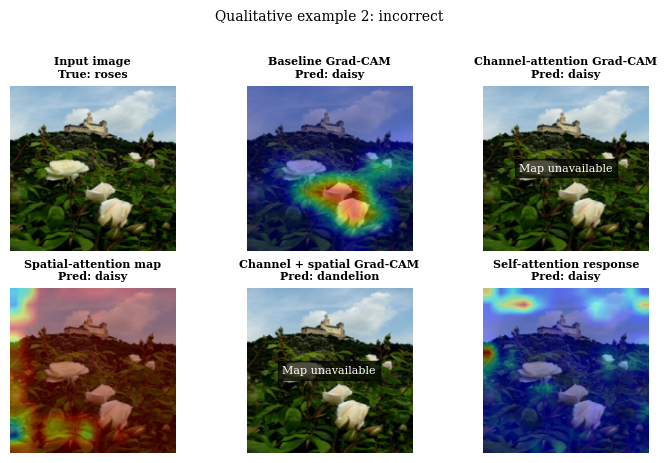

Saved: /kaggle/working/lab8_plots/qualitative_incorrect_2.eps


,Test index,Selection,True class,Baseline prediction,Channel attention prediction,Spatial attention prediction,Channel + spatial prediction,Self-attention prediction
0,0,correct_by_baseline,roses,roses,dandelion,roses,roses,roses
1,1,correct_by_baseline,daisy,daisy,roses,daisy,roses,daisy
2,2,correct_by_baseline,dandelion,dandelion,dandelion,dandelion,dandelion,dandelion
3,8,baseline_misclassified_or_model_error,roses,tulips,tulips,tulips,tulips,tulips
4,24,baseline_misclassified_or_model_error,roses,daisy,daisy,daisy,dandelion,daisy


All five qualitative comparison figures generated.


In [91]:

# ============================================================
# CELL 92 — QUALITATIVE COMPARISON ACROSS ATTENTION MECHANISMS
# Generates the five figures required for Section 30 of the report.
# Run only after all five models have been trained/evaluated.
# Saves report-ready EPS figures only (no duplicate SVG files).
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

os.makedirs(OUTPUT_DIR, exist_ok=True)

QUALITATIVE_MODELS = [
    ("Baseline", baseline_model),
    ("Channel attention", se_p3_model),
    ("Spatial attention", spatial_p3_model),
    ("Channel + spatial", cbam_p3_model),
    ("Self-attention", self_attention_p3_model),
]

# Gather test images and predictions once; do not retrain any model.
qual_images, qual_labels = [], []
for batch_images, batch_labels in test_ds:
    qual_images.append(batch_images.numpy())
    qual_labels.append(np.argmax(batch_labels.numpy(), axis=1))

qual_images = np.concatenate(qual_images, axis=0)
qual_labels = np.concatenate(qual_labels, axis=0)

qual_predictions = {}
for model_name, model in QUALITATIVE_MODELS:
    print(f"Predicting with {model_name}...")
    probs = model.predict(qual_images, batch_size=32, verbose=0)
    qual_predictions[model_name] = np.argmax(probs, axis=1)

# Select 3 images correctly classified by the baseline and 2 that it
# misclassifies. If the baseline has fewer than 2 errors, use images
# misclassified by at least one model for the incorrect examples.
base_pred = qual_predictions["Baseline"]
correct_idx = np.where(base_pred == qual_labels)[0].tolist()
incorrect_idx = np.where(base_pred != qual_labels)[0].tolist()

selected_correct = correct_idx[:3]
selected_incorrect = incorrect_idx[:2]

if len(selected_incorrect) < 2:
    any_error = np.where(
        np.any(
            np.stack([
                qual_predictions[name] != qual_labels
                for name, _ in QUALITATIVE_MODELS
            ], axis=0),
            axis=0
        )
    )[0].tolist()
    selected_incorrect = (selected_incorrect + [
        idx for idx in any_error if idx not in selected_incorrect
    ])[:2]

if len(selected_correct) < 3:
    raise ValueError(
        "Could not find three baseline-correct test images. "
        "Check that test_ds and baseline_model are available."
    )
if len(selected_incorrect) < 2:
    raise ValueError(
        "Could not find two misclassified examples across the evaluated models."
    )

# Convert ResNet50 preprocess_input output back to displayable RGB.
def _qual_to_rgb(preprocessed):
    rgb = np.asarray(preprocessed).astype(np.float32).copy()
    rgb += np.array([103.939, 116.779, 123.68], dtype=np.float32)
    rgb = rgb[..., ::-1]
    return np.clip(rgb, 0, 255).astype(np.uint8)

def _qual_normalize_map(arr):
    arr = np.asarray(arr, dtype=np.float32)
    arr = np.squeeze(arr)
    if arr.ndim != 2:
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)
    arr = np.maximum(arr, 0)
    maximum = float(arr.max())
    if maximum > 0:
        arr = arr / maximum
    return arr

def _qual_resize_map(arr, height=IMG_SIZE, width=IMG_SIZE):
    arr = _qual_normalize_map(arr)
    resized = tf.image.resize(
        arr[..., np.newaxis], (height, width), method="bilinear"
    ).numpy().squeeze()
    return np.clip(resized, 0, 1)

def _qual_find_layer(model, name_fragments):
    """Find a matching layer in the model or a nested Keras model."""
    candidates = []
    def visit(container):
        for layer in getattr(container, "layers", []):
            lname = layer.name.lower()
            if any(fragment in lname for fragment in name_fragments):
                candidates.append(layer)
            if isinstance(layer, tf.keras.Model):
                visit(layer)
    visit(model)
    # Prefer maps/weights/convolution layers over generic parent names.
    candidates.sort(
        key=lambda layer: (
            0 if any(s in layer.name.lower()
                     for s in ("weights", "spatial_conv", "sigmoid")) else 1,
            len(layer.name)
        )
    )
    return candidates[0] if candidates else None

def _qual_attention_map(model, image, fragments, kind="spatial"):
    layer = _qual_find_layer(model, fragments)
    if layer is None:
        return None
    try:
        extractor = tf.keras.Model(model.inputs, layer.output)
        values = extractor(image, training=False).numpy()
        values = np.asarray(values[0])
        # Self-attention matrix: (positions, positions). Summarize attention
        # received by each spatial position, then reshape to the feature grid.
        if values.ndim == 2 and values.shape[0] == values.shape[1]:
            side = int(np.sqrt(values.shape[0]))
            if side * side == values.shape[0]:
                values = values.mean(axis=0).reshape(side, side)
            else:
                return None
        elif values.ndim == 3:
            # (H, W, C): average channels for a spatial map
            values = np.mean(values, axis=-1)
        elif values.ndim == 1:
            return None
        return _qual_normalize_map(values)
    except Exception as exc:
        print(f"Attention-map extraction skipped for {layer.name}: {exc}")
        return None

def _qual_gradcam(image, model):
    # Reuse the Grad-CAM function defined earlier in the notebook.
    try:
        heatmap, _ = make_gradcam_heatmap(
            image, model, last_conv_name="conv5_block3_out"
        )
        return _qual_normalize_map(heatmap)
    except Exception as exc:
        print(f"Grad-CAM extraction fallback for {model.name}: {exc}")
        return None

def _qual_overlay(ax, rgb, heatmap, title):
    ax.imshow(rgb)
    if heatmap is not None:
        ax.imshow(
            _qual_resize_map(heatmap, rgb.shape[0], rgb.shape[1]),
            cmap="jet", alpha=0.42, vmin=0, vmax=1
        )
    else:
        ax.text(
            0.5, 0.5, "Map unavailable",
            transform=ax.transAxes, ha="center", va="center",
            color="white", fontsize=8,
            bbox={"facecolor": "black", "alpha": 0.65, "pad": 3}
        )
    ax.set_title(title, fontsize=8)
    ax.axis("off")

def _qual_make_figure(dataset_index, figure_number, status):
    image = qual_images[dataset_index:dataset_index + 1]
    true_class = int(qual_labels[dataset_index])
    rgb = _qual_to_rgb(image[0])

    # Maps are computed from each model's own prediction/class score.
    base_map = _qual_gradcam(image, baseline_model)
    channel_map = _qual_gradcam(image, se_p3_model)
    cbam_map = _qual_gradcam(image, cbam_p3_model)
    spatial_map = _qual_attention_map(
        spatial_p3_model, image,
        ["spatial_attention", "spatial_p3", "spatial_conv"],
        kind="spatial"
    )
    if spatial_map is None:
        spatial_map = _qual_gradcam(image, spatial_p3_model)

    self_map = _qual_attention_map(
        self_attention_p3_model,
        image,
        ["self_attention_p3_weights", "self_attention_weights"],
        kind="self"
    )
    if self_map is None:
        # If the internal attention matrix cannot be exposed by this
        # Keras graph, still provide a valid model-specific Grad-CAM.
        self_map = _qual_gradcam(image, self_attention_p3_model)
        self_title = "Self-attention Grad-CAM"
    else:
        self_title = "Self-attention response"

    # 2x3 grid keeps labels readable and fits more easily into an A4 report.
    fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.6))
    axes = axes.ravel()
    axes[0].imshow(rgb)
    axes[0].set_title(
        f"Input image\nTrue: {CLASS_NAMES[true_class]}",
        fontsize=8
    )
    axes[0].axis("off")

    _qual_overlay(
        axes[1], rgb, base_map,
        f"Baseline Grad-CAM\nPred: {CLASS_NAMES[int(qual_predictions['Baseline'][dataset_index])]}"
    )
    _qual_overlay(
        axes[2], rgb, channel_map,
        f"Channel-attention Grad-CAM\nPred: {CLASS_NAMES[int(qual_predictions['Channel attention'][dataset_index])]}"
    )
    _qual_overlay(
        axes[3], rgb, spatial_map,
        f"Spatial-attention map\nPred: {CLASS_NAMES[int(qual_predictions['Spatial attention'][dataset_index])]}"
    )
    _qual_overlay(
        axes[4], rgb, cbam_map,
        f"Channel + spatial Grad-CAM\nPred: {CLASS_NAMES[int(qual_predictions['Channel + spatial'][dataset_index])]}"
    )
    _qual_overlay(
        axes[5], rgb, self_map,
        f"{self_title}\nPred: {CLASS_NAMES[int(qual_predictions['Self-attention'][dataset_index])]}"
    )

    fig.suptitle(
        f"Qualitative example {figure_number}: {status}",
        fontsize=10
    )
    fig.tight_layout(rect=[0, 0, 1, 0.94], pad=0.5)

    filename = f"qualitative_{status.lower()}_{figure_number}.eps"
    out_path = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(out_path, format="eps", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out_path)

for number, idx in enumerate(selected_correct, start=1):
    _qual_make_figure(idx, number, "correct")

for number, idx in enumerate(selected_incorrect, start=1):
    _qual_make_figure(idx, number, "incorrect")

# Save the selected example index/class/prediction summary for reproducibility.
qualitative_rows = []
for status, indices in [
    ("correct_by_baseline", selected_correct),
    ("baseline_misclassified_or_model_error", selected_incorrect)
]:
    for idx in indices:
        row = {
            "Test index": int(idx),
            "Selection": status,
            "True class": CLASS_NAMES[int(qual_labels[idx])]
        }
        for model_name, _ in QUALITATIVE_MODELS:
            row[f"{model_name} prediction"] = CLASS_NAMES[
                int(qual_predictions[model_name][idx])
            ]
        qualitative_rows.append(row)

import pandas as pd
qualitative_summary_df = pd.DataFrame(qualitative_rows)
display(qualitative_summary_df)
qualitative_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "qualitative_example_predictions.csv"),
    index=False
)
print("All five qualitative comparison figures generated.")
